# 04 — Плейлистовый EDA

## Вопрос ноутбука

Как устроена коллекция плейлистов пользователя? Из чего она собрана, как наполнялась, что в ней слушается, а что осталось мёртвым грузом.

Четыре уровня. Структура: типы плейлистов (**personal**, **collaborative**, **contributed**, **foreign**) и как они меняются во времени. Содержание: жанры, аудио-характеристики, пересечения между типами. Наполнение: **mass_import**, **batch**, **curated**, их связь с активностью и повторами. Ядро вкуса: кластеризация добавленного и прослушанного за последние шесть кварталов.

## Срезы

**df_events** — весь поток событий с флагом **valid_play**. Аналог базы **all**. Нужен там, где важно прослушивание как факт: активность, повторы, ядро вкуса.

**playlist_links** — связи трек–плейлист с датами добавления и тем, кто добавил. Основной срез для классификации по типам и наполнению.

**playlists_metadata** — метаданные плейлистов: владелец, тип, число треков, дата обновления.

**tracks_exportify** — аудио-характеристики и жанры. Присоединяется по `spotify_track_uri`.

**track_dates** — даты первого добавления трека в библиотеку и в свои плейлисты. Для анализа первого появления и пути повторов.

**owner_ids** — маскированные владельцы. Источник для ролей в блоке 4.

## Связь с другими частями проекта

Дашборд (`03_dashboard/`) использует канонические базы из `src/bases.py`. Здесь работа идёт на своих срезах — **df_events** и **playlist_links**, — потому что ноутбук писался раньше дашборда. Функции из `bases.py` не подключаются.

Кластеризация ядра вкуса в блоке 9 — ранняя версия (шесть признаков с **tempo**, одно окно, **cosine similarity**). Финальная версия — в `src/clustering/`: пять признаков без **tempo**, три окна (**global**, **recent_6q**, **last_90d**), евклидово расстояние, порог `MIN_SILHOUETTE = 0.25`. Там же сохранение в parquet для дашборда.

## Ограничения ноутбука

Выборка — история одного человека. Выводы описывают этот профиль, не слушателей вообще.

Жанровый анализ ограничен долей **unknown**. В отдельных срезах она доходит до 40%.

Пороги классификации — **mass_import** (один день, ≥100 треков, ≤15 минут, <30% прослушано до добавления), **batch** (интервал ≤2 минуты), **curated** (одиночное добавление или разрыв >2 минут), подгруппы **curated** (CV 0.5 и 1.5), группы активности (30 и 365 дней) — эвристики, не выведенные из данных.

`days_since_update` считается от максимальной `last_modified` в датасете, а не от даты сбора. Оценка заброшенности смещена вверх.

**Valid_play** требует `played_frac ≥ 0.5`. Метрики вовлечённости, посчитанные по этому фильтру, смещены к высоким значениям.

Правый край истории обрезан: 2026 неполный. Когорты в блоках 6.7 и 6.8 малы.

Все сравнения проходят без поправки на множественные сравнения. Часть значимых различий может быть ложноположительной.

Маскирование ID выполнено в блоке 0. Все имена и идентификаторы заменены на **account_N** и **user_NN**.

# Блок 0. Подготовка

## Блок 0. Подготовка

Блок загружает шесть таблиц, маскирует идентификаторы, проверяет обязательные колонки и целостность связей. Вводит **valid_play** — фильтр валидного прослушивания. Определяет вспомогательные функции для жанрового анализа.

Срез — все таблицы. Единица анализа — не применимо.

**Маскирование** — замена идентификаторов до анализа: **owner_id** → **account_N**, **display_name** → **Account N**, **Added By** → **account_N** или **user_NN**. Восстановление исходных значений невозможно. Все дальнейшие блоки работают только с маскированными данными.

**name_norm** — нормализованное имя плейлиста: нижний регистр, пробелы заменены на подчёркивания, служебные символы удалены. Служит ключом для связывания таблиц.

**Типы плейлистов** — **personal**, **collaborative**, **contributed**, **foreign**. Категория берётся из `playlists_metadata` и переносится в **playlist_links** по **name_norm**. **Personal** — личный плейлист пользователя, **collaborative** — совместный, **contributed** — плейлист с внешними добавлениями, **foreign** — чужой плейлист в коллекции.

**valid_play** — событие, засчитанное как полноценное прослушивание. Условия: `ms_played` ≥ 30 секунд, событие не скип, причина окончания не в списке исключений (`trackerror`, `fwdbtn`, `backbtn`, `logout`, `remote`, `unexpected-exit`), `played_frac` ≥ 0.5. Все дальнейшие блоки, где говорится «прослушивание», используют этот фильтр.

1. Загрузка через `src.paths`.
2. Маскирование через `src.mask`.
3. Множества и словари владельцев.
4. Порядок и цвета типов плейлистов.
5. **valid_play**.
6. Проверка обязательных колонок.
7. Целостность связей.
8. Обзор данных.
9. Вспомогательные функции.

In [87]:
# 0. Подготовка данных, проверки, маскирование ID

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import seaborn as sns
from scipy import stats
import plotly.express as px
from IPython.display import HTML

# Кластеризация — используется в блоке 9.
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA


# --- Путь к данным через src.paths ---
# Ноутбук может лежать в любой подпапке репозитория, поэтому корень
# ищется вверх по дереву: первый каталог, в котором есть src/.
_root = Path.cwd()
while not (_root / 'src').is_dir() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.paths import get_base_path
from src.mask import mask_all

BASE_PATH = get_base_path()


# --- Загрузка ---
playlists_metadata = pd.read_parquet(BASE_PATH / 'playlists_metadata.parquet')
playlist_links     = pd.read_parquet(BASE_PATH / 'playlist_links.parquet')
tracks_exportify   = pd.read_parquet(BASE_PATH / 'tracks_exportify.parquet')
owner_ids_df       = pd.read_parquet(BASE_PATH / 'owner_ids.parquet')
df_events          = pd.read_parquet(BASE_PATH / 'eda_ready.parquet')
track_dates        = pd.read_parquet(BASE_PATH / 'track_dates.parquet')


# --- Маскирование ---
# Все идентификаторы заменяются до анализа: owner_id → account_N,
# display_name → Account N, Added By → account_N или user_NN,
# названия личных плейлистов → personal_*. Восстановление невозможно.
# Все дальнейшие блоки работают только с маскированными данными.
masked = mask_all(
    eda_ready=df_events,
    playlist_links=playlist_links,
    playlists_metadata=playlists_metadata,
    owner_ids=owner_ids_df,
    tracks_exportify=tracks_exportify,
)

df_events          = masked['eda_ready']
playlist_links     = masked['playlist_links']
playlists_metadata = masked['playlists_metadata']
owner_ids_df       = masked['owner_ids']
tracks_exportify   = masked['tracks_exportify']

# Множества и словари владельцев — на основе маскированных данных.
owner_ids_set = set(owner_ids_df['owner_id'])
owner_name_map = dict(zip(owner_ids_df['owner_id'], owner_ids_df['display_name']))


# ============================================================
# Порядок и цвета типов плейлистов
# ============================================================
type_order = ['personal', 'collaborative', 'contributed', 'foreign']
colors_map = {
    'personal':      '#66b3ff',
    'collaborative': '#ffcc99',
    'contributed':   '#99ff99',
    'foreign':       '#d3d3d3',
}

# Единая палитра для всего ноутбука.
COLORS = {
    # My Music (для совместимости с 03)
    'playlist':       '#66b3ff',
    'liked':          '#ff9999',
    'both':           '#99ff99',
    'my_music':       '#99ff99',
    'other_music':    '#c6dbef',
    'other_playlist': '#99e6e6',

    # Типы сессий (для совместимости)
    'continuous':     '#99ff99',
    'interrupted':    '#99e6e6',

    # Обсессии (для совместимости)
    'base_obs':       '#66b3ff',
    'strong_obs':     '#ff9999',

    # Нейтральные
    'primary':        '#66b3ff',
    'secondary':      '#99e6e6',
    'accent':         '#ff9999',
    'success':        '#99ff99',
    'muted':          '#d3d3d3',

    # Насыщенные для линий
    'line_primary':   '#4C9FE8',
    'line_secondary': '#26A6A6',
    'line_success':   '#4CAF50',
    'line_accent':    '#E86B6B',
}
# ============================================================
# Пороги, используемые по всему ноутбуку
# ============================================================

# Пороги практической значимости для сравнения аудио-характеристик
# между группами. Для долей [0,1] — 0.02, для popularity — 5 пунктов,
# для tempo — 2 BPM. Используются в блоках 4.2, 5.2, 6.4, 7.2, 8.2, 9.3.
PRACTICAL_THRESHOLDS = {
    'valence': 0.02, 'energy': 0.02, 'danceability': 0.02,
    'acousticness': 0.02, 'instrumentalness': 0.02,
    'popularity': 5.0, 'tempo': 2.0,
}

# Минимальное число треков в плейлисте, при котором его профиль
# считается устойчивым для статистических сравнений (блоки 3, 9.3).
MIN_TRACKS_PER_PLAYLIST = 30

# ============================================================
# Валидное прослушивание
# ============================================================
# valid_play — событие, засчитанное как полноценное прослушивание.
# Условия: длительность ≥30 секунд, не скип, причина окончания
# не техническая, прослушано ≥50% длительности трека.
EXCLUDE_REASONS = ['trackerror', 'fwdbtn', 'backbtn', 'logout', 'remote', 'unexpected-exit']

df_events['valid_play'] = (
    (df_events['ms_played'] >= 30_000) &
    (~df_events['is_skip']) &
    (~df_events['reason_end'].isin(EXCLUDE_REASONS)) &
    (df_events['played_frac'] >= 0.5)
)


# ============================================================
# Проверка обязательных колонок
# ============================================================
# Пять таблиц, которые участвуют в анализе. Если в какой-то
# не хватает нужной колонки — ноутбук не должен идти дальше.
required_cols = {
    'playlist_links': [
        'Track URI', 'Added By', 'Added At', 'playlist_name',
        'name_norm', 'playlist_type', 'has_external_adders',
    ],
    'playlists_metadata': [
        'account', 'playlist_name', 'name_norm', 'owner_id',
        'collaborative', 'collaborators', 'number_of_followers',
        'last_modified', 'num_tracks',
    ],
    'tracks_exportify': [
        'spotify_track_uri', 'valence', 'energy', 'danceability',
        'acousticness', 'instrumentalness', 'popularity', 'tempo',
        'explicit', 'genres_normalized',
    ],
    'df_events': [
        'spotify_track_uri', 'ts', 'ms_played', 'duration_ms',
        'played_frac', 'is_skip',
    ],
    'track_dates': [
        'spotify_track_uri', 'library_added_at', 'first_playlist_added_at',
    ],
}

missing = []
for df_name, cols in required_cols.items():
    absent = [c for c in cols if c not in globals()[df_name].columns]
    if absent:
        missing.append(f'{df_name}: {absent}')

if missing:
    print('❌ Missing required columns:')
    for m in missing:
        print('  ', m)
else:
    print('✅ All required columns present.')


# ============================================================
# Целостность связей
# ============================================================
# Проверяем, все ли треки из playlist_links есть в tracks_exportify.
# Если есть потерянные — часть анализа по ним не соберётся.
links_missing = playlist_links[
    ~playlist_links['Track URI'].isin(tracks_exportify['spotify_track_uri'])
]
print(f'🔗 Links with URIs missing from tracks_exportify: {len(links_missing)}')


# ============================================================
# Обзор данных
# ============================================================
print('\n📊 Data overview:')
print(f'   playlists_metadata: {len(playlists_metadata)} rows, '
      f'{playlists_metadata["playlist_name"].nunique()} playlists')
print(f'   playlist_links:     {len(playlist_links)} links, '
      f'{playlist_links["name_norm"].nunique()} name_norm')
print(f'   tracks_exportify:   {len(tracks_exportify)} unique tracks')
print(f'   owner_ids:          {len(owner_ids_df)} masked IDs')
print(f'   df_events:          {len(df_events)} events, '
      f'valid_play={df_events["valid_play"].sum()}')
print(f'   track_dates:        {len(track_dates)} tracks with dates')


# ============================================================
# Вспомогательные функции
# ============================================================

def show_unknown_share(data, group_name):
    """
    Проверяет долю треков без валидного жанра.

    Учитывает только 'unknown' — отсутствие жанрового тега.
    Порог 30% включает предупреждение, 50% — запрещает
    жанровые выводы по этой группе.
    """
    total = len(data)
    if total == 0:
        print(f'⚠️ {group_name}: no data')
        return 0.0
    mask = data['genres_normalized'].eq('unknown')
    share = mask.mean()
    if share > 0.5:
        print(f'⚠️ {group_name}: {share:.1%} without valid genre — genre analysis skipped.')
    elif share > 0.3:
        print(f'⚠️ {group_name}: {share:.1%} without genre — conclusions limited.')
    else:
        print(f'✅ {group_name}: {share:.1%} without valid genre.')
    return share


def normalize_name(name):
    """Приводит название плейлиста к нормализованному виду."""
    return name.lower().strip().replace(' ', '_').replace('*', '').replace('"', '').strip('_')


def get_valid_genre_series(series):
    """Отбрасывает 'unknown' из серии жанров."""
    return series[series.eq('unknown') == False]


def top_genres_from_series(genre_series, top_n=10):
    """Топ-N жанров по числу упоминаний в серии (разворачивает запятые)."""
    valid = get_valid_genre_series(genre_series)
    if valid.empty:
        return pd.Series(dtype=float)
    genres = valid.str.split(',').explode().str.strip()
    genres = genres[genres != '']
    return genres.value_counts().head(top_n)


def show_table(df, max_height='400px', precision=None):
    """Таблица со скроллом, если строк больше 10."""
    if hasattr(df, 'style'):
        display(df)
        return
    if len(df) > 10:
        styler = df.style.set_table_attributes(
            f'style="display:block; max-height:{max_height}; overflow-y:auto;"'
        )
        if precision is not None:
            styler = styler.format(precision=precision)
        display(styler)
    else:
        display(df)


print('\n✅ Block 0 complete. IDs and names masked.')

✅ All required columns present.
🔗 Links with URIs missing from tracks_exportify: 0

📊 Data overview:
   playlists_metadata: 13417 rows, 157 playlists
   playlist_links:     33094 links, 296 name_norm
   tracks_exportify:   24953 unique tracks
   owner_ids:          3 masked IDs
   df_events:          79752 events, valid_play=45841
   track_dates:        10315 tracks with dates

✅ Block 0 complete. IDs and names masked.


# Блок 1. Типы плейлистов и временной срез

## Блок 1. Типы плейлистов и временной срез

Блок показывает, как коллекция делится по структурным типам (**personal**, **collaborative**, **contributed**, **foreign**) и как менялась доля прослушивания каждого типа по годам.

Срез — **playlist_links** для классификации, **df_events** с **valid_play** для временного ряда. Единица анализа — уникальный **name_norm** для типов, событие для временного среза.

**Orphan** — не тип плейлиста, а остаток. Трек, который прослушивался валидно, но не привязан ни к одному плейлисту в **playlist_links**. Возникает, если трек есть в истории прослушиваний, но не входит ни в один плейлист коллекции.

**Приоритет при пересечении типов.** Трек может входить в плейлисты разных типов. Для временного среза каждому событию присваивается одна категория по правилу: **personal** > **collaborative** > **contributed** > **foreign** > **orphan**. Если трек есть и в **personal**, и в **collaborative**, событие считается как **personal**.

**Год события** — берётся из `ts` через `pd.to_datetime(...).dt.year`. Неполные годы (**2026**) в данных могут давать заниженные доли.

1. Распределение плейлистов по типам.
2. Временной срез прослушивания по типам.

🔎 Classification conflicts: 0
📊 Playlist classification:


,Type,Count,Share (%)
№,,,
1,personal,128,43.2
2,collaborative,29,9.8
3,contributed,1,0.3
4,foreign,138,46.6


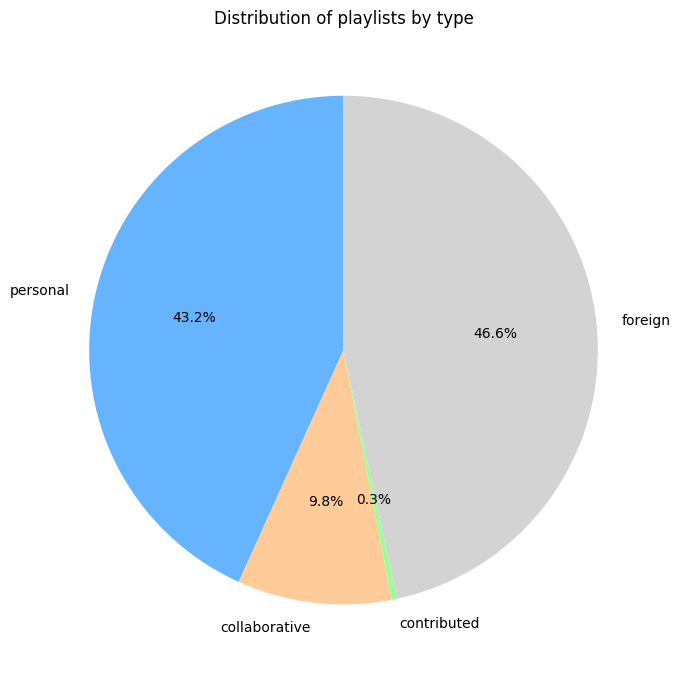


ℹ️ Analyzing valid plays (valid_play) by year.
   Categories: personal, collaborative, contributed, foreign, orphans.
   Priority for tracks in multiple types: personal > collaborative > contributed > foreign > orphan.

📊 Valid plays by year and playlist type (counts):


track_category,year,personal,collaborative,contributed,foreign,orphan
№,,,,,,
1,2020,229,6,0,89,302
2,2021,3421,69,0,622,2177
3,2022,3040,125,0,721,2390
4,2023,1820,1856,0,624,2822
5,2024,1916,645,0,528,2560
6,2025,3357,5315,0,1001,3474
7,2026,1225,2558,0,494,2455



📊 Share of categories within year (%):


track_category,year,personal,collaborative,contributed,foreign,orphan
№,,,,,,
1,2020,36.6,1.0,0.0,14.2,48.2
2,2021,54.4,1.1,0.0,9.9,34.6
3,2022,48.4,2.0,0.0,11.5,38.1
4,2023,25.6,26.1,0.0,8.8,39.6
5,2024,33.9,11.4,0.0,9.3,45.3
6,2025,25.5,40.4,0.0,7.6,26.4
7,2026,18.2,38.0,0.0,7.3,36.5


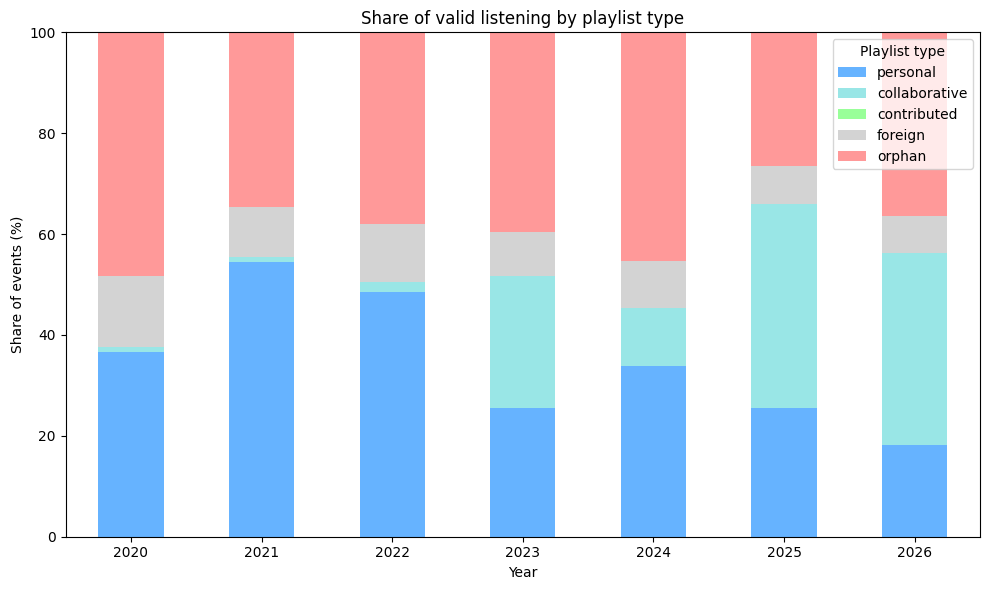

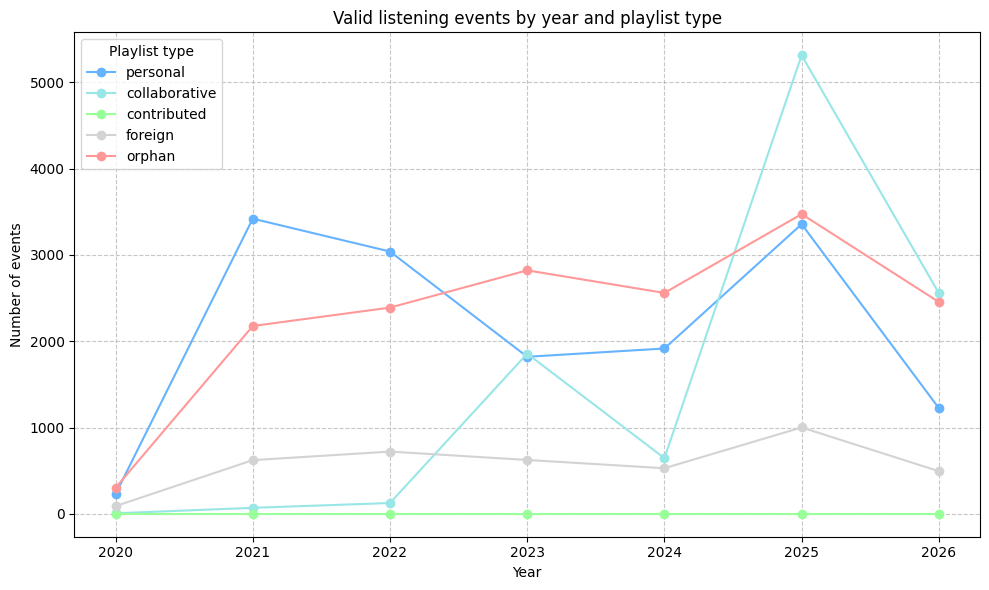

In [88]:
# 1. Типы плейлистов и временной срез прослушивания

# Две части одной логической цепочки:
#   1. Распределение плейлистов по структурным типам.
#   2. Как менялась доля прослушивания каждого типа по годам.

# ==========================================
# ЧАСТЬ 1: Распределение плейлистов по типам
# ==========================================
# Проверка согласованности классификации
multi_type = playlist_links.groupby('name_norm')['playlist_type'].nunique()
conflicts = multi_type[multi_type > 1].index.tolist()
print(f'🔎 Classification conflicts: {len(conflicts)}')
if conflicts:
    print('⚠️ Examples:', conflicts[:10])

# Уникальные плейлисты
unique_playlists = playlist_links.drop_duplicates('name_norm').copy()
type_counts = unique_playlists['playlist_type'].value_counts().reindex(type_order).fillna(0).astype(int)
type_shares = (type_counts / type_counts.sum() * 100).round(1)

summary = pd.DataFrame({
    'Type': type_counts.index,
    'Count': type_counts.values,
    'Share (%)': type_shares.values
})
summary.index = summary.index + 1
summary.index.name = '№'
print('📊 Playlist classification:')
display(summary)

# Круговая диаграмма
fig, ax = plt.subplots(figsize=(7, 7))
colors_pie = [colors_map[t] for t in type_counts.index]
wedges, texts, autotexts = ax.pie(
    type_counts.values,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors_pie,
    textprops={'fontsize': 10}
)
ax.set_title('Distribution of playlists by type')
plt.tight_layout()
plt.show()


# ==========================================
# ЧАСТЬ 2: Временной срез прослушивания по типам
# ==========================================
print('\nℹ️ Analyzing valid plays (valid_play) by year.')
print('   Categories: personal, collaborative, contributed, foreign, orphans.')
print('   Priority for tracks in multiple types: personal > collaborative > contributed > foreign > orphan.\n')

# Множества URI по типам
uri_sets = {
    'personal': set(playlist_links[playlist_links['playlist_type'] == 'personal']['Track URI']),
    'collaborative': set(playlist_links[playlist_links['playlist_type'] == 'collaborative']['Track URI']),
    'contributed': set(playlist_links[playlist_links['playlist_type'] == 'contributed']['Track URI']),
    'foreign': set(playlist_links[playlist_links['playlist_type'] == 'foreign']['Track URI']),
}


def track_category(uri):
    for ptype in ['personal', 'collaborative', 'contributed', 'foreign']:
        if uri in uri_sets[ptype]:
            return ptype
    return 'orphan'


# Валидные события с годом
valid = df_events[df_events['valid_play']].copy()
valid['year'] = pd.to_datetime(valid['ts'], errors='coerce').dt.year
valid['track_category'] = valid['spotify_track_uri'].apply(track_category)

# Таблица: год × категория
category_order = ['personal', 'collaborative', 'contributed', 'foreign', 'orphan']
cross_year = pd.crosstab(valid['year'], valid['track_category'])
cross_year = cross_year.reindex(columns=category_order, fill_value=0).sort_index()

# Доли внутри года
cross_year_pct = cross_year.div(cross_year.sum(axis=1), axis=0) * 100

# Вывод
print('📊 Valid plays by year and playlist type (counts):')
cross_year_display = cross_year.reset_index()
cross_year_display.index = range(1, len(cross_year_display) + 1)
cross_year_display.index.name = '№'
display(cross_year_display)

print('\n📊 Share of categories within year (%):')
cross_year_pct_display = cross_year_pct.round(1).reset_index()
cross_year_pct_display.index = range(1, len(cross_year_pct_display) + 1)
cross_year_pct_display.index.name = '№'
display(cross_year_pct_display)

# Палитра для категорий (личные, совместные, contributed, чужие, сироты)
category_colors = {
    'personal': COLORS['playlist'],
    'collaborative': COLORS['secondary'],
    'contributed': COLORS['success'],
    'foreign': COLORS['muted'],
    'orphan': COLORS['accent'],
}

# Stacked bar долей
ax = cross_year_pct[category_order].plot(
    kind='bar', stacked=True, figsize=(10, 6),
    color=[category_colors[c] for c in category_order]
)
ax.set_title('Share of valid listening by playlist type')
ax.set_xlabel('Year')
ax.set_ylabel('Share of events (%)')
ax.legend(title='Playlist type')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

# Линейный график абсолютных значений
cross_year[category_order].plot(
    kind='line', marker='o', figsize=(10, 6),
    color=[category_colors[c] for c in category_order]
)
plt.title('Valid listening events by year and playlist type')
plt.xlabel('Year')
plt.ylabel('Number of events')
plt.legend(title='Playlist type')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 1.1. Вывод

**Что смотрели.** Структуру коллекции по типам и распределение **valid_play** по годам. Приоритет при пересечении: **personal** > **collaborative** > **contributed** > **foreign** > **orphan**.

**Результат.** Коллекция делится почти поровну: **personal** 128 плейлистов (43.2%), **foreign** 138 (46.6%). **Collaborative** — 29 (9.8%), **contributed** — 1 (0.3%). За все годы **contributed** не даёт ни одного события.

По годам доли смещаются. В 2021 **personal** даёт 54.4% событий, **collaborative** — 1.1%. В 2023 доли сближаются: 25.6% против 26.1%. В 2025 **collaborative** — 40.4%, **personal** — 25.5%. В 2026 соотношение 38.0% против 18.2%.

**Orphan** — не тип плейлиста, а остаток: треки, которые слушаются, но не привязаны ни к одному плейлисту. Доля **orphan** в каждом году от 26.4% (2025) до 48.2% (2020).

**Вывод.** До 2022 основную нагрузку несёт **personal**. С 2023 доля **collaborative** растёт и в 2025–2026 превышает долю **personal**. **Foreign** стабильно занимает 7–14% и картину не определяет. **Contributed** присутствует формально и в прослушивании не участвует.

**Ограничения.**

2026 — неполный год в данных. Доли по нему нельзя сравнивать с полными годами напрямую.

2020 — малый по объёму: 626 событий против 6289 в 2021. Доли на таком объёме нестабильны. По этой же причине 2021 — год, в котором **personal** впервые даёт больше половины событий, — не стоит считать точкой отсчёта тренда.

**Orphan** растёт и падает независимо от типов плейлистов. Интерпретировать его динамику в этом блоке нельзя: неизвестно, какие треки в него попадают.

# Блок 2. Музыкальное содержание по типам плейлистов

## Блок 2. Музыкальное содержание по типам плейлистов

Блок сравнивает типы плейлистов по размеру, доле explicit, доле **unknown**, жанровому профилю и аудио-характеристикам.

Срез — **playlist_links**, **tracks_exportify**. Единица анализа — уникальный трек в плейлисте.

**explicit** — флаг Spotify, отмечающий треки с ненормативной лексикой или возрастным ограничением. Считается как доля треков с флагом от всех треков типа.

**unknown** (жанры) — значение `genres_normalized`, означающее отсутствие жанрового тега у трека. Не «неизвестный жанр», а отсутствие данных. Доля **unknown** показывает, какая часть треков выпадает из жанрового анализа.

**Жанровый профиль** считается по тегам, а не по трекам. Трек с тремя жанрами даёт три тега. Доли жанров — это доли тегов, они не суммируются в число треков.

**Аудио-признаки** — поля Spotify из `tracks_exportify`:

- **valence** — музыкальная позитивность, 0–1. Низкие значения — грустное, высокие — весёлое.
- **energy** — интенсивность и активность, 0–1.
- **danceability** — пригодность для танца, 0–1.
- **acousticness** — доля акустических инструментов, 0–1.
- **instrumentalness** — вероятность отсутствия вокала, 0–1. Выше 0.5 — скорее инструментал.
- **popularity** — популярность трека в Spotify, 0–100. Ноль означает отсутствие данных, а не «непопулярный трек».
- **tempo** — темп в BPM.

1. Общая сводка: размеры, explicit, **unknown**.
2. Жанровый профиль.
3. Аудио-характеристики.

📊 Playlist types summary:


,Playlists,Mean size,Median size,"Explicit, %","Unknown genres, %"
Type,,,,,
personal,128,77.3,50.0,2.7,29.1
collaborative,29,118.0,87.0,4.0,36.2
contributed,1,89.0,89.0,4.5,55.1
foreign,138,140.0,78.5,4.4,38.2


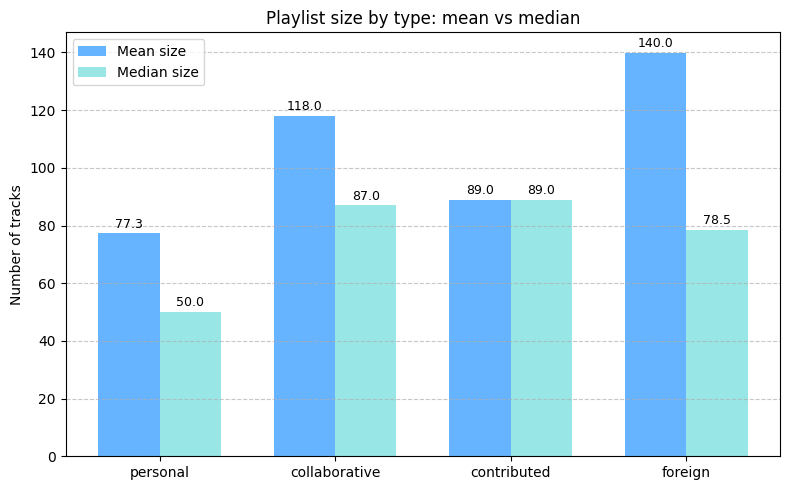

Table for the plot:


,Mean size,Median size
Type,,
personal,77.3,50.0
collaborative,118.0,87.0
contributed,89.0,89.0
foreign,140.0,78.5


Unique valid genres by type:


,Unique genres
personal,511
collaborative,294
contributed,48
foreign,601
All types,661


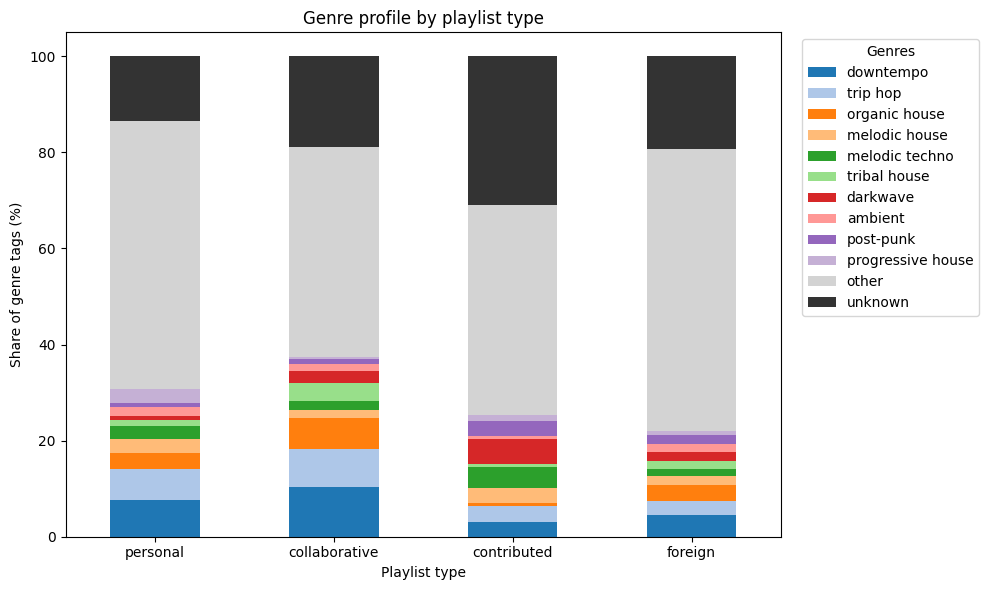

Genre shares by type (% of all genre tags):


,downtempo,trip hop,organic house,melodic house,melodic techno,tribal house,darkwave,ambient,post-punk,progressive house,other,unknown
type,,,,,,,,,,,,
personal,7.6,6.4,3.4,2.8,2.7,1.3,1.0,1.9,0.8,2.9,55.7,13.5
collaborative,10.3,7.9,6.4,1.8,1.8,3.7,2.4,1.5,1.1,0.4,43.7,18.9
contributed,3.2,3.2,0.6,3.2,4.4,0.6,5.1,0.6,3.2,1.3,43.7,31.0
foreign,4.5,3.0,3.3,1.8,1.5,1.7,1.9,1.6,1.8,0.7,58.8,19.2


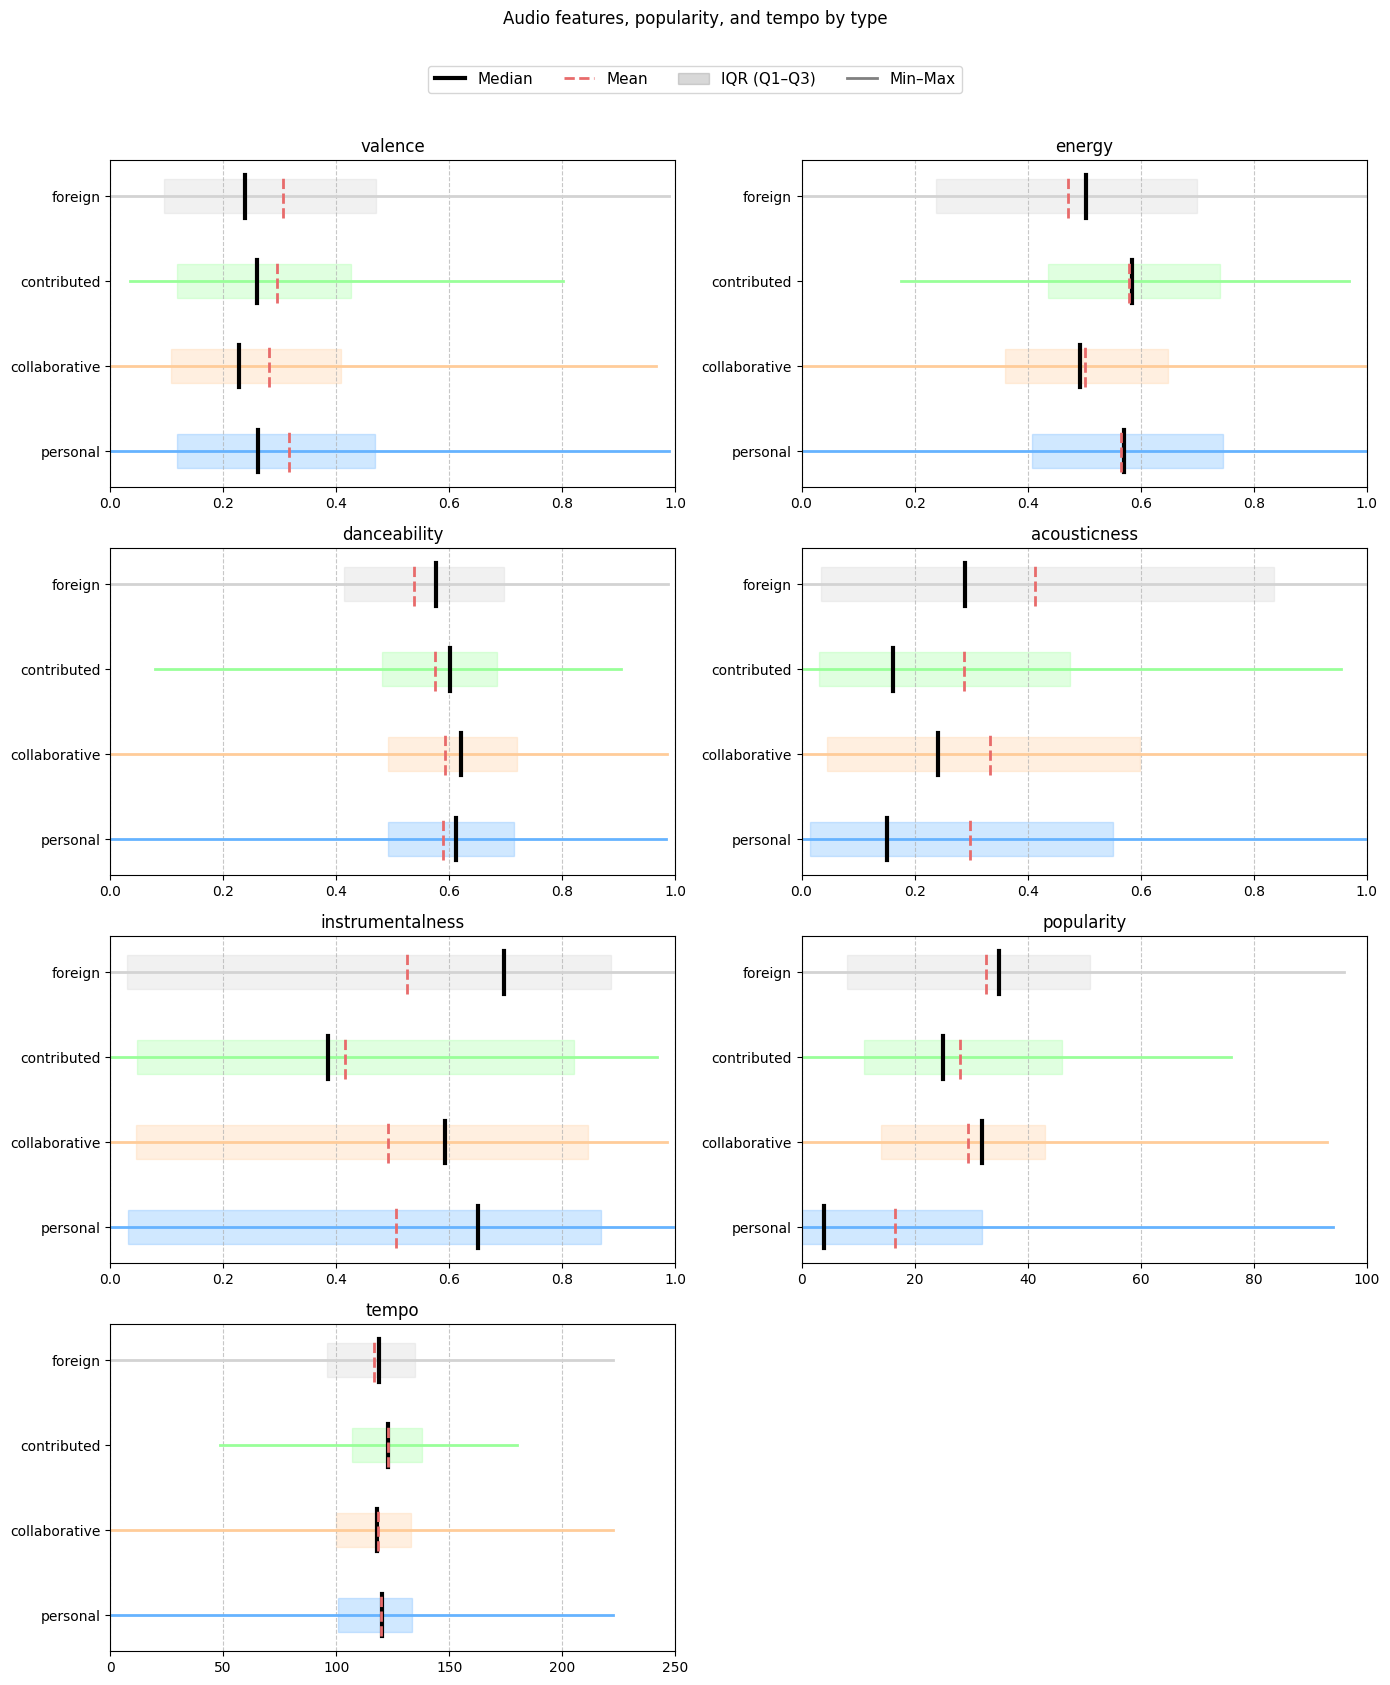

📊 valence:


,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.000,0.118,0.261,0.316,0.469,0.989
collaborative,0.000,0.107,0.228,0.280,0.408,0.965
contributed,0.036,0.119,0.259,0.294,0.426,0.801
foreign,0.000,0.095,0.239,0.305,0.470,0.989


📊 energy:


,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.000,0.407,0.571,0.565,0.745,1.000
collaborative,0.003,0.360,0.493,0.502,0.648,0.997
contributed,0.176,0.436,0.584,0.580,0.741,0.969
foreign,0.000,0.238,0.504,0.471,0.700,0.999


📊 danceability:


...

,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.0,0.032,0.650,0.505,0.868,0.995
collaborative,0.0,0.046,0.592,0.491,0.845,0.986
contributed,0.0,0.048,0.386,0.416,0.820,0.968
foreign,0.0,0.029,0.697,0.525,0.886,0.996


📊 popularity:


,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.0,0.0,4.0,16.528,32.0,94.0
collaborative,0.0,14.0,32.0,29.519,43.0,93.0
contributed,0.0,11.0,25.0,27.978,46.0,76.0
foreign,0.0,8.0,35.0,32.623,51.0,96.0


📊 tempo:


,Min,Q1,Median,Mean,Q3,Max
Type,,,,,,
personal,0.000,101.003,120.035,119.900,133.547,222.605
collaborative,0.000,99.900,117.972,118.395,133.142,222.605
contributed,48.637,107.019,123.018,123.005,138.039,180.138
foreign,0.000,96.001,118.945,116.745,134.976,222.605


In [114]:
# 2. Музыкальное содержание по типам плейлистов

# Три части:
#   1. Общая сводка: размеры, explicit, unknown.
#   2. Жанровый профиль.
#   3. Аудио-характеристики.

# ==========================================
# ЧАСТЬ 1: Общая сводка по типам
# ==========================================
# Сохраняем уникальные треки каждого типа в словаре для следующих ячеек.
type_tracks = {}
summary_rows = []
size_data = {}

features_audio = ['valence', 'energy', 'danceability', 'acousticness',
                  'instrumentalness', 'popularity', 'tempo', 'explicit',
                  'genres_normalized']

for ptype in type_order:
    links = playlist_links[playlist_links['playlist_type'] == ptype]
    pairs = links[['name_norm', 'Track URI']].drop_duplicates()
    merged = pairs.merge(
        tracks_exportify[['spotify_track_uri'] + features_audio],
        left_on='Track URI', right_on='spotify_track_uri', how='left'
    )
    type_tracks[ptype] = merged

    sizes = pairs.groupby('name_norm')['Track URI'].count()
    size_data[ptype] = sizes

    explicit_share = merged['explicit'].mean() * 100
    unknown_mask = merged['genres_normalized'].eq('unknown')
    unknown_share = unknown_mask.mean() * 100

    summary_rows.append({
        'Type': ptype,
        'Playlists': int(pairs['name_norm'].nunique()),
        'Mean size': round(sizes.mean(), 1),
        'Median size': round(sizes.median(), 1),
        'Explicit, %': round(explicit_share, 1),
        'Unknown genres, %': round(unknown_share, 1)
    })

summary_df = pd.DataFrame(summary_rows).set_index('Type')
print('📊 Playlist types summary:')
display(summary_df)

# Bar plot: средний и медианный размер по типам
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(type_order))
width = 0.35
mean_sizes = [size_data[t].mean() for t in type_order]
median_sizes = [size_data[t].median() for t in type_order]

bars1 = ax.bar(x - width/2, mean_sizes, width, label='Mean size', color=COLORS['primary'])
bars2 = ax.bar(x + width/2, median_sizes, width, label='Median size', color=COLORS['secondary'])

ax.set_xticks(x)
ax.set_xticklabels(type_order)
ax.set_ylabel('Number of tracks')
ax.set_title('Playlist size by type: mean vs median')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

for bar, val in zip(bars1, mean_sizes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{val:.1f}', ha='center', fontsize=9)
for bar, val in zip(bars2, median_sizes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f'{val:.1f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

size_summary = pd.DataFrame({
    'Type': type_order,
    'Mean size': mean_sizes,
    'Median size': median_sizes
}).set_index('Type')
print('Table for the plot:')
display(size_summary.round(1))


# ==========================================
# ЧАСТЬ 2: Жанровый профиль
# ==========================================
# Топ-10 жанров по всем типам, единая палитра для жанров.
playlist_type_order = ['personal', 'collaborative', 'contributed', 'foreign']

all_genres = []
for ptype in playlist_type_order:
    valid = get_valid_genre_series(type_tracks[ptype]['genres_normalized'])
    all_genres.extend(valid.str.split(',').explode().str.strip().tolist())
all_genres_series = pd.Series(all_genres)
all_genres_series = all_genres_series[all_genres_series != '']
top10_genres = all_genres_series.value_counts().head(10).index.tolist()

# Уникальные жанры по типам
total_unique_genres = all_genres_series.nunique()
unique_genres_by_type = {}
for ptype in playlist_type_order:
    valid = get_valid_genre_series(type_tracks[ptype]['genres_normalized'])
    genres_split = valid.str.split(',').explode().str.strip()
    genres_split = genres_split[genres_split != '']
    unique_genres_by_type[ptype] = genres_split.nunique()

unique_genres_by_type_series = pd.Series(unique_genres_by_type)
unique_genres_by_type_series['All types'] = total_unique_genres
print('Unique valid genres by type:')
display(unique_genres_by_type_series.to_frame('Unique genres'))

# Доли топ-10 + other + unknown
share_rows = []
for ptype in playlist_type_order:
    series = type_tracks[ptype]['genres_normalized']
    total_tags = 0
    unknown_count = 0
    other_count = 0
    top_counts = {g: 0 for g in top10_genres}

    for genres in series.dropna():
        tags = [t.strip() for t in genres.split(',')]
        for tag in tags:
            if tag == '' or tag == 'unknown':
                unknown_count += 1
                total_tags += 1
            elif tag in top_counts:
                top_counts[tag] += 1
                total_tags += 1
            else:
                other_count += 1
                total_tags += 1

    if total_tags == 0:
        shares = [0] * len(top10_genres) + [0, 0]
    else:
        shares = [top_counts[g] / total_tags * 100 for g in top10_genres]
        shares += [other_count / total_tags * 100, unknown_count / total_tags * 100]
    share_rows.append([ptype] + shares)

share_df = pd.DataFrame(share_rows, columns=['type'] + top10_genres + ['other', 'unknown'])
share_df = share_df.set_index('type')

# Цвета для жанров
tab20 = plt.cm.tab20.colors
genre_colors = {g: tab20[i % len(tab20)] for i, g in enumerate(top10_genres)}
genre_colors['other'] = COLORS['muted']
genre_colors['unknown'] = '#333333'

# Stacked bar
ax = share_df.plot(kind='bar', stacked=True, figsize=(10, 6),
                   color=[genre_colors[g] for g in share_df.columns])
ax.set_title('Genre profile by playlist type')
ax.set_xlabel('Playlist type')
ax.set_ylabel('Share of genre tags (%)')
ax.legend(title='Genres', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

print('Genre shares by type (% of all genre tags):')
display(share_df.round(1))


# ==========================================
# ЧАСТЬ 3: Аудио-характеристики
# ==========================================
features_plot = ['valence', 'energy', 'danceability', 'acousticness',
                 'instrumentalness', 'popularity', 'tempo']
xlims = {
    'valence': (0, 1), 'energy': (0, 1), 'danceability': (0, 1),
    'acousticness': (0, 1), 'instrumentalness': (0, 1),
    'popularity': (0, 100), 'tempo': (0, 250)
}

# Range plot 4×2
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for idx, feat in enumerate(features_plot):
    ax = axes[idx]
    xmin, xmax = xlims[feat]
    for j, ptype in enumerate(type_order):
        data = type_tracks[ptype][feat].dropna()
        if len(data) == 0:
            continue
        median = data.median()
        q1 = data.quantile(0.25)
        q3 = data.quantile(0.75)
        min_val = data.min()
        max_val = data.max()
        y_pos = j

        ax.plot([min_val, max_val], [y_pos, y_pos], color=colors_map[ptype], lw=2)
        ax.add_patch(plt.Rectangle((q1, y_pos - 0.2), q3 - q1, 0.4,
                                   color=colors_map[ptype], alpha=0.3))
        ax.plot([median, median], [y_pos - 0.25, y_pos + 0.25], color='black', lw=3)
        ax.plot([data.mean(), data.mean()], [y_pos - 0.25, y_pos + 0.25],
                color=COLORS['line_accent'], lw=2, linestyle='--')

    ax.set_title(feat)
    ax.set_yticks(range(4))
    ax.set_yticklabels(type_order)
    ax.set_xlim(xmin, xmax)
    ax.grid(axis='x', linestyle='--', alpha=0.7)

axes[-1].axis('off')

# Легенда
median_handle = mlines.Line2D([], [], color='black', lw=3, label='Median')
mean_handle = mlines.Line2D([], [], color=COLORS['line_accent'], lw=2,
                            linestyle='--', label='Mean')
iqr_handle = mpatches.Patch(color='gray', alpha=0.3, label='IQR (Q1–Q3)')
minmax_handle = mlines.Line2D([], [], color='gray', lw=2, label='Min–Max')
fig.legend(handles=[median_handle, mean_handle, iqr_handle, minmax_handle],
           loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=4, fontsize=11)
plt.suptitle('Audio features, popularity, and tempo by type', y=1.05)
plt.tight_layout()
plt.show()

# Таблицы по каждой характеристике
for feat in features_plot:
    table_rows = []
    for ptype in type_order:
        data = type_tracks[ptype][feat].dropna()
        table_rows.append({
            'Type': ptype,
            'Min': data.min(),
            'Q1': data.quantile(0.25),
            'Median': data.median(),
            'Mean': data.mean(),
            'Q3': data.quantile(0.75),
            'Max': data.max()
        })
    feat_table = pd.DataFrame(table_rows).set_index('Type')
    if feat in ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']:
        fmt = '{:.3f}'
    else:
        fmt = '{:.1f}'
    print(f'📊 {feat}:')
    display(feat_table.round(3))

## 2. Вывод

**Что смотрели.** Размеры плейлистов, долю explicit, долю **unknown**, жанровый профиль, медианы аудио-характеристик по типам.

**Результат.** **Personal** — самый компактный тип: медиана 50.0 треков, среднее 77.3. **Foreign** крупнее: медиана 78.5, среднее 140.0. **Collaborative** — 87.0 и 118.0. **Contributed** — один плейлист на 89 треков, статистики нет.

Доля explicit: **personal** 2.7%, остальные 4.0–4.5%. Доля **unknown** в жанрах: **personal** 29.1%, **collaborative** 36.2%, **foreign** 38.2%. Уникальных жанров: **personal** 511, **foreign** 601, **collaborative** 294, объединение — 661.

По аудио типы почти не различаются в valence (0.23–0.26), danceability (0.58–0.62), tempo (118–120 BPM), instrumentalness (0.59–0.70). Различия — в трёх признаках. **Popularity**: **personal** медиана 4.0 против 32.0 у **collaborative** и 35.0 у **foreign**. **Acousticness**: 0.151 против 0.241 и 0.289. **Energy**: 0.571 против 0.493 и 0.504.

**Вывод.** **Personal** — нишевый тип: компактный, менее explicit, точнее по жанрам, с низкой popularity, низкой acousticness, повышенной energy. **Foreign** — противоположный: крупный, популярный, акустичный, менее энергичный. **Collaborative** ближе к **foreign**, чем к **personal**. Инструментальность высока у всех типов — это общая черта коллекции, а не различие.

**Ограничения.** **Contributed** — одна единица, выводы по нему невозможны. **Unknown** в жанрах 29–38% у основных типов — жанровые выводы ограничены. По **popularity** медиана 4.0 у **personal** означает, что больше половины треков имеют popularity 0 — возможен артефакт метаданных. Треки, попадающие в несколько типов, учитываются с приоритетом **personal** > **collaborative** > **foreign**, поэтому пересечения размывают границы.

# Блок 3. Сравнение типов: пересечения и контрасты

## Блок 3. Сравнение типов: пересечения и контрасты

Блок считает пересечения уникальных треков между типами, сравнивает **personal** и **foreign** по аудио-профилю и значимости, строит автоматические портреты типов по медианам и проверяет различия через **Kruskal-Wallis** и **Mann-Whitney U**.

Срез — **playlist_links**, **tracks_exportify**. Единица анализа — уникальный трек.

**Пересечение** — треки, которые входят в плейлисты обоих типов одновременно. Считается как пересечение множеств `Track URI`. Матрица пересечений симметрична: пересечение **personal** и **foreign** равно пересечению **foreign** и **personal**. Доля от строки — какая часть треков данного типа встречается в другом типе.

**Kruskal-Wallis** — непараметрический тест на различие между тремя и более группами. Не предполагает нормального распределения. Нулевая гипотеза — все группы из одного распределения. p < 0.05 означает, что хотя бы одна группа отличается.

**Mann-Whitney U** — непараметрический тест на различие между двумя группами. Используется попарно после **Kruskal-Wallis** для поиска конкретных различий.

**Статистическая значимость** — p < 0.05. Означает, что различие вряд ли случайно.

**Практическая значимость** — порог, ниже которого различие считается слишком малым, чтобы иметь значение, даже если оно статистически значимо. Пороги: 0.02 для признаков 0–1, 5.0 для **popularity**, 2.0 для **tempo**. Пороги эвристические, не выведены из данных.

**Правило вердикта.** `✅` — значимо статистически и практически. `⚠️` — значимо статистически, но ниже порога практической значимости. `—` — не значимо.

1. Пересечения треков между типами.
2. **Personal** vs **foreign**.
3. Топы и статистика по всем типам.


📊 Intersection matrix, unique tracks (absolute):


Type,personal,collaborative,contributed,foreign
Type,,,,
personal,7962.0,636.0,89.0,1582.0
collaborative,636.0,2389.0,5.0,1315.0
contributed,89.0,5.0,89.0,21.0
foreign,1582.0,1315.0,21.0,17694.0



📊 Share of row type (%):


Type,personal,collaborative,contributed,foreign
Type,,,,
personal,100.0,8.0,1.1,19.9
collaborative,26.6,100.0,0.2,55.0
contributed,100.0,5.6,100.0,23.6
foreign,8.9,7.4,0.1,100.0


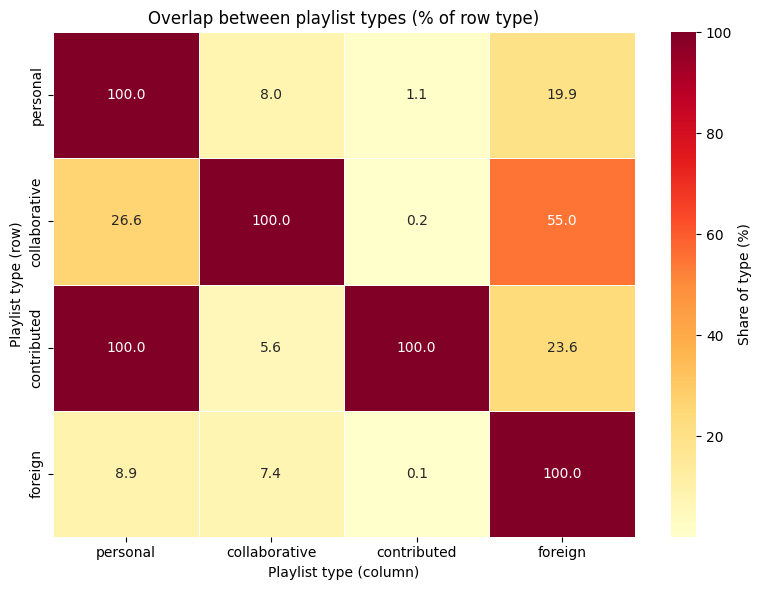

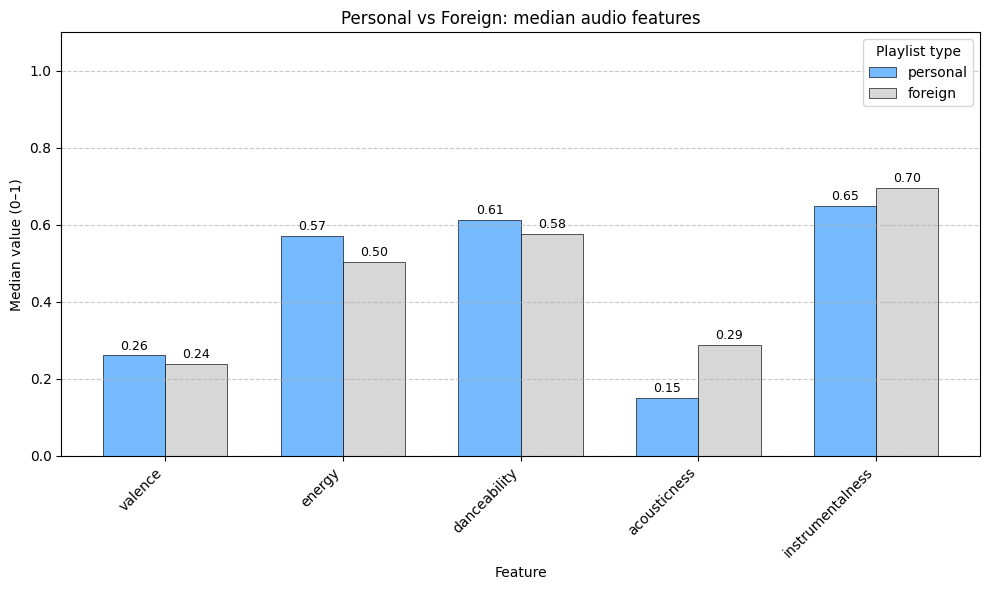

📊 personal vs foreign (0–1 features):


,Feature,personal median,foreign median,Mean diff,Threshold,p-value,Verdict,Note
№,,,,,,,,
1,valence,0.261,0.239,0.010,0.02,3.018e-09,⚠️,"significant, but small"
2,energy,0.571,0.504,0.094,0.02,1.525e-135,✅,significant and meaningful
3,danceability,0.612,0.576,0.051,0.02,4.101e-69,✅,significant and meaningful
4,acousticness,0.151,0.289,-0.114,0.02,2.835e-135,✅,significant and meaningful
5,instrumentalness,0.650,0.697,-0.020,0.02,1.715e-11,⚠️,"significant, but small"


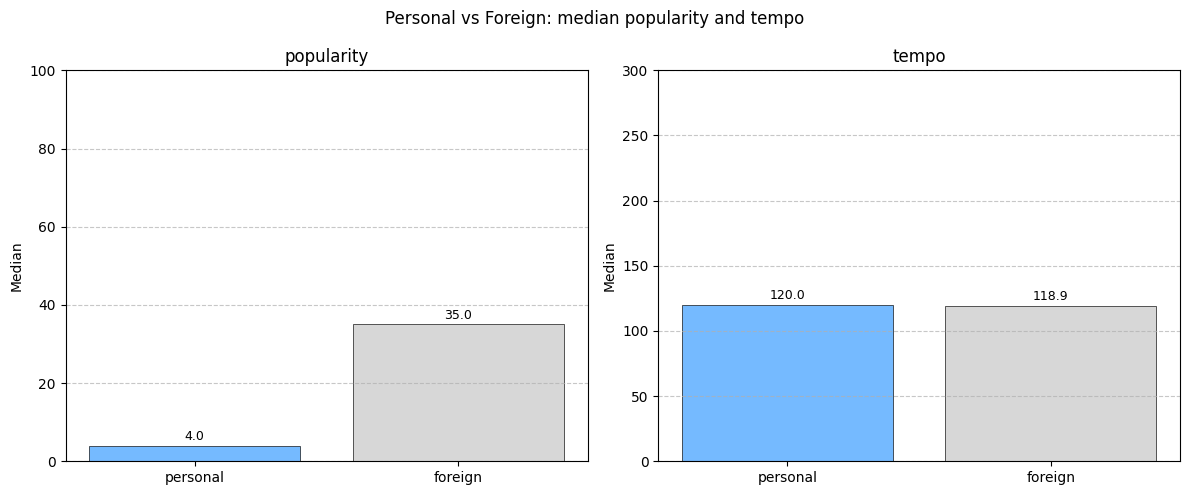

📊 personal vs foreign (popularity, tempo):


,Feature,personal median,foreign median,Mean diff,Threshold,p-value,Verdict,Note
№,,,,,,,,
1,popularity,4.0,35.0,-16.1,5.0,0.000e+00,✅,significant and meaningful
2,tempo,120.0,118.9,3.2,2.0,5.076e-19,✅,significant and meaningful



🔍 Auto conclusion:
• personal: energy higher (0.57 vs 0.50), danceability higher (0.61 vs 0.58), tempo higher (120.03 vs 118.94).
• foreign: acousticness higher (0.29 vs 0.15), popularity higher (35.00 vs 4.00).

📊 Auto portraits by medians:


,Feature,🥇 Leader,🥈 Outsider,Leader median,Outsider median
№,,,,,
1,valence,personal,collaborative,0.261,0.228
2,energy,contributed,collaborative,0.584,0.493
3,danceability,collaborative,foreign,0.621,0.576
4,acousticness,foreign,personal,0.289,0.151
5,instrumentalness,foreign,contributed,0.697,0.386
6,popularity,foreign,personal,35.000,4.000
7,tempo,contributed,collaborative,123.018,117.972



📊 Overall significance (Kruskal-Wallis):


,Feature,p-value,Result
№,,,
1,valence,2.839e-11,✅ significant
2,energy,1.373e-140,✅ significant
3,danceability,3.162e-85,✅ significant
4,acousticness,2.830e-137,✅ significant
5,instrumentalness,9.469e-18,✅ significant
6,popularity,0.000e+00,✅ significant
7,tempo,2.330e-18,✅ significant



📊 Pairwise significant differences (Mann-Whitney U):


,Feature,Pair,Diff,p-value,Signif,Conclusion
№,,,,,,
1,valence,personal vs collaborative,0.035,1.667e-10,***,personal higher than collaborative
2,valence,personal vs foreign,0.010,3.018e-09,⚠️,"significant, but small"
3,valence,collaborative vs foreign,-0.025,1.707e-02,*,foreign higher than collaborative
4,energy,personal vs collaborative,0.063,1.087e-48,***,personal higher than collaborative
5,energy,personal vs foreign,0.094,1.525e-135,***,personal higher than foreign
6,energy,collaborative vs contributed,-0.078,5.741e-04,***,contributed higher than collaborative
7,energy,collaborative vs foreign,0.032,8.891e-04,***,collaborative higher than foreign
8,energy,contributed vs foreign,0.110,7.076e-04,***,contributed higher than foreign
9,danceability,personal vs foreign,0.051,4.101e-69,***,personal higher than foreign



Legend: *** p<0.001, ** p<0.01, * p<0.05
⚠️ significant, but below practical threshold


In [90]:
# 3. Сравнение типов: пересечения и контрасты

# Три части:
#   1. Пересечения уникальных треков между типами.
#   2. Личные vs чужие: аудио-профиль и значимость.
#   3. Топы и статистика по всем типам.

# ==========================================
# ЧАСТЬ 1: Пересечения треков между типами
# ==========================================
uris_by_type = {
    ptype: set(type_tracks[ptype]['spotify_track_uri'].dropna())
    for ptype in type_order
}

# Матрица абсолютных пересечений
intersection_matrix = pd.DataFrame(index=type_order, columns=type_order, dtype=int)
for i, t1 in enumerate(type_order):
    for j, t2 in enumerate(type_order):
        if i == j:
            intersection_matrix.loc[t1, t2] = len(uris_by_type[t1])
        else:
            intersection_matrix.loc[t1, t2] = len(uris_by_type[t1] & uris_by_type[t2])

intersection_matrix.index.name = 'Type'
intersection_matrix.columns.name = 'Type'

print('📊 Intersection matrix, unique tracks (absolute):')
display(intersection_matrix)

# Доли от строки
share_matrix = intersection_matrix.copy().astype(float)
for t in type_order:
    share_matrix.loc[t, :] = share_matrix.loc[t, :] / len(uris_by_type[t]) * 100

print('\n📊 Share of row type (%):')
display(share_matrix.round(1))

# Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    share_matrix.astype(float),
    annot=True, fmt='.1f', cmap='YlOrRd',
    cbar_kws={'label': 'Share of type (%)'},
    linewidths=0.5
)
plt.title('Overlap between playlist types (% of row type)')
plt.xlabel('Playlist type (column)')
plt.ylabel('Playlist type (row)')
plt.tight_layout()
plt.show()


# ==========================================
# ЧАСТЬ 2: Personal vs Foreign
# ==========================================
t1 = 'personal'
t2 = 'foreign'


ALPHA = 0.05

# Часть 2.1: 0–1 характеристики — медианы
features_01 = ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']
med_t1 = [type_tracks[t1][feat].dropna().median() for feat in features_01]
med_t2 = [type_tracks[t2][feat].dropna().median() for feat in features_01]

x = np.arange(len(features_01))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, med_t1, width, label=t1,
               color=colors_map[t1], edgecolor='black', linewidth=0.5, alpha=0.9)
bars2 = ax.bar(x + width/2, med_t2, width, label=t2,
               color=colors_map[t2], edgecolor='black', linewidth=0.5, alpha=0.9)

ax.set_xlabel('Feature')
ax.set_ylabel('Median value (0–1)')
ax.set_title('Personal vs Foreign: median audio features')
ax.set_xticks(x)
ax.set_xticklabels(features_01, rotation=45, ha='right')
ax.legend(title='Playlist type')
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_ylim(0, 1.1)
ax.bar_label(bars1, fmt='%.2f', fontsize=9, padding=2)
ax.bar_label(bars2, fmt='%.2f', fontsize=9, padding=2)
plt.tight_layout()
plt.show()

# Таблица по 0–1
rows_01 = []
for feat in features_01:
    a = type_tracks[t1][feat].dropna()
    b = type_tracks[t2][feat].dropna()
    med1 = a.median()
    med2 = b.median()
    mean_diff = a.mean() - b.mean()
    thresh = PRACTICAL_THRESHOLDS[feat]
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    stat_sig = p < ALPHA
    pract_sig = abs(mean_diff) >= thresh
    if stat_sig and pract_sig:
        verdict, note = '✅', 'significant and meaningful'
    elif stat_sig and not pract_sig:
        verdict, note = '⚠️', 'significant, but small'
    else:
        verdict, note = '—', 'not significant'
    rows_01.append({
        'Feature': feat,
        f'{t1} median': f'{med1:.3f}',
        f'{t2} median': f'{med2:.3f}',
        'Mean diff': f'{mean_diff:.3f}',
        'Threshold': f'{thresh:.2f}',
        'p-value': f'{p:.3e}',
        'Verdict': verdict,
        'Note': note
    })
df_01 = pd.DataFrame(rows_01)
df_01.index = df_01.index + 1
df_01.index.name = '№'
print(f'📊 {t1} vs {t2} (0–1 features):')
display(df_01)

# Часть 2.2: popularity и tempo
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, feat, ylim, fmt in [
    (axes[0], 'popularity', 100, '%.1f'),
    (axes[1], 'tempo', 300, '%.1f')
]:
    med_t1 = type_tracks[t1][feat].dropna().median()
    med_t2 = type_tracks[t2][feat].dropna().median()
    bars = ax.bar([t1, t2], [med_t1, med_t2],
                  color=[colors_map[t1], colors_map[t2]],
                  edgecolor='black', linewidth=0.5, alpha=0.9)
    ax.set_title(feat)
    ax.set_ylabel('Median')
    ax.set_ylim(0, ylim)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.bar_label(bars, fmt=fmt, fontsize=9, padding=2)

plt.suptitle('Personal vs Foreign: median popularity and tempo')
plt.tight_layout()
plt.show()

# Таблица по popularity и tempo
rows_other = []
for feat in ['popularity', 'tempo']:
    a = type_tracks[t1][feat].dropna()
    b = type_tracks[t2][feat].dropna()
    mean_diff = a.mean() - b.mean()
    thresh = PRACTICAL_THRESHOLDS[feat]
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    stat_sig = p < ALPHA
    pract_sig = abs(mean_diff) >= thresh
    if stat_sig and pract_sig:
        verdict, note = '✅', 'significant and meaningful'
    elif stat_sig and not pract_sig:
        verdict, note = '⚠️', 'significant, but small'
    else:
        verdict, note = '—', 'not significant'
    rows_other.append({
        'Feature': feat,
        f'{t1} median': f'{a.median():.1f}',
        f'{t2} median': f'{b.median():.1f}',
        'Mean diff': f'{mean_diff:.1f}',
        'Threshold': f'{thresh:.1f}',
        'p-value': f'{p:.3e}',
        'Verdict': verdict,
        'Note': note
    })
df_other = pd.DataFrame(rows_other)
df_other.index = df_other.index + 1
df_other.index.name = '№'
print(f'📊 {t1} vs {t2} (popularity, tempo):')
display(df_other)

# Автоматический портрет
personal_traits = []
foreign_traits = []

for feat in features_01 + ['popularity', 'tempo']:
    a = type_tracks[t1][feat].dropna()
    b = type_tracks[t2][feat].dropna()
    mean_diff = a.mean() - b.mean()
    thresh = PRACTICAL_THRESHOLDS[feat]
    p = stats.mannwhitneyu(a, b, alternative='two-sided')[1]
    if p < ALPHA and abs(mean_diff) >= thresh:
        if mean_diff > 0:
            personal_traits.append(f'{feat} higher ({a.median():.2f} vs {b.median():.2f})')
        else:
            foreign_traits.append(f'{feat} higher ({b.median():.2f} vs {a.median():.2f})')

print('\n🔍 Auto conclusion:')
if personal_traits:
    print(f'• {t1}: ' + ', '.join(personal_traits) + '.')
if foreign_traits:
    print(f'• {t2}: ' + ', '.join(foreign_traits) + '.')
if not personal_traits and not foreign_traits:
    print('No meaningful differences detected.')


# ==========================================
# ЧАСТЬ 3: Топы и статистика по типам
# ==========================================
features_all = ['valence', 'energy', 'danceability', 'acousticness',
                'instrumentalness', 'popularity', 'tempo']
types_list = type_order

# Автоматические портреты типов
portrait_rows = []
for feat in features_all:
    medians = {ptype: type_tracks[ptype][feat].dropna().median() for ptype in types_list}
    leader = max(medians, key=medians.get)
    outsider = min(medians, key=medians.get)
    portrait_rows.append({
        'Feature': feat,
        '🥇 Leader': leader,
        '🥈 Outsider': outsider,
        'Leader median': medians[leader],
        'Outsider median': medians[outsider]
    })

portrait_df = pd.DataFrame(portrait_rows)
portrait_df.index = range(1, len(portrait_df) + 1)
portrait_df.index.name = '№'
print('\n📊 Auto portraits by medians:')
display(portrait_df)

# Kruskal-Wallis
kw_results = {}
for feat in features_all:
    groups = [type_tracks[ptype][feat].dropna() for ptype in types_list]
    valid_groups = [(ptype, g) for ptype, g in zip(types_list, groups) if len(g) >= MIN_TRACKS_PER_PLAYLIST]
    if len(valid_groups) < 2:
        kw_results[feat] = {'p': np.nan, 'valid_types': []}
        continue
    valid_types = [ptype for ptype, _ in valid_groups]
    valid_data = [g for _, g in valid_groups]
    h_stat, p_kw = stats.kruskal(*valid_data)
    kw_results[feat] = {'p': p_kw, 'valid_types': valid_types}

kw_rows = []
for feat in features_all:
    p = kw_results[feat]['p']
    if np.isnan(p):
        verdict = '⚠️ insufficient data'
    elif p < ALPHA:
        verdict = '✅ significant'
    else:
        verdict = '— not significant'
    kw_rows.append({
        'Feature': feat,
        'p-value': f'{p:.3e}' if not np.isnan(p) else '—',
        'Result': verdict
    })
kw_df = pd.DataFrame(kw_rows)
kw_df.index = range(1, len(kw_df) + 1)
kw_df.index.name = '№'
print('\n📊 Overall significance (Kruskal-Wallis):')
display(kw_df)

# Попарные значимые различия
from itertools import combinations

pair_rows = []
for feat in features_all:
    if kw_results[feat]['p'] >= ALPHA or not kw_results[feat]['valid_types']:
        continue
    valid_types = kw_results[feat]['valid_types']
    for t1_, t2_ in combinations(valid_types, 2):
        a = type_tracks[t1_][feat].dropna()
        b = type_tracks[t2_][feat].dropna()
        if len(a) < 30 or len(b) < 30:
            continue
        u, p_pair = stats.mannwhitneyu(a, b, alternative='two-sided')
        mean_diff = a.mean() - b.mean()
        thresh = PRACTICAL_THRESHOLDS[feat]
        if p_pair < ALPHA and abs(mean_diff) >= thresh:
            stars = '***' if p_pair < 0.001 else '**' if p_pair < 0.01 else '*'
            higher, lower = (t1_, t2_) if mean_diff > 0 else (t2_, t1_)
            pair_rows.append({
                'Feature': feat,
                'Pair': f'{t1_} vs {t2_}',
                'Diff': f'{mean_diff:.3f}',
                'p-value': f'{p_pair:.3e}',
                'Signif': f'{stars}',
                'Conclusion': f'{higher} higher than {lower}'
            })
        elif p_pair < ALPHA and abs(mean_diff) < thresh:
            pair_rows.append({
                'Feature': feat,
                'Pair': f'{t1_} vs {t2_}',
                'Diff': f'{mean_diff:.3f}',
                'p-value': f'{p_pair:.3e}',
                'Signif': '⚠️',
                'Conclusion': 'significant, but small'
            })

if pair_rows:
    pair_df = pd.DataFrame(pair_rows)
    pair_df.index = range(1, len(pair_df) + 1)
    pair_df.index.name = '№'
    print('\n📊 Pairwise significant differences (Mann-Whitney U):')
    display(pair_df)
    print('\nLegend: *** p<0.001, ** p<0.01, * p<0.05')
    print('⚠️ significant, but below practical threshold')
else:
    print('\n📊 No significant pairwise differences detected.')

### 3. Вывод

**Что смотрели.** Пересечения уникальных треков между типами. Разницу **personal** и **foreign** по аудио и popularity. Различия между всеми четырьмя типами через **Kruskal-Wallis** и **Mann-Whitney U**.

**Пересечения.** **Foreign** — крупнейший тип, **personal** вдвое меньше, **contributed** — 89 треков. **Collaborative** на 55% состоит из треков **foreign**. Обратно **foreign** берёт из **collaborative** только 7.4%. **Contributed** на 100% совпадает с **personal**: все его треки уже есть в личных плейлистах. Собственного содержания у **contributed** нет.

**Personal против foreign.** Различия значимы по всем семи признакам, практически существенны — по пяти. **Foreign** популярнее: медиана 35.0 против 4.0 у **personal**. **Foreign** акустичнее: 0.29 против 0.15. **Personal** энергичнее: 0.57 против 0.50. По valence и instrumentalness различия статистически значимы, но ниже порога практической существенности.

**Все четыре типа.** **Kruskal-Wallis** значим по всем признакам. В попарных сравнениях **collaborative** ближе к **foreign** по popularity и ближе к **personal** по acousticness и danceability. **Contributed** не даёт ни одного попарного различия, которое нельзя было бы объяснить его единственным плейлистом.

**Вывод.** **Personal** и **foreign** — два полюса коллекции: нишевое против популярного, энергичное против акустичного. **Collaborative** — между ними, без собственного полюса. **Contributed** — не отдельный тип, а подмножество **personal**.

**Ограничения.** **Contributed** — одна единица. Все выводы по нему описывают один плейлист, а не тип. Его 100% совпадение с **personal** — следствие того, что треки добавлены в личные плейлисты, а не признак сходства типов.

27 попарных сравнений без поправки на множественные сравнения. Часть значимых различий может быть ложноположительной.

Пороги практической существенности (0.02 для 0–1 признаков, 5.0 для popularity, 2.0 для tempo) — эвристика, не выведенная из данных.

# Блок 4. Collaborator Explorer

## Блок 4. Collaborator Explorer

Блок разбирает, кто наполняет **collaborative** и **contributed** плейлисты. Делит добавления на  our, external и unknown.. Строит роли участников. Даёт детальный разбор выбранного плейлиста.

Срез — **playlist_links**, **playlists_metadata**, **tracks_exportify**, **owner_ids**. Единица анализа — добавление.

**owner_ids_set** — множество владельцев плейлистов из `owner_ids`. По нему определяется, наш аккаунт добавил трек или внешний: если `Added By` входит в `owner_ids_set`, добавление считается нашим.

**actor_group** — группа участника добавления. **our** — `Added By` входит в `owner_ids_set`. **external** — не входит. **unknown** — `Added By` пуст или равен `unknown`.

**Роли** — позиция аккаунта в конкретном плейлисте. Определяются по `owner_map`, где для каждого **name_norm** указан владелец.

- **owner** — аккаунт владеет этим плейлистом и добавляет в него.
- **collaborator** — наш другой аккаунт в нашем плейлисте.
- **contributor** — наш аккаунт в чужом плейлисте.
- **external** — участник, которого нет в `owner_ids_set`.
- **unknown** — автор добавления не определён.

**Unknown** — добавления, у которых `Added By` пуст или помечен как `unknown`. Это артефакт Exportify: трек есть в экспорте, но в API Spotify автор добавления не сохранился.

**Конфаунд блока.** Роли определяются по `owner_map` из **playlists_metadata**. Если владелец плейлиста не попал в метаданные, роль может быть присвоена неверно.

1. Обзорная ячейка: количество плейлистов, соотношение добавлений, таблица участников, легенда ролей.
2. Детальный разбор плейлиста: участники, жанры, аудио, попарные сравнения.

## 4.1 Collaborator Explorer: обзорная ячейка


📊 Playlist count by type:


,Type,Playlists
№,,
1,collaborative,29
2,contributed,1



📊 Additions: our vs external vs unknown:


,Our additions,External additions,Unknown
playlist_type,,,
collaborative,3355,20,68
contributed,89,0,0
Total,3444,20,68


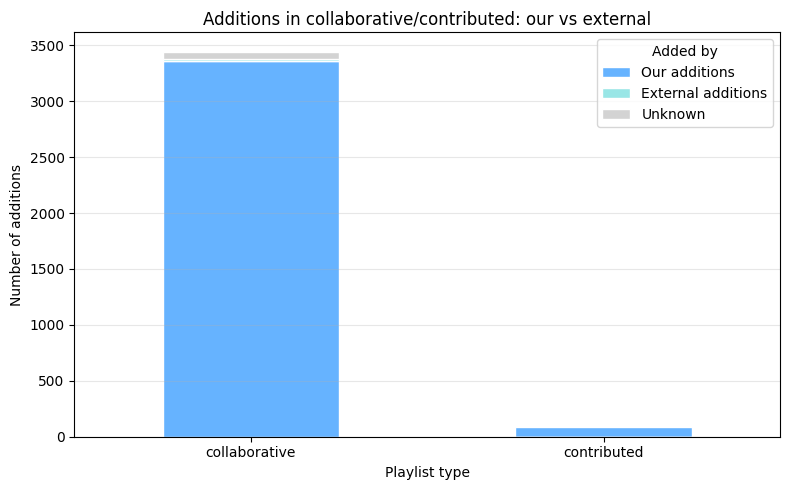


📊 Participants of collaborative and contributed playlists:


,Participant,Roles,Total additions,Share (%),Playlists
№,,,,,
1,Account 1,"owner, collaborator, contributor",3227,91.4,"2024_part_2, 2025, 2026, 202603, ambienr_post-..."
2,Account 3,"collaborator, owner",173,4.9,"2025, 2026, 202603, personal_emotional_05, per..."
3,Unknown,unknown,68,1.9,2025
4,Account 2,"collaborator, contributor, owner",44,1.2,"2024_part_2, personal_identity_01, 🌑🌒🌕🌔moon"
5,user_23,external,20,0.6,personal_identity_01



📌 Roles:
• owner        — playlist owner;
• collaborator — our other account in our own playlist;
• contributor  — our account in someone else's playlist;
• external     — external participant;
• unknown      — undefined (Exportify artifact, absent in API).


In [91]:
# 4.1 Collaborator Explorer: обзорная ячейка

# Совместные (collaborative) и соавторские (contributed) плейлисты.
# Кто их наполняет: наши аккаунты, внешние участники или unknown.
#
# Данные уже маскированы в блоке 0:
#   owner_id     → account_N
#   display_name → Account N
#   Added By     → account_N или user_NN
#   collaborators → account_N или user_NN

# owner_map на основе маскированных данных
owner_map = (
    playlists_metadata
    .drop_duplicates('name_norm')[['name_norm', 'owner_id']]
    .set_index('name_norm')['owner_id']
    .to_dict()
)

# Фильтруем collaborative и contributed
collab_contrib_links = playlist_links[
    playlist_links['playlist_type'].isin(['collaborative', 'contributed'])
].copy()

if collab_contrib_links.empty:
    print('No collaborative/contributed data.')
else:
    # ========== 1. Количество плейлистов по типам ==========
    type_counts = (
        collab_contrib_links
        .drop_duplicates('name_norm')['playlist_type']
        .value_counts()
        .reindex(['collaborative', 'contributed'])
        .fillna(0)
        .astype(int)
    )

    type_table = pd.DataFrame({
        'Type': type_counts.index,
        'Playlists': type_counts.values
    })
    type_table.index = range(1, len(type_table) + 1)
    type_table.index.name = '№'
    print('📊 Playlist count by type:')
    display(type_table)

    # ========== 2. Соотношение добавлений: наши / внешние / unknown ==========
    def group_by_actor(added_by):
        if pd.isna(added_by) or added_by == 'unknown':
            return 'unknown'
        return 'our' if added_by in owner_ids_set else 'external'

    collab_contrib_links['actor_group'] = collab_contrib_links['Added By'].apply(group_by_actor)

    group_counts = (
        collab_contrib_links
        .groupby(['playlist_type', 'actor_group'])
        .size()
        .unstack(fill_value=0)
    )

    for col in ['our', 'external', 'unknown']:
        if col not in group_counts.columns:
            group_counts[col] = 0

    group_counts = group_counts[['our', 'external', 'unknown']].reindex(
        ['collaborative', 'contributed'], fill_value=0
    )
    group_counts.columns = ['Our additions', 'External additions', 'Unknown']

    group_counts_with_total = group_counts.copy()
    group_counts_with_total.loc['Total'] = group_counts_with_total.sum()

    print('\n📊 Additions: our vs external vs unknown:')
    display(group_counts_with_total)

    # Stacked bar
    group_counts.plot(
        kind='bar', stacked=True, figsize=(8, 5),
        color=[COLORS['primary'], COLORS['secondary'], COLORS['muted']],
        edgecolor='white'
    )
    plt.title('Additions in collaborative/contributed: our vs external')
    plt.xlabel('Playlist type')
    plt.ylabel('Number of additions')
    plt.legend(title='Added by')
    plt.xticks(rotation=0)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    # ========== 3. Таблица участников ==========
    # Наши — Account N, внешние — user_NN (уже маскированы).
    added_by_to_name = {}
    for added_by in collab_contrib_links['Added By'].unique():
        if pd.isna(added_by) or added_by == 'unknown':
            name = 'Unknown'
        elif added_by in owner_name_map:
            name = owner_name_map[added_by]
        else:
            name = added_by  # уже user_NN
        added_by_to_name[added_by] = name

    collab_contrib_links['actor_name'] = collab_contrib_links['Added By'].map(added_by_to_name)

    # Роль: owner / collaborator / contributor / external / unknown
    def get_role(row):
        added_by = row['Added By']
        name_norm = row['name_norm']
        owner = owner_map.get(name_norm)

        if pd.isna(added_by) or added_by == 'unknown':
            return 'unknown'
        if added_by in owner_ids_set:
            if owner is not None and added_by == owner:
                return 'owner'
            elif owner is not None:
                return 'collaborator'
            else:
                return 'contributor'
        else:
            return 'external'

    collab_contrib_links['role'] = collab_contrib_links.apply(get_role, axis=1)

    # Сводка по участникам
    rows = []
    for actor_name, group in collab_contrib_links.groupby('actor_name'):
        total_adds = len(group)
        share = total_adds / len(collab_contrib_links) * 100
        roles = ', '.join(dict.fromkeys(group['role']))
        playlists = sorted(group['name_norm'].unique())
        if len(playlists) > 6:
            playlist_str = ', '.join(playlists[:6]) + f' (+{len(playlists)-6})'
        else:
            playlist_str = ', '.join(playlists)

        rows.append({
            'Participant': actor_name,
            'Roles': roles,
            'Total additions': total_adds,
            'Share (%)': round(share, 1),
            'Playlists': playlist_str
        })

    actor_summary_df = pd.DataFrame(rows)
    actor_summary_df = actor_summary_df.sort_values('Total additions', ascending=False)
    actor_summary_df.index = range(1, len(actor_summary_df) + 1)
    actor_summary_df.index.name = '№'

    print('\n📊 Participants of collaborative and contributed playlists:')
    show_table(actor_summary_df)

    # ========== 4. Легенда ролей ==========
    print('\n📌 Roles:')
    print('• owner        — playlist owner;')
    print('• collaborator — our other account in our own playlist;')
    print('• contributor  — our account in someone else\'s playlist;')
    print('• external     — external participant;')
    print('• unknown      — undefined (Exportify artifact, absent in API).')

### 4.1. Вывод

**Что смотрели.** Кто наполняет **collaborative** и **contributed** плейлисты. Как распределяются добавления между нашими аккаунтами, внешними и **unknown**.

**Результат.** **Collaborative** — 29 плейлистов, **contributed** — 1. Из 3532 добавлений 3444 (97.5%) сделаны нашими аккаунтами, 20 — внешним **user_23**, 68 — **unknown**. Внутри наших добавлений **Account 1** даёт 91.4%.

**Вывод.** Совместные плейлисты наполняются нашими аккаунтами. «Наши» — не один аккаунт, а группа из трёх. **Account 1** доминирует. Внешнее участие — один **user_23** с 20 добавлениями. **Contributed** — один плейлист, наполненный только нами.

**Ограничения.** **Contributed** — одна единица, выводы по нему описывают один плейлист. **Unknown** — 68 добавлений (1.9%), это артефакт Exportify, а не внешние участники. Роли определены по `owner_map` из **playlists_metadata**; если владелец не попал в метаданные, роль может быть определена неверно.

## 4.2 Collaborator Explorer: детальный разбор плейлиста


### Параметр выбора плейлиста

Блок использует переменную `selected_playlist` — имя плейлиста
(`name_norm`) для детального анализа. Значение задаётся в начале
ячейки 4.2, по умолчанию `'2025'`.

Чтобы разобрать другой плейлист — замени `selected_playlist`
в первой строке ячейки. Список доступных имён: `name_norm` в таблице
`playlist_links` или `playlist_options` из блока 0.

Проверка: если плейлист не найден, ячейка выведет сообщение
`Playlist "..." not found` — без ошибки.

📊 Full participant table (collaborative & contributed):


,playlist_name,added_by,display_name,role,tracks,top_genres,valence,energy,danceability,acousticness,instrumentalness,popularity,tempo
№,,,,,,,,,,,,,
1,2024_part_2,account_1,Account 1,contributor,81,"coldwave, darkwave, melodic techno",0.289,0.580,0.577,0.290,0.456,26.0,122.3
2,2024_part_2,account_2,Account 2,contributor,8,indie soul,0.352,0.584,0.563,0.256,0.010,48.0,130.3
3,2025,account_1,Account 1,owner,510,"downtempo, trip hop, organic house",0.295,0.519,0.622,0.308,0.450,26.5,118.8
4,2025,unknown,Unknown,unknown,68,"trip hop, downtempo, witch house",0.273,0.557,0.609,0.226,0.402,37.8,123.9
5,2025,account_3,Account 3,collaborator,3,none,0.256,0.567,0.430,0.237,0.650,39.3,120.4
6,2026,account_1,Account 1,owner,269,"trip hop, downtempo, organic house",0.270,0.560,0.585,0.268,0.508,31.7,119.5
7,2026,account_3,Account 3,collaborator,10,"trip hop, nu jazz, downtempo",0.162,0.541,0.583,0.301,0.517,35.0,120.8
8,202603,account_3,Account 3,owner,50,"trip hop, melodic house, deep house",0.218,0.487,0.576,0.293,0.455,46.2,125.4
9,202603,account_1,Account 1,collaborator,47,"downtempo, trip hop, jazz house",0.222,0.490,0.564,0.414,0.555,41.7,118.1



📊 Detailed analysis: 2025

Participants and roles:
  Account 1: owner
  Account 3: collaborator
  Unknown: unknown


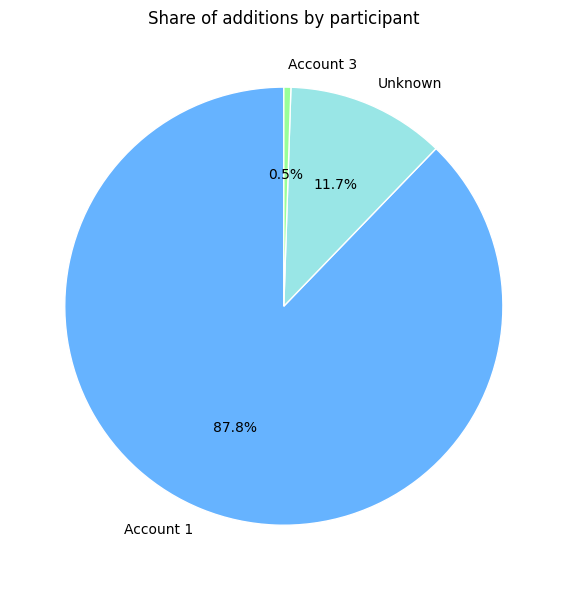

Additions table:


,Participant,Additions
№,,
1,Account 1,510
2,Unknown,68
3,Account 3,3


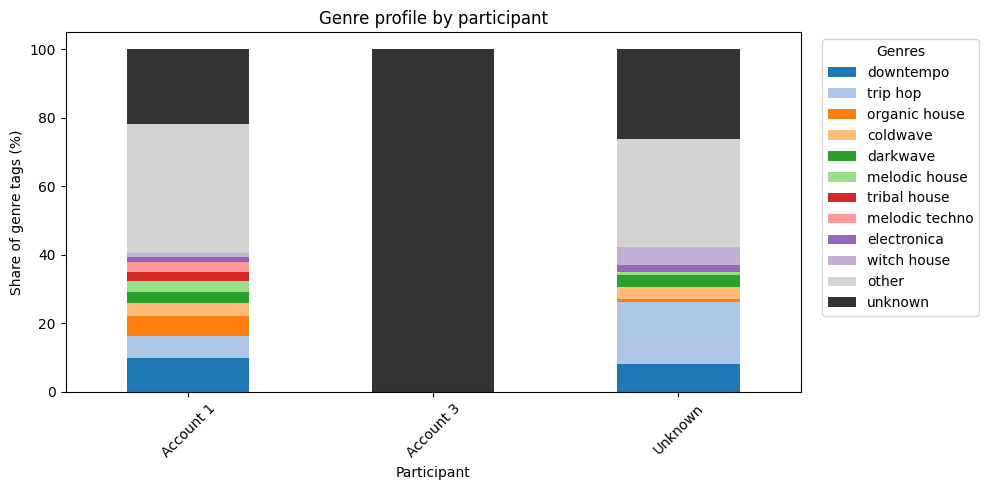

Genre shares by participant (%):


,downtempo,trip hop,organic house,coldwave,darkwave,melodic house,tribal house,melodic techno,electronica,witch house,other,unknown
participant,,,,,,,,,,,,
Account 1,9.8,6.5,6.1,3.7,3.3,3.0,2.9,2.7,1.6,1.2,37.5,21.9
Account 3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
Unknown,8.1,18.0,0.9,3.6,3.6,0.9,0.0,0.0,1.8,5.4,31.5,26.1



Mean audio features by participant:


,valence,energy,danceability,acousticness,instrumentalness,popularity,tempo
actor_name,,,,,,,
Account 1,0.295,0.519,0.622,0.308,0.450,26.514,118.843
Account 3,0.256,0.567,0.430,0.237,0.650,39.333,120.424
Unknown,0.273,0.557,0.609,0.226,0.402,37.838,123.882



Median audio features by participant:


,valence,energy,danceability,acousticness,instrumentalness,popularity,tempo
actor_name,,,,,,,
Account 1,0.237,0.494,0.634,0.218,0.496,28.0,119.952
Account 3,0.309,0.577,0.449,0.095,0.536,45.0,102.962
Unknown,0.239,0.533,0.644,0.124,0.373,38.0,120.540


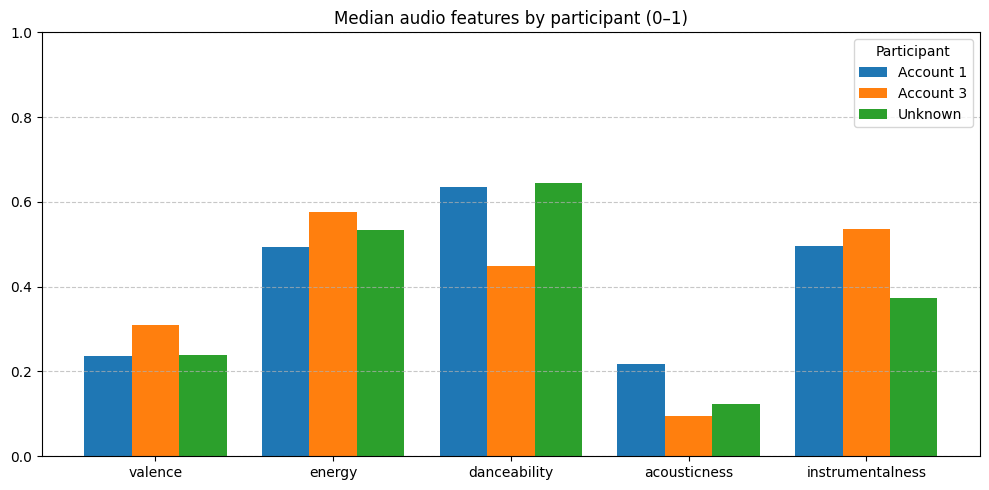


📊 Pairwise significant differences between participants:


,Feature,Pair,Diff,p-value,Signif,Conclusion
№,,,,,,
1,popularity,Account 1 vs Unknown,-11.325,5.148e-06,***,Unknown higher than Account 1


Legend: *** p<0.001, ** p<0.01, * p<0.05; ⚠️ below practical threshold


In [92]:
# 4.2 Collaborator Explorer: детальный разбор плейлиста

# Участники collaborative/contributed, роли, жанры и аудио-профили.
# Параметр selected_playlist = None → только общая таблица.
#
# Полный интерактивный разбор плейлистов — в дашборде (03_dashboard/).
# Здесь оставлен базовый срез для проверки согласованности данных.
# ============================================================
# Параметр: какой плейлист разобрать детально.
# Если None — покажет только общую таблицу участников.
# Пример: selected_playlist = '2025'
# ============================================================
selected_playlist = '2025'

# --- Константы ---
ALPHA = 0.05

# --- owner_map на основе маскированных данных ---
owner_map = (
    playlists_metadata
    .drop_duplicates('name_norm')[['name_norm', 'owner_id']]
    .set_index('name_norm')['owner_id']
    .to_dict()
)

# ========== 1. Общая таблица участников collaborative/contributed ==========
collab_contrib_links = playlist_links[
    playlist_links['playlist_type'].isin(['collaborative', 'contributed'])
].copy()

# Наши → Account N, внешние → user_NN (уже маскированы)
added_by_to_name = {}
for added_by in collab_contrib_links['Added By'].unique():
    if pd.isna(added_by) or added_by == 'unknown':
        name = 'Unknown'
    elif added_by in owner_name_map:
        name = owner_name_map[added_by]
    else:
        name = added_by  # уже user_NN
    added_by_to_name[added_by] = name

collab_contrib_links['actor_name'] = collab_contrib_links['Added By'].map(added_by_to_name)


# Роль: owner / collaborator / contributor / external / unknown
def get_role(row):
    added_by = row['Added By']
    name_norm = row['name_norm']
    owner = owner_map.get(name_norm)

    if pd.isna(added_by) or added_by == 'unknown':
        return 'unknown'
    if added_by in owner_ids_set:
        if owner is not None and added_by == owner:
            return 'owner'
        elif owner is not None:
            return 'collaborator'
        else:
            return 'contributor'
    else:
        return 'external'


collab_contrib_links['role'] = collab_contrib_links.apply(get_role, axis=1)

# Присоединяем аудио и жанры
pl_merged_all = collab_contrib_links.merge(
    tracks_exportify[['spotify_track_uri', 'valence', 'energy', 'danceability',
                      'acousticness', 'instrumentalness', 'popularity', 'tempo',
                      'explicit', 'genres_normalized']],
    left_on='Track URI', right_on='spotify_track_uri', how='left'
)


def get_top_genres(series, n=3):
    genres = series.dropna().str.split(',').explode().str.strip()
    genres = genres[genres != 'unknown']
    if genres.empty:
        return 'none'
    return ', '.join(genres.value_counts().head(n).index.tolist())


features_all = ['valence', 'energy', 'danceability', 'acousticness',
                'instrumentalness', 'popularity', 'tempo']

rows = []
for (name_norm, added_by), group in pl_merged_all.groupby(['name_norm', 'Added By']):
    playlist_name = group['playlist_name'].iloc[0]
    display_name = group['actor_name'].iloc[0]
    role = group['role'].iloc[0]
    top_genres = get_top_genres(group['genres_normalized'])
    track_count = len(group)
    means = {}
    for f in features_all:
        if f in ['popularity', 'tempo']:
            means[f] = round(group[f].mean(), 1)
        else:
            means[f] = round(group[f].mean(), 3)
    rows.append({
        'playlist_name': playlist_name,
        'added_by': added_by,
        'display_name': display_name,
        'role': role,
        'tracks': track_count,
        'top_genres': top_genres,
        **means
    })

summary_df = pd.DataFrame(rows)
summary_df = summary_df.sort_values(['playlist_name', 'tracks'], ascending=[True, False])
summary_df.index = range(1, len(summary_df) + 1)
summary_df.index.name = '№'

print('📊 Full participant table (collaborative & contributed):')
html_table = summary_df.to_html(index=True)
display(HTML(f'<div style="max-height:400px; overflow-y:auto;">{html_table}</div>'))


# ========== 2. Детальный разбор выбранного плейлиста ==========
if selected_playlist is None:
    print('\n💡 Set selected_playlist = "Name" for detailed analysis of one playlist.')
else:
    target_norm = normalize_name(selected_playlist)
    pl_subset = pl_merged_all[pl_merged_all['name_norm'] == target_norm].copy()

    if pl_subset.empty:
        print(f'Playlist "{selected_playlist}" not found.')
    else:
        playlist_name_display = pl_subset['playlist_name'].iloc[0]
        print(f'\n📊 Detailed analysis: {playlist_name_display}\n')

        # --- Роли участников ---
        print('Participants and roles:')
        for actor_name, group in pl_subset.groupby('actor_name'):
            roles = ', '.join(dict.fromkeys(group['role']))
            print(f'  {actor_name}: {roles}')

        # --- Пирог или bar долей добавлений ---
        add_counts = pl_subset['actor_name'].value_counts()
        if len(add_counts) <= 6:
            fig, ax = plt.subplots(figsize=(6, 6))
            colors_pie = [COLORS['primary'], COLORS['secondary'],
                          COLORS['success'], COLORS['accent'],
                          COLORS['muted']][:len(add_counts)]
            ax.pie(add_counts.values, labels=add_counts.index, autopct='%1.1f%%',
                   startangle=90, colors=colors_pie,
                   wedgeprops=dict(edgecolor='white', linewidth=1))
            ax.set_title('Share of additions by participant')
            plt.tight_layout()
            plt.show()
        else:
            add_counts.plot(kind='bar', figsize=(8, 4), color=COLORS['primary'])
            plt.title('Additions by participant')
            plt.ylabel('Number of added tracks')
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()

        add_table = pd.DataFrame({
            'Participant': add_counts.index,
            'Additions': add_counts.values
        })
        add_table.index = range(1, len(add_table) + 1)
        add_table.index.name = '№'
        print('Additions table:')
        display(add_table)

        # --- Жанровый профиль по участникам ---
        all_tags = []
        for _, row in pl_subset.iterrows():
            if pd.notna(row['genres_normalized']):
                all_tags.extend([t.strip() for t in row['genres_normalized'].split(',')])
        all_tags_series = pd.Series(all_tags)
        all_tags_series = all_tags_series[
            (all_tags_series != '') &
            (all_tags_series != 'unknown')
        ]
        top10 = all_tags_series.value_counts().head(10).index.tolist()

        share_rows = []
        for actor_name, group in pl_subset.groupby('actor_name'):
            total_tags = 0
            other_count = 0
            unknown_count = 0
            top_counts = {g: 0 for g in top10}
            for genres in group['genres_normalized'].dropna():
                for tag in genres.split(','):
                    tag = tag.strip()
                    if tag == '' or tag == 'unknown':
                        unknown_count += 1
                        total_tags += 1
                    elif tag in top_counts:
                        top_counts[tag] += 1
                        total_tags += 1
                    else:
                        other_count += 1
                        total_tags += 1
            if total_tags == 0:
                shares = [0] * (len(top10) + 2)
            else:
                shares = [top_counts[g] / total_tags * 100 for g in top10]
                shares += [other_count / total_tags * 100, unknown_count / total_tags * 100]
            share_rows.append([actor_name] + shares)

        genre_share_df = pd.DataFrame(share_rows, columns=['participant'] + top10 + ['other', 'unknown'])
        genre_share_df = genre_share_df.set_index('participant')

        tab20 = plt.cm.tab20.colors
        genre_colors = {g: tab20[i % len(tab20)] for i, g in enumerate(top10)}
        genre_colors['other'] = COLORS['muted']
        genre_colors['unknown'] = '#333333'

        ax = genre_share_df.plot(kind='bar', stacked=True, figsize=(10, 5),
                                 color=[genre_colors[g] for g in genre_share_df.columns])
        ax.set_title('Genre profile by participant')
        ax.set_xlabel('Participant')
        ax.set_ylabel('Share of genre tags (%)')
        ax.legend(title='Genres', bbox_to_anchor=(1.02, 1), loc='upper left')
        ax.tick_params(axis='x', rotation=45)
        plt.tight_layout()
        plt.show()

        print('Genre shares by participant (%):')
        display(genre_share_df.round(1))

        # --- Аудио-характеристики по участникам ---
        means_by_actor = pl_subset.groupby('actor_name')[features_all].mean().round(3)
        medians_by_actor = pl_subset.groupby('actor_name')[features_all].median().round(3)

        print('\nMean audio features by participant:')
        display(means_by_actor)

        print('\nMedian audio features by participant:')
        display(medians_by_actor)

        # График медиан 0–1
        features_01 = ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']
        participants = means_by_actor.index.tolist()
        if participants:
            x = np.arange(len(features_01))
            width = 0.8 / len(participants) if len(participants) > 1 else 0.4
            fig, ax = plt.subplots(figsize=(10, 5))
            for i, p in enumerate(participants):
                ax.bar(x + i * width,
                       [medians_by_actor.loc[p, f] for f in features_01],
                       width, label=p)
            ax.set_xticks(x + width * (len(participants) - 1) / 2)
            ax.set_xticklabels(features_01)
            ax.set_ylim(0, 1)
            ax.legend(title='Participant')
            ax.grid(axis='y', linestyle='--', alpha=0.7)
            plt.title('Median audio features by participant (0–1)')
            plt.tight_layout()
            plt.show()

        # --- Попарное сравнение участников ---
        participants_valid = [
            p for p in participants
            if len(pl_subset[pl_subset['actor_name'] == p]) >= 30
        ]
        if len(participants_valid) >= 2:
            pair_rows = []
            for feat in features_all:
                groups = [
                    pl_subset[pl_subset['actor_name'] == p][feat].dropna()
                    for p in participants_valid
                ]
                if len(groups) < 2:
                    continue
                h, p_kw = stats.kruskal(*groups)
                if p_kw >= ALPHA:
                    continue
                for p1, p2 in combinations(participants_valid, 2):
                    a = pl_subset[pl_subset['actor_name'] == p1][feat].dropna()
                    b = pl_subset[pl_subset['actor_name'] == p2][feat].dropna()
                    if len(a) < 30 or len(b) < 30:
                        continue
                    u, p_pair = stats.mannwhitneyu(a, b, alternative='two-sided')
                    mean_diff = a.mean() - b.mean()
                    thresh = PRACTICAL_THRESHOLDS.get(feat, 0.02)
                    if p_pair < ALPHA and abs(mean_diff) >= thresh:
                        stars = '***' if p_pair < 0.001 else '**' if p_pair < 0.01 else '*'
                        higher, lower = (p1, p2) if mean_diff > 0 else (p2, p1)
                        pair_rows.append({
                            'Feature': feat,
                            'Pair': f'{p1} vs {p2}',
                            'Diff': f'{mean_diff:.3f}',
                            'p-value': f'{p_pair:.3e}',
                            'Signif': stars,
                            'Conclusion': f'{higher} higher than {lower}'
                        })
                    elif p_pair < ALPHA and abs(mean_diff) < thresh:
                        pair_rows.append({
                            'Feature': feat,
                            'Pair': f'{p1} vs {p2}',
                            'Diff': f'{mean_diff:.3f}',
                            'p-value': f'{p_pair:.3e}',
                            'Signif': '⚠️',
                            'Conclusion': 'significant, but small'
                        })
            if pair_rows:
                pair_df = pd.DataFrame(pair_rows)
                pair_df.index = range(1, len(pair_df) + 1)
                pair_df.index.name = '№'
                print('\n📊 Pairwise significant differences between participants:')
                display(pair_df)
                print('Legend: *** p<0.001, ** p<0.01, * p<0.05; ⚠️ below practical threshold')
            else:
                print('\nNo significant pairwise differences detected.')
        else:
            print('\nNot enough participants with ≥30 tracks for statistical comparison.')

### 4.2. Вывод

**Что смотрели.** Разбор одного плейлиста — **2025**. Кто его наполняет, что добавляет каждый участник, как различается их музыкальный профиль.

**Результат.** В плейлисте три участника. **Account 1** (owner) добавил 510 треков, **Unknown** — 68, **Account 3** (collaborator) — 3. **Account 3** даёт 3 трека, у которых жанр не определён — по нему вывод невозможен.

Жанровый профиль **Account 1**: downtempo (9.8%), trip hop (6.5%), organic house (6.1%), coldwave (3.7%). **Unknown**: trip hop (18.0%), downtempo (8.1%), witch house (5.4%). Ядро жанров совпадает — trip hop и downtempo у обоих.

Медианы аудио различаются по popularity: **Account 1** — 28.0, **Unknown** — 38.0. Это единственное различие, которое прошло порог: **Account 1** vs **Unknown**, diff −11.3, p=5.1e−06. Остальные признаки — valence, energy, danceability, acousticness, instrumentalness, tempo — значимых различий не дали.

**Вывод.** **Account 1** — основной наполняющий. **Unknown** добавляет заметную долю (68 из 581 трека, 11.7%) и делает это в том же жанровом поле, но с более популярными треками. Это не внешний участник с другим вкусом, а продолжение того же профиля с другим уровнем popularity.

**Ограничения.** **Account 3** — 3 трека, статистики нет. **Unknown** — природа не определена: это артефакт Exportify, а не подтверждённый внешний участник. У **Unknown** жанр неизвестен в 26.1% случаев, у **Account 1** — 21.9%; жанровые доли считаются по оставшимся тегам. Попарных сравнений три, значимое — одно; без поправки на множественные сравнения это ожидаемо.

## Блок 4. Вывод

**Наполнение.** Совместные плейлисты — не совместная работа. Внешнее участие в них одно, вклад измеряется десятыми долями процента. Всё остальное сделано тремя нашими аккаунтами, и один из них доминирует. Форма **collaborative** в этой коллекции не отражает содержание: плейлист помечен как общий, но наполняется одним человеком.

**Роли.** Один и тот же аккаунт выступает как владелец, соавтор и участник в чужих плейлистах. Это не роли разных людей, а позиции одного пользователя в разных плейлистах. Разделение на «своё» и «чужое» внутри коллекции проходит не по людям, а по тому, в каком плейлисте стоит добавление.

**Contributed.** Тип присутствует в данных одной единицей и не имеет собственного содержания: все его треки уже есть в личных плейлистах. Как отдельная категория он не работает.

**Unknown.** Треки с неопределённым автором идут в том же жанровом поле, что и основные добавления, но с другим уровнем popularity. Это не внешний участник с другим вкусом, а продолжение того же профиля с иным срезом метаданных.

**Связка с блоком 5.** Если совместные плейлисты наполняются нашими аккаунтами, следующий вопрос — слушаются ли они. Блок 5 считает активность и прослушивание по **personal** и **collaborative** и проверяет, совпадает ли структура наполнения с реальным возвратом к этим плейлистам.

# Блок 5. Активность плейлистов


## Блок 5. Активность плейлистов

Блок анализирует только **personal** и **collaborative**. Считает давность обновления, суммарные прослушивания, размер. Делит плейлисты на категории активности и группы по активности и прослушиванию. Сравнивает крайние группы по жанрам и аудио.

Срез — **playlist_links**, **playlists_metadata**, **df_events** с **valid_play**. Единица анализа — плейлист.

**days_since_update** — сколько дней прошло с последнего обновления плейлиста. Считается от максимальной `last_modified` в датасете, а не от даты сбора. Это смещает оценку заброшенности вверх: плейлист, обновлённый вчера относительно даты сбора, может получить `days_since_update` больше нуля, если есть более свежие записи.

**total_listens** — суммарное число **valid_play** по всем трекам плейлиста. Трек в нескольких плейлистах считается в каждом, поэтому сумма по плейлистам больше числа событий.

**num_tracks** — число уникальных треков в плейлисте.

**Категории активности** — по давности обновления:

- **active** — ≤ 30 дней.
- **moderate** — 31–365 дней.
- **abandoned** — > 365 дней.

**Группы по активности и прослушиванию** — пересечение двух осей. Активность — по 365-дневному порогу. Прослушивание — по медиане `total_listens`, рассчитанной по всем 157 плейлистам. Медиана вычисляется в начале 5.2, а не задаётся заранее.

- **active_listened** — обновлялся ≤ 365 дней, прослушиваний выше медианы.
- **active_not_listened** — обновлялся ≤ 365 дней, прослушиваний не выше медианы.
- **abandoned_but_listened** — обновлялся > 365 дней, прослушиваний выше медианы.
- **abandoned_not_listened** — обновлялся > 365 дней, прослушиваний не выше медианы.

**Пороги 30 и 365 дней** — эвристика. Соответствуют месяцу и году, но не выведены из данных.

1. Подготовка и обзор.
2. Группы по активности и прослушиванию.

## 5.1 Активность плейлистов: подготовка и обзор


✅ Playlists prepared for activity analysis: 157
   personal:      128
   collaborative: 29

📊 Listening by playlist type (personal & collaborative):


,Total_listens,Mean_listens,Median_listens
personal,29618,1021.3,505.0
collaborative,22509,175.9,41.0


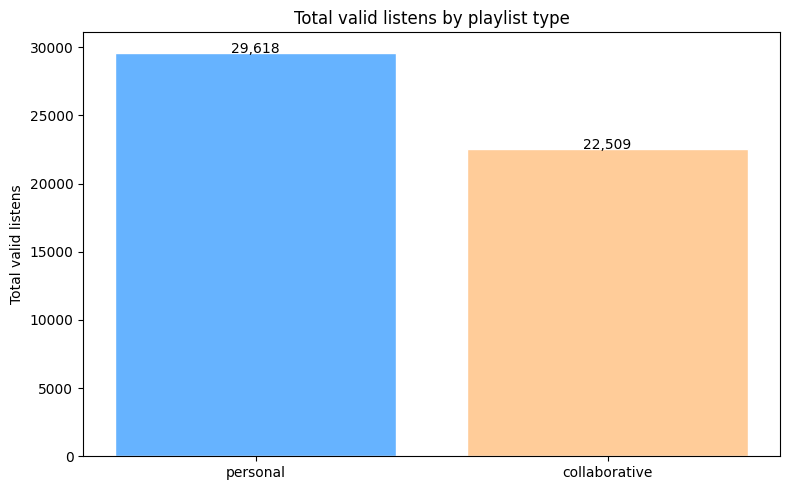


📊 Playlist activity:


,Category,Criterion,Count,Share (%)
№,,,,
1,active,≤ 30 days,10,6.4
2,moderate,31–365 days,36,22.9
3,abandoned,> 365 days,111,70.7



📊 Activity by playlist type:


playlist_type,personal,collaborative
activity,,
active,3,7
moderate,21,15
abandoned,104,7



📊 Descriptive stats:


,Metric,Description,Median,Mean,N
№,,,,,
1,days_since_update,Days since last playlist update,1785.0,1297.0,157
2,total_listens,Total valid listens across all tracks,61.0,332.0,157
3,num_tracks,Number of unique tracks in playlist,54.0,83.8,157


,name_norm,playlist_type,num_tracks,days_since_update,total_listens
№,,,,,
1,!!!,personal,64,1956,92
2,#fall18,personal,42,2114,1
3,#leto_electro,personal,10,2114,6
4,#spring,personal,106,2114,36
5,'20spring,personal,83,2114,51
6,'s,personal,41,2114,3
7,02.2020,personal,37,1697,11
8,03._trip_pas_pop,personal,124,2114,66
9,1,personal,60,0,299


In [93]:
# 5.1 Активность плейлистов: подготовка и обзор

# Анализируем только personal и collaborative.
# В contributed и foreign большая часть добавлений — чужие,
# их активность не отражает личное поведение пользователя.
#
# Данные уже маскированы в блоке 0: аккаунты → account_N,
# названия личных плейлистов → personal_*.

# ==========================================
# Подготовка
# ==========================================
# Валидные прослушивания по трекам
valid_events = df_events[df_events['valid_play']]
track_listen_counts = (
    valid_events
    .groupby('spotify_track_uri')
    .size()
    .reset_index(name='valid_listens')
)

# Связи трек–плейлист только для personal и collaborative
own_links = playlist_links[
    playlist_links['playlist_type'].isin(['personal', 'collaborative'])
].copy()

pl_tracks = own_links[['name_norm', 'playlist_type', 'Track URI']].drop_duplicates()
pl_tracks = pl_tracks.merge(
    track_listen_counts,
    left_on='Track URI', right_on='spotify_track_uri', how='left'
)
pl_tracks['valid_listens'] = pl_tracks['valid_listens'].fillna(0).astype(int)

# Агрегация по плейлисту
playlist_agg = pl_tracks.groupby(['name_norm', 'playlist_type']).agg(
    total_listens=('valid_listens', 'sum'),
    unique_tracks=('Track URI', 'nunique')
).reset_index()

# Метаданные
meta = playlists_metadata.drop_duplicates('name_norm')[
    ['name_norm', 'num_tracks', 'last_modified']
].copy()
meta['last_modified_dt'] = pd.to_datetime(meta['last_modified'], errors='coerce')
max_date = meta['last_modified_dt'].max()
meta['days_since_update'] = (max_date - meta['last_modified_dt']).dt.days

# Объединяем
pl_activity = playlist_agg.merge(
    meta[['name_norm', 'num_tracks', 'days_since_update']],
    on='name_norm', how='left'
).dropna(subset=['days_since_update']).copy()

print(f'✅ Playlists prepared for activity analysis: {len(pl_activity)}')
print(f'   personal:      {(pl_activity["playlist_type"]=="personal").sum()}')
print(f'   collaborative: {(pl_activity["playlist_type"]=="collaborative").sum()}')


# ==========================================
# Обзор прослушиваемости по типам
# ==========================================
print('\n📊 Listening by playlist type (personal & collaborative):')
listen_by_type = pl_activity.groupby('playlist_type').agg(
    Total_listens=('total_listens', 'sum'),
    Mean_listens=('total_listens', 'mean'),
    Median_listens=('total_listens', 'median')
).round(1)
listen_by_type.index = ['personal', 'collaborative']

display(listen_by_type)

# Bar plot суммарных прослушиваний
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    listen_by_type.index,
    listen_by_type['Total_listens'],
    color=[colors_map['personal'], colors_map['collaborative']],
    edgecolor='white'
)
ax.set_ylabel('Total valid listens')
ax.set_title('Total valid listens by playlist type')
for bar, val in zip(bars, listen_by_type['Total_listens']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:,.0f}', ha='center')
plt.tight_layout()
plt.show()


# ==========================================
# Категории активности
# ==========================================
def activity_category(days):
    if days <= 30:
        return 'active', '≤ 30 days'
    elif days <= 365:
        return 'moderate', '31–365 days'
    else:
        return 'abandoned', '> 365 days'


pl_activity[['activity', 'criterion']] = pl_activity['days_since_update'].apply(
    lambda d: pd.Series(activity_category(d))
)

activity_counts = (
    pl_activity['activity']
    .value_counts()
    .reindex(['active', 'moderate', 'abandoned'])
    .fillna(0)
    .astype(int)
)
activity_pct = (activity_counts / len(pl_activity) * 100).round(1)

activity_df = pd.DataFrame({
    'Category': activity_counts.index,
    'Criterion': ['≤ 30 days', '31–365 days', '> 365 days'],
    'Count': activity_counts.values,
    'Share (%)': activity_pct.values
})
activity_df.index = activity_df.index + 1
activity_df.index.name = '№'

print('\n📊 Playlist activity:')
display(activity_df)

# Кросс-таблица активность × тип
activity_by_type = pd.crosstab(pl_activity['activity'], pl_activity['playlist_type'])
activity_by_type = activity_by_type.reindex(
    index=['active', 'moderate', 'abandoned'],
    columns=['personal', 'collaborative'],
    fill_value=0
)
print('\n📊 Activity by playlist type:')
display(activity_by_type)


# ==========================================
# Описательные статистики
# ==========================================
print('\n📊 Descriptive stats:')
stats_rows = []
for metric, description in [
    ('days_since_update', 'Days since last playlist update'),
    ('total_listens', 'Total valid listens across all tracks'),
    ('num_tracks', 'Number of unique tracks in playlist')
]:
    stats_rows.append({
        'Metric': metric,
        'Description': description,
        'Median': round(pl_activity[metric].median(), 1),
        'Mean': round(pl_activity[metric].mean(), 1),
        'N': int(pl_activity[metric].notna().sum())
    })

stats_df = pd.DataFrame(stats_rows)
stats_df.index = stats_df.index + 1
stats_df.index.name = '№'
display(stats_df)


# ==========================================
# Scatter: давность обновления vs прослушивания
# ============================================================
# Цвет точки — тип плейлиста, размер — число треков.
# Вертикальные линии: 30 и 365 дней — границы активности.
# Горизонтальная — медиана прослушиваний.
fig = px.scatter(
    pl_activity,
    x='days_since_update',
    y='total_listens',
    size='num_tracks',
    color='playlist_type',
    color_discrete_map={
        'personal': colors_map['personal'],
        'collaborative': colors_map['collaborative'],
    },
    hover_name='name_norm',
    hover_data={
        'playlist_type': True,
        'num_tracks': True,
        'days_since_update': True,
        'total_listens': True,
    },
    labels={
        'days_since_update': 'Days since last update',
        'total_listens': 'Total valid listens',
        'num_tracks': 'Number of tracks',
        'playlist_type': 'Playlist type',
        'name_norm': 'Playlist',
    },
    title='Playlist activity: update vs. listening'
)

fig.add_vline(x=30, line_dash='dash', line_color=COLORS['line_success'],
              annotation_text='30 days')
fig.add_vline(x=365, line_dash='dash', line_color=COLORS['line_accent'],
              annotation_text='365 days')
fig.update_layout(
    yaxis_type='log',
    hovermode='closest',
    height=700
)
fig.show()

# Таблица данных с прокруткой
scatter_data = pl_activity[
    ['name_norm', 'playlist_type', 'num_tracks', 'days_since_update', 'total_listens']
].copy()
scatter_data.index = scatter_data.index + 1
scatter_data.index.name = '№'

html_table = scatter_data.to_html()
display(HTML(f'<div style="max-height:400px; overflow-y:auto;">{html_table}</div>'))

### 5.1. Вывод

**Что смотрели.** 157 плейлистов после подготовки: 128 **personal** и 29 **collaborative**. Давность обновления, суммарные прослушивания, размер.

**Результат.** Медиана `days_since_update` — 1785 дней. Активных (≤30 дней) — 6.4%, умеренных (31–365) — 22.9%, заброшенных (>365) — 70.7%.

По типам картина расходится. **Personal**: 3 активных, 21 умеренный, 104 заброшенных. **Collaborative**: 7 активных, 15 умеренных, 7 заброшенных.

По прослушиванию — обратное. Суммарно **personal** даёт 29 618 валидных прослушиваний, **collaborative** — 22 509. Медиана на плейлист: 505 у **personal** против 41 у **collaborative**.

**Вывод.** Коллекция старая: медианный плейлист не обновлялся почти пять лет. Но заброшенность обновления не означает заброшенность слушания. **Personal** плейлисты накапливают прослушивания и остаются в ротации, несмотря на давность. **Collaborative** — свежие и обновляемые, но с меньшим накопленным объёмом. Распределение прослушиваний у **collaborative** сильно скошено: медиана 41 при сумме 22 509 означает, что основной объём несут единичные плейлисты, а большинство почти не слушается.

**Ограничения.** Агрегация по плейлистам суммирует прослушивания треков. Трек, попадающий в несколько плейлистов, считается в каждом. Суммарные прослушивания не равны числу событий.

`days_since_update` считается от максимальной даты `last_modified` в датасете, а не от даты сбора. Это смещает оценку заброшенности вверх.

## 5.2 Группы по активности и прослушиванию


📊 Playlist groups by activity and listening:


,Group,Description,Count,Share (%)
№,,,,
1,active_listened,active and frequently listened,39,24.8
2,active_not_listened,active but rare,7,4.5
3,abandoned_but_listened,abandoned but still listened,39,24.8
4,abandoned_not_listened,abandoned and not listened,72,45.9


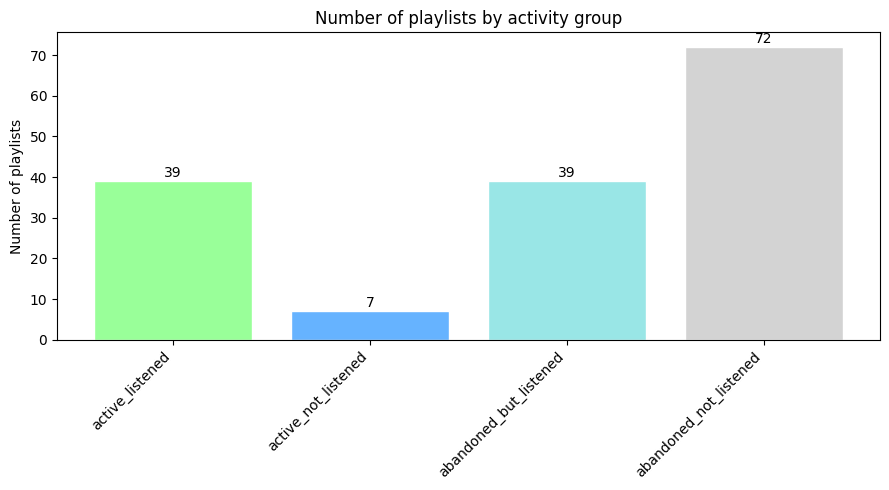


📊 Playlist type within groups (absolute):


,Group,personal,collaborative
0,active_listened (active and frequently listened),18,21
1,active_not_listened (active but rare),6,1
2,abandoned_but_listened (abandoned but still li...,34,5
3,abandoned_not_listened (abandoned and not list...,70,2



📊 Playlist type within groups (% of group):


,Group,"personal, %","collaborative, %"
0,active_listened (active and frequently listened),46.2,53.8
1,active_not_listened (active but rare),85.7,14.3
2,abandoned_but_listened (abandoned but still li...,87.2,12.8
3,abandoned_not_listened (abandoned and not list...,97.2,2.8


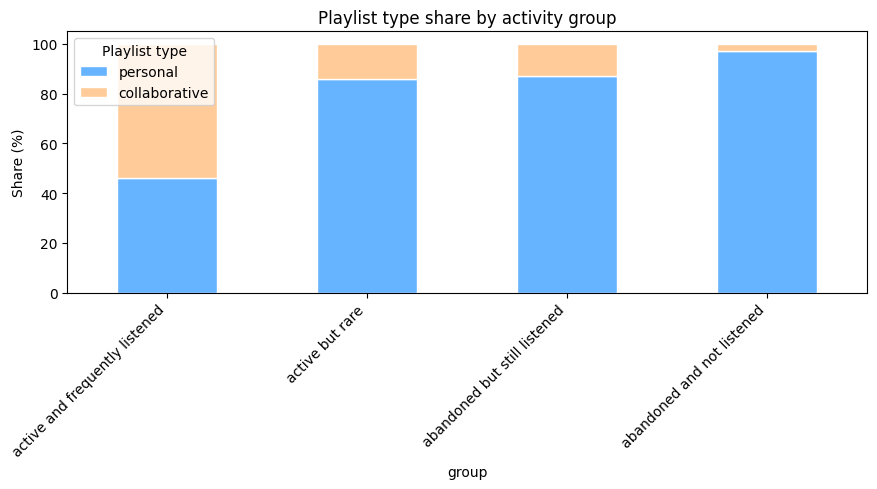


📊 Group summary:


,Group,Playlists,Mean size,Median size,Mean days since,Median days since,Total listens,Mean listens
0,active_listened (active and frequently listened),39,115.6,64.0,115.9,61.0,34314,879.8
1,active_not_listened (active but rare),7,10.4,11.0,212.0,207.0,264,37.7
2,abandoned_but_listened (abandoned but still li...,39,81.5,68.0,1378.5,1584.0,16465,422.2
3,abandoned_not_listened (abandoned and not list...,72,75.0,44.0,1998.1,2114.0,1084,15.1



📊 Unknown genre check:
⚠️ Active listened: 38.8% without genre — conclusions limited.
✅ Abandoned not listened: 20.9% without valid genre.

📊 Top-10 genres (top-5 coverage: active 40.3%, abandoned 30.2%):


,Genre,Active (%),Abandoned (%)
№,,,
4,downtempo,14.0,5.1
9,organic house,9.8,2.9
15,trip hop,7.3,5.1
13,trance,0.0,7.5
12,progressive trance,0.0,7.4
6,melodic house,2.2,3.7
14,tribal house,5.8,0.0
7,melodic techno,2.2,3.4
11,progressive house,0.0,5.2


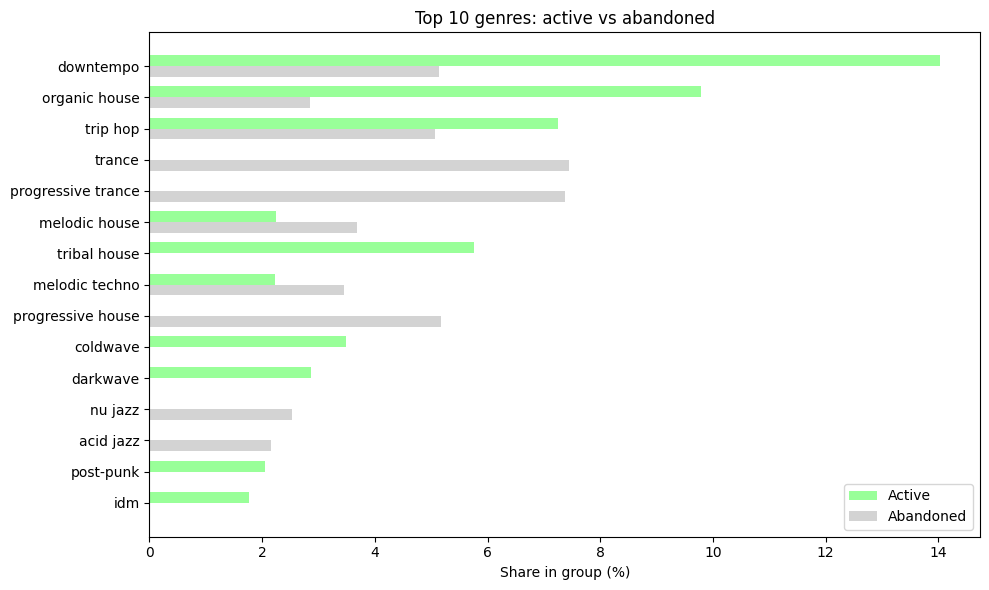


📊 Mean features:


,Feature,Active,Abandoned
№,,,
1,valence,0.286,0.339
2,energy,0.502,0.610
3,danceability,0.601,0.586
4,acousticness,0.350,0.257
5,instrumentalness,0.506,0.531
6,popularity,28.6,12.0
7,tempo,119.0,120.9



📊 Significance check (Mann-Whitney U):


,Feature,Mean diff,p-value,Threshold,Verdict
№,,,,,
1,valence,-0.053,9.506e-14,0.02,✅
2,energy,-0.107,1.096e-98,0.02,✅
3,danceability,0.015,1.623e-03,0.02,⚠️
4,acousticness,0.093,1.305e-77,0.02,✅
5,instrumentalness,-0.025,9.379e-04,0.02,✅
6,popularity,16.6,0.000e+00,5.0,✅
7,tempo,-1.9,1.097e-12,2.0,⚠️



🔍 Auto conclusion:
✅ valence: active lower by 0.053 (threshold 0.02)
✅ energy: active lower by 0.107 (threshold 0.02)
⚠️ danceability: significant, but below threshold (0.015 < 0.02)
✅ acousticness: active higher by 0.093 (threshold 0.02)
✅ instrumentalness: active lower by 0.025 (threshold 0.02)
✅ popularity: active higher by 16.600 (threshold 5.0)
⚠️ tempo: significant, but below threshold (1.900 < 2.0)

🔍 Block 5 summary:
Total playlists analyzed: 157
Active (≤30 days):       10 (6.4%)
Moderate (31–365 days):  36 (22.9%)
Abandoned (>365 days):   111 (70.7%)

Groups by activity and listening:
   active and frequently listened: 39 (24.8%)
   active but rare: 7 (4.5%)
   abandoned but still listened: 39 (24.8%)
   abandoned and not listened: 72 (45.9%)

Top-5 genre coverage:
   Active:    40.3%
   Abandoned: 30.2%


In [94]:
# 5.2 Группы по активности и прослушиванию

# pl_activity создан в 5.1.

# ==========================================
# Классификация групп
# ==========================================
median_listens = pl_activity['total_listens'].median()


def classify_group(row):
    if row['days_since_update'] <= 365 and row['total_listens'] > median_listens:
        return 'active_listened'
    elif row['days_since_update'] <= 365 and row['total_listens'] <= median_listens:
        return 'active_not_listened'
    elif row['days_since_update'] > 365 and row['total_listens'] > median_listens:
        return 'abandoned_but_listened'
    else:
        return 'abandoned_not_listened'


pl_activity['group'] = pl_activity.apply(classify_group, axis=1)

group_order = [
    'active_listened',
    'active_not_listened',
    'abandoned_but_listened',
    'abandoned_not_listened',
]

group_labels = {
    'active_listened': 'active and frequently listened',
    'active_not_listened': 'active but rare',
    'abandoned_but_listened': 'abandoned but still listened',
    'abandoned_not_listened': 'abandoned and not listened',
}

group_counts = pl_activity['group'].value_counts().reindex(group_order).fillna(0).astype(int)
group_pct = (group_counts / len(pl_activity) * 100).round(1)

group_df = pd.DataFrame({
    'Group': group_counts.index,
    'Description': [group_labels[g] for g in group_counts.index],
    'Count': group_counts.values,
    'Share (%)': group_pct.values
})
group_df.index = group_df.index + 1
group_df.index.name = '№'

print('📊 Playlist groups by activity and listening:')
display(group_df)

# Bar plot количества
group_colors = {
    'active_listened': COLORS['success'],
    'active_not_listened': COLORS['primary'],
    'abandoned_but_listened': COLORS['secondary'],
    'abandoned_not_listened': COLORS['muted'],
}

plt.figure(figsize=(9, 5))
bars = plt.bar(
    group_counts.index, group_counts.values,
    color=[group_colors[g] for g in group_counts.index],
    edgecolor='white'
)
plt.xticks(rotation=45, ha='right')
plt.title('Number of playlists by activity group')
plt.ylabel('Number of playlists')
for bar, val in zip(bars, group_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             str(val), ha='center')
plt.tight_layout()
plt.show()


# ==========================================
# Распределение типов внутри групп
# ==========================================
group_type = pd.crosstab(pl_activity['group'], pl_activity['playlist_type'])
group_type = group_type.reindex(
    index=group_order,
    columns=['personal', 'collaborative'],
    fill_value=0
)
group_type_pct = group_type.div(group_type.sum(axis=1), axis=0) * 100

print('\n📊 Playlist type within groups (absolute):')
group_type_abs = group_type.reset_index()
group_type_abs.columns = ['Group', 'personal', 'collaborative']
group_type_abs['Group'] = group_type_abs['Group'].map(lambda x: f'{x} ({group_labels[x]})')
display(group_type_abs)

print('\n📊 Playlist type within groups (% of group):')
group_type_pct_reset = group_type_pct.reset_index()
group_type_pct_reset.columns = ['Group', 'personal, %', 'collaborative, %']
group_type_pct_reset['Group'] = group_type_pct_reset['Group'].map(lambda x: f'{x} ({group_labels[x]})')
display(group_type_pct_reset.round(1))

# Stacked bar долей
fig, ax = plt.subplots(figsize=(9, 5))
group_type_pct.plot(
    kind='bar', stacked=True, ax=ax,
    color=[colors_map['personal'], colors_map['collaborative']],
    edgecolor='white'
)
ax.set_xticklabels([group_labels[g] for g in group_type_pct.index], rotation=45, ha='right')
ax.set_title('Playlist type share by activity group')
ax.set_ylabel('Share (%)')
ax.legend(title='Playlist type')
plt.tight_layout()
plt.show()


# ==========================================
# Сводные характеристики групп
# ==========================================
group_summary = pl_activity.groupby('group').agg(
    Playlists=('name_norm', 'nunique'),
    Mean_size=('num_tracks', 'mean'),
    Median_size=('num_tracks', 'median'),
    Mean_days_since=('days_since_update', 'mean'),
    Median_days_since=('days_since_update', 'median'),
    Total_listens=('total_listens', 'sum'),
    Mean_listens=('total_listens', 'mean')
).reindex(group_order).round(1)

group_summary_reset = group_summary.reset_index()
group_summary_reset.columns = [
    'Group', 'Playlists', 'Mean size', 'Median size',
    'Mean days since', 'Median days since',
    'Total listens', 'Mean listens'
]
group_summary_reset['Group'] = group_summary_reset['Group'].map(
    lambda x: f'{x} ({group_labels[x]})'
)

print('\n📊 Group summary:')
display(group_summary_reset)

# Scatter по группам
fig = px.scatter(
    pl_activity,
    x='days_since_update',
    y='total_listens',
    color='group',
    size='num_tracks',
    hover_name='name_norm',
    color_discrete_map=group_colors,
    labels={
        'days_since_update': 'Days since last update',
        'total_listens': 'Total valid listens',
        'num_tracks': 'Number of tracks',
        'group': 'Activity group',
    },
    title='Playlists by activity group',
    log_y=True,
    height=650
)
fig.show()


# ==========================================
# Сравнение крайних групп: активные и слушаемые vs заброшенные и неслушаемые
# ==========================================
active_names = set(pl_activity.loc[pl_activity['group'] == 'active_listened', 'name_norm'])
abandoned_names = set(pl_activity.loc[pl_activity['group'] == 'abandoned_not_listened', 'name_norm'])

# Контроль unknown
print('\n📊 Unknown genre check:')
active_merged = (
    playlist_links[playlist_links['name_norm'].isin(active_names)][['Track URI']]
    .drop_duplicates()
    .merge(
        tracks_exportify[['spotify_track_uri', 'genres_normalized']],
        left_on='Track URI', right_on='spotify_track_uri', how='left'
    )
)
abandoned_merged = (
    playlist_links[playlist_links['name_norm'].isin(abandoned_names)][['Track URI']]
    .drop_duplicates()
    .merge(
        tracks_exportify[['spotify_track_uri', 'genres_normalized']],
        left_on='Track URI', right_on='spotify_track_uri', how='left'
    )
)
show_unknown_share(active_merged, 'Active listened')
show_unknown_share(abandoned_merged, 'Abandoned not listened')


# --- Жанровый профиль ---
def get_genre_share(names):
    links_sub = playlist_links[playlist_links['name_norm'].isin(names)][['Track URI']].drop_duplicates()
    merged = links_sub.merge(
        tracks_exportify[['spotify_track_uri', 'genres_normalized']],
        left_on='Track URI', right_on='spotify_track_uri', how='left'
    )
    genres = merged['genres_normalized'].dropna().str.split(',').explode().str.strip()
    genres = genres[genres != 'unknown']
    total = len(genres)
    if total == 0:
        return pd.Series(dtype=float), 0
    share = genres.value_counts().head(10) / total * 100
    return share, total


active_share, active_total = get_genre_share(active_names)
abandoned_share, abandoned_total = get_genre_share(abandoned_names)

active_top5_cover = active_share.head(5).sum() if len(active_share) >= 5 else active_share.sum()
abandoned_top5_cover = abandoned_share.head(5).sum() if len(abandoned_share) >= 5 else abandoned_share.sum()

all_genres = sorted(set(active_share.index) | set(abandoned_share.index))
compare_genres = pd.DataFrame({
    'Genre': all_genres,
    'Active (%)': [active_share.get(g, 0) for g in all_genres],
    'Abandoned (%)': [abandoned_share.get(g, 0) for g in all_genres]
})
compare_genres['Total'] = compare_genres['Active (%)'] + compare_genres['Abandoned (%)']
compare_genres = compare_genres.sort_values('Total', ascending=False)

print(f'\n📊 Top-10 genres (top-5 coverage: active {active_top5_cover:.1f}%, abandoned {abandoned_top5_cover:.1f}%):')
compare_display = compare_genres[['Genre', 'Active (%)', 'Abandoned (%)']].copy()
compare_display.index = compare_display.index + 1
compare_display.index.name = '№'
display(compare_display.round(1))

# Bar chart
fig, ax = plt.subplots(figsize=(10, 6))
y = range(len(compare_genres))
height = 0.35
ax.barh([i - height/2 for i in y], compare_genres['Active (%)'], height,
        color=COLORS['success'], label='Active')
ax.barh([i + height/2 for i in y], compare_genres['Abandoned (%)'], height,
        color=COLORS['muted'], label='Abandoned')
ax.set_yticks(list(y))
ax.set_yticklabels(compare_genres['Genre'])
ax.invert_yaxis()
ax.set_xlabel('Share in group (%)')
ax.set_title('Top 10 genres: active vs abandoned')
ax.legend()
plt.tight_layout()
plt.show()


# --- Аудио-характеристики и статистика ---
features_compare = ['valence', 'energy', 'danceability', 'acousticness',
                    'instrumentalness', 'popularity', 'tempo']


def get_group_tracks(names):
    uris = playlist_links[playlist_links['name_norm'].isin(names)]['Track URI'].unique()
    return tracks_exportify[tracks_exportify['spotify_track_uri'].isin(uris)]


active_tracks = get_group_tracks(active_names)
abandoned_tracks = get_group_tracks(abandoned_names)

means_rows = []
for f in features_compare:
    a_mean = active_tracks[f].mean()
    b_mean = abandoned_tracks[f].mean()
    if f in ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']:
        a_str = f'{a_mean:.3f}'
        b_str = f'{b_mean:.3f}'
    else:
        a_str = f'{a_mean:.1f}'
        b_str = f'{b_mean:.1f}'
    means_rows.append({
        'Feature': f,
        'Active': a_str,
        'Abandoned': b_str
    })

means_df = pd.DataFrame(means_rows)
means_df.index = means_df.index + 1
means_df.index.name = '№'
print('\n📊 Mean features:')
display(means_df)

# Статистика
results = []
for feat in features_compare:
    a = active_tracks[feat].dropna()
    b = abandoned_tracks[feat].dropna()
    if len(a) < 30 or len(b) < 30:
        results.append({
            'Feature': feat,
            'Mean diff': None,
            'p-value': None,
            'Threshold': PRACTICAL_THRESHOLDS.get(feat, 0.02),
            'Verdict': 'insufficient data'
        })
        continue
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    mean_diff = a.mean() - b.mean()
    thresh = PRACTICAL_THRESHOLDS.get(feat, 0.02)
    if p < ALPHA and abs(mean_diff) >= thresh:
        verdict = '✅'
    elif p < ALPHA and abs(mean_diff) < thresh:
        verdict = '⚠️'
    else:
        verdict = '—'

    if feat in ['popularity', 'tempo']:
        diff_str = f'{mean_diff:.1f}'
        thresh_str = f'{thresh:.1f}'
    else:
        diff_str = f'{mean_diff:.3f}'
        thresh_str = f'{thresh:.2f}'

    results.append({
        'Feature': feat,
        'Mean diff': diff_str,
        'p-value': f'{p:.3e}',
        'Threshold': thresh_str,
        'Verdict': verdict
    })

results_df = pd.DataFrame(results)
results_df.index = results_df.index + 1
results_df.index.name = '№'
print('\n📊 Significance check (Mann-Whitney U):')
display(results_df)

# Автоматический вывод
print('\n🔍 Auto conclusion:')
for _, row in results_df.iterrows():
    if row['Verdict'] == '✅':
        feat = row['Feature']
        a_mean = active_tracks[feat].dropna().mean()
        b_mean = abandoned_tracks[feat].dropna().mean()
        direction = 'higher' if a_mean > b_mean else 'lower'
        diff = abs(float(row['Mean diff']))
        print(f'✅ {feat}: active {direction} by {diff:.3f} (threshold {row["Threshold"]})')
    elif row['Verdict'] == '⚠️':
        feat = row['Feature']
        diff = abs(float(row['Mean diff']))
        print(f'⚠️ {feat}: significant, but below threshold ({diff:.3f} < {row["Threshold"]})')


# ==========================================
# Итоговый вывод по блоку
# ==========================================
print('\n🔍 Block 5 summary:')
print(f'Total playlists analyzed: {len(pl_activity)}')
print(f'Active (≤30 days):       {activity_counts["active"]} ({activity_pct["active"]}%)')
print(f'Moderate (31–365 days):  {activity_counts["moderate"]} ({activity_pct["moderate"]}%)')
print(f'Abandoned (>365 days):   {activity_counts["abandoned"]} ({activity_pct["abandoned"]}%)')
print()
print('Groups by activity and listening:')
for g in group_order:
    print(f'   {group_labels[g]}: {group_counts[g]} ({group_pct[g]}%)')
print()
print('Top-5 genre coverage:')
print(f'   Active:    {active_top5_cover:.1f}%')
print(f'   Abandoned: {abandoned_top5_cover:.1f}%')

### 5.2. Вывод

**Что смотрели.** Разбиение 157 плейлистов на четыре группы
по активности и прослушиванию. Как группы различаются по типу,
размеру, жанрам, аудио.

**Результат.** **active_listened** — 39 (24.8%),
**active_not_listened** — 7 (4.5%), **abandoned_but_listened** —
39 (24.8%), **abandoned_not_listened** — 72 (45.9%).

Тип внутри групп распределён неравномерно. **Collaborative**
сосредоточен в **active_listened**: 21 из 29 плейлистов (72%).
В **abandoned_not_listened** его 2 из 72. **Personal**, наоборот,
доминирует в заброшенных группах: 70 из 128
в **abandoned_not_listened**.

Прослушивание концентрировано. **active_listened** — 34 314
суммарных прослушиваний при среднем 879.8 на плейлист.
**abandoned_not_listened** — 1084 при среднем 15.1. Разница
по среднему — почти в 60 раз.

Жанры. **Active**: downtempo 14.0%, organic house 9.8%,
trip hop 7.3%, tribal house 5.8%. **Abandoned**: trance 7.5%,
progressive trance 7.4%, progressive house 5.2%. Это разные
жанровые поля, не оттенки одного.

Аудио. **Active** ниже по valence (0.286 против 0.339)
и energy (0.502 против 0.610), выше по acousticness (0.350
против 0.257), ниже по instrumentalness (0.506 против 0.531),
значительно выше по popularity (28.6 против 12.0). Пять различий
прошли порог практической существенности. Danceability и tempo —
значимы статистически, ниже порога.

**Вывод.** Группы неоднородны по типу: **active_listened** —
единственная, где **personal** и **collaborative** сопоставимы.
Остальные почти целиком **personal**. Контраст «активное против
заброшенного» — это в значительной степени контраст
«**collaborative** против **personal**»: активные популярнее,
акустичнее, менее энергичные, и это те же признаки, по которым
**collaborative** отличался в блоке 2.

**Ограничение: конфаунд с типом плейлиста.** Различия по жанрам
и аудио между активными и заброшенными конфаундированы типом:
активные — наполовину collaborative, заброшенные — почти целиком
personal. Наблюдаемые различия могут отражать разницу типов,
а не активности. Разделить два эффекта на этих данных нельзя:
стратификация по типу оставит слишком мало наблюдений в каждой
ячейке.

**Ограничение: unknown.** В жанрах у **active** — 38.8%. Это выше
30%, жанровые выводы по активной группе ограничены.

**Ограничение: порог медианы.** Порог медианы прослушиваний,
разделяющий «listened» и «not listened», — 61. Он эвристический.

## Блок 5. Вывод

**Активность.** Медианный плейлист не обновлялся пять лет. Заброшенных — большинство, но часть из них продолжает слушаться. Заброшенность обновления и заброшенность слушания — не одно и то же.

**Тип.** **Collaborative** и **personal** живут по-разному. Первый сосредоточен в активной и прослушиваемой группе, второй — в заброшенной. Контраст «активное против заброшенного» в значительной степени повторяет контраст «**collaborative** против **personal**». Жанры и аудио-профили групп совпадают с тем, чем эти два типа различались в блоке 2.

**Прослушивание.** Сконцентрировано. Основной объём создают единичные плейлисты, а не множество мелких. Заброшенная и неслушаемая группа даёт на плейлист в десятки раз меньше, чем активная.

**Ограничения.** Различия по жанрам и аудио между активными и заброшенными конфаундированы типом плейлиста: активные — наполовину **collaborative**, заброшенные — почти целиком **personal**. **Unknown** в жанрах у активной группы 38.8% — жанровые выводы по ней ограничены. Суммарные прослушивания агрегированы по плейлистам, трек в нескольких плейлистах считается несколько раз.

**Связка с блоком 6.** Блок показывает, что мёртвый груз есть, но не объясняет, откуда он. Блок 6 разбирает способ наполнения и проверяет, связан ли он с попаданием в активную группу или в заброшенную.

# Блок 6. Типы наполнения

## Блок 6. Типы наполнения

Блок классифицирует **personal** и **collaborative** плейлисты по способу формирования. Смотрит распределение по годам, связь с активностью, длительность пополнения, широту и глубину прослушивания, жанры и аудио. Отдельно разбирает **curated**: подгруппы по регулярности, их жизнь во времени, выживаемость по прослушиванию.

Срез — **playlist_links**, **df_events** с **valid_play**, **tracks_exportify**. Единица анализа — плейлист.

**Mass_import** — один день добавления, ≥100 треков, длительность дня ≤15 минут, прослушано до добавления <30%. Слепой перенос библиотеки.

**Batch** — только быстрые серии добавлений (интервал ≤2 минуты), без одиночных треков. Пакетное копирование.

**Curated** — есть хотя бы одно одиночное добавление или разрыв >2 минут. Осознанный отбор.

**Пороги классификации** (100 треков, 15 минут, 30% прослушивания до добавления, 2 минуты) — эвристика, не выведенная из данных. Закреплены для воспроизводимости.

**Метрики пополнения** (для **curated**):

- **add_days** — число уникальных дней, в которые добавлялись треки.
- **lifespan_days** — разница в днях между первым и последним днём добавления.
- **avg_session_size** — среднее число треков за день добавления. Синоним — «порция».
- **max_session_size** — максимум треков за один день.
- **median_interval_days** — медиана разниц в днях между соседними днями добавления.
- **interval_cv** — **CV интервалов**.
- **top_day_share** — доля треков, добавленных в самый активный день, от всех треков плейлиста.

**CV интервалов** — коэффициент вариации интервалов между днями добавления. Считается как `std / mean` по интервалам. Безразмерная мера разброса: чем ниже, тем регулярнее пополнение. Не зависит от масштаба, поэтому сравним между плейлистами с разной частотой добавления.

**Подгруппы curated** — по регулярности пополнения.

- **Few_sessions** — меньше 5 дней добавления. CV по ним не считается: на 4 и менее интервалах std и mean нестабильны.
- **Steady** — CV ≤ 0.5.
- **Mixed** — 0.5 < CV ≤ 1.5.
- **Bursty** — CV > 1.5.

**Breadth (широта)** — доля уникальных треков плейлиста, прослушанных хотя бы раз валидно. Считается как `listened_tracks / total_tracks`.

**Depth (глубина)** — среднее число валидных прослушиваний на прослушанный трек. Считается как `total_listens / listened_tracks`. Треки с нулевым прослушиванием не учитываются.

**Когорта** — плейлисты одного года создания.

**Cohort survival (выживаемость по пополнению)** — доля плейлистов когорты, которые ещё пополнялись в каждый последующий год. Плейлист считается выжившим в году Y, если его последнее добавление не раньше Y.

**Cohort listening survival (выживаемость по прослушиванию)** — доля плейлистов когорты, которые активны в году Y. Плейлист активен, если не менее **MIN_UNIQUE_SHARE** его уникальных треков прослушано валидно в этом году. **MIN_UNIQUE_SHARE** = 0.10.

1. Классификация типов наполнения.
2. Распределение по годам создания.
3. Типы наполнения и активность.
4. Длительность пополнения и прослушиваемость.
5. Широта и глубина прослушивания.
6. Сравнение типов наполнения по жанрам и аудио.
7. Характеристики **curated**-плейлистов.
8. Жанры и аудио подгрупп **curated**.
9. Создание и жизнь подгрупп **curated** во времени.
10. Выживаемость подгрупп **curated** по прослушиванию.

##  6.1 Классификация типов наполнения плейлистов


📊 Fill type summary (personal & collaborative):


,Type,Count,Share (%),Mean size,Median size,"Mean listened before, %",Mean days,"Median day duration, min"
№,,,,,,,,
1,mass_import,15,9.6,224.47,139.0,0.0,1.00,0.33
2,batch,55,35.0,49.76,49.0,7.0,1.04,0.00
3,curated,87,55.4,84.68,54.0,40.0,18.22,0.76


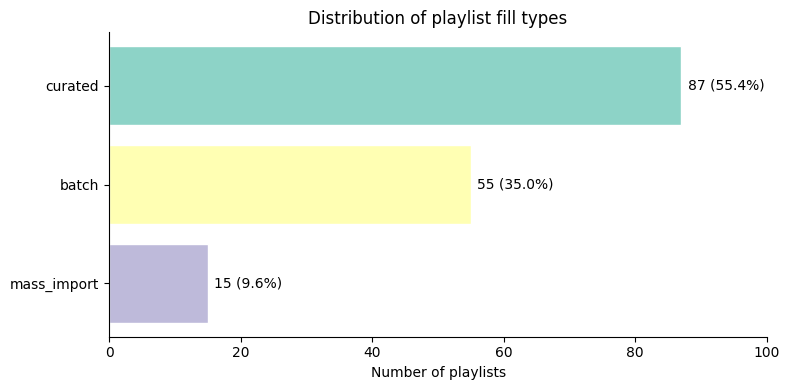


📋 Mass-import playlists:


,Playlist,Tracks,Adding days,"Listened before, %"
№,,,,
1,#spring,106,1,0.0
2,03._trip_pas_pop,123,1,0.0
3,18_nice,144,1,0.0
4,"acid_jazz,_downtempo,_nu_jazz_trip",413,1,0.0
5,armin_van_buuren_presents,100,1,0.0
6,personal_emotional_09,186,1,0.0
7,personal_intimate_03,103,1,0.0
8,personal_personal_15,123,1,0.0
9,personal_spiritual_08,220,1,0.0


In [95]:
# 6.1 Классификация типов наполнения плейлистов

# Разделяем личные (personal) и совместные (collaborative) плейлисты
# по способу формирования:
#
#   mass_import — один день, ≥100 треков, длительность ≤15 минут,
#                 прослушано до добавления <30%. Слепой перенос.
#   batch       — только быстрые серии добавлений (интервал ≤2 мин),
#                 без одиночных треков. Пакетное копирование.
#   curated     — есть хотя бы одно одиночное добавление или разрыв >2 мин.
#                 Осознанный отбор.
#
# Пороги взяты из этапа 7 и закреплены для воспроизводимости.
#
# foreign и contributed в анализ не входят: наполнение в них
# не полностью контролируется пользователем.

from IPython.display import HTML
# mass_import здесь определяется на уровне плейлиста:
# один день добавления, ≥100 треков, длительность дня ≤15 минут,
# <30% прослушано до добавления.
#
# В 03_eda_behavioral mass_import определяется иначе — на уровне дня
# в потоке сохранений: ≥100 сохранений за день, ≥30% от месяца,
# <30% прослушано. Объект и метрика разные.
# См. 03_eda_behavioral, блок 1.4a.
# Параметры
MASS_IMPORT_MIN_SIZE = 100          # минимум треков за один день
MASS_IMPORT_MAX_LISTENED = 0.30     # максимум доли прослушанных до добавления
MASS_IMPORT_MAX_DURATION_MIN = 15   # максимум длительности дня добавления
PACKET_INTERVAL_MIN = 2             # максимальный интервал внутри пакета

# --- Пересоздаём own_links с датами ---
own_links = playlist_links[
    playlist_links['playlist_type'].isin(['personal', 'collaborative'])
].copy()
own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)

# Первое валидное прослушивание каждого трека
valid_events = df_events[df_events['valid_play']].copy()
valid_events['ts'] = pd.to_datetime(valid_events['ts'], errors='coerce').dt.tz_localize(None)
first_valid_seen = valid_events.groupby('spotify_track_uri')['ts'].min()

own_links['first_valid_seen'] = own_links['Track URI'].map(first_valid_seen)
own_links['listened_before'] = own_links['first_valid_seen'] < own_links['Added At']


def classify_playlist(group):
    """Определяет тип наполнения плейлиста по датам добавления."""
    total = len(group)
    if total == 0:
        return 'empty'

    group = group.sort_values('Added At').reset_index(drop=True)

    # --- mass_import ---
    n_days = group['Added At'].dt.date.nunique()
    if n_days == 1:
        day_duration = (group['Added At'].max() - group['Added At'].min()).total_seconds() / 60
        known_mask = group['listened_before'].notna()
        listened_before_share = (
            group.loc[known_mask, 'listened_before'].mean() if known_mask.sum() > 0 else 0.0
        )
        if (total >= MASS_IMPORT_MIN_SIZE and
                listened_before_share < MASS_IMPORT_MAX_LISTENED and
                day_duration <= MASS_IMPORT_MAX_DURATION_MIN):
            return 'mass_import'

    # --- batch ---
    # Все серии добавлений должны содержать минимум 2 трека.
    series_lengths = []
    current_len = 1
    for i in range(1, total):
        interval = (group.loc[i, 'Added At'] - group.loc[i-1, 'Added At']).total_seconds() / 60
        if interval <= PACKET_INTERVAL_MIN:
            current_len += 1
        else:
            series_lengths.append(current_len)
            current_len = 1
    series_lengths.append(current_len)

    has_single = any(length == 1 for length in series_lengths)
    if not has_single:
        return 'batch'

    # --- curated ---
    return 'curated'


# --- Классификация всех плейлистов ---
fill_rows = []
for name_norm, group in own_links.groupby('name_norm'):
    fill_type = classify_playlist(group)
    total_tracks = len(group)
    n_days = group['Added At'].dt.date.nunique()
    listened_before_share = group['listened_before'].mean()
    day_durations = group.groupby(group['Added At'].dt.date)['Added At'].agg(
        lambda x: (x.max() - x.min()).total_seconds() / 60
    )
    median_day_duration = day_durations.median()

    fill_rows.append({
        'name_norm': name_norm,
        'fill_type': fill_type,
        'total_tracks': total_tracks,
        'n_days': n_days,
        'listened_before_share': listened_before_share,
        'median_day_duration_min': median_day_duration
    })

fill_df = pd.DataFrame(fill_rows)

# --- Сводка по типам ---
type_order_fill = ['mass_import', 'batch', 'curated']
type_counts = fill_df['fill_type'].value_counts().reindex(type_order_fill).fillna(0).astype(int)
type_pct = (type_counts / len(fill_df) * 100).round(1)

type_metrics = fill_df.groupby('fill_type').agg(
    Mean_size=('total_tracks', 'mean'),
    Median_size=('total_tracks', 'median'),
    Mean_listened_share=('listened_before_share', 'mean'),
    Median_listened_share=('listened_before_share', 'median'),
    Mean_days=('n_days', 'mean'),
    Median_days=('n_days', 'median'),
    Median_day_duration=('median_day_duration_min', 'median')
).reindex(type_order_fill).round(2)

summary = pd.DataFrame({
    'Type': type_counts.index,
    'Count': type_counts.values,
    'Share (%)': type_pct.values,
    'Mean size': type_metrics['Mean_size'].values,
    'Median size': type_metrics['Median_size'].values,
    'Mean listened before, %': (type_metrics['Mean_listened_share'] * 100).round(1).values,
    'Mean days': type_metrics['Mean_days'].values,
    'Median day duration, min': type_metrics['Median_day_duration'].values,
})
summary.index = range(1, len(summary) + 1)
summary.index.name = '№'

print('📊 Fill type summary (personal & collaborative):')
display(summary)

# --- Barh распределения ---
fill_colors = {
    'mass_import': '#bebada',
    'batch': '#ffffb3',
    'curated': '#8dd3c7',
}

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(
    type_order_fill,
    type_counts.values,
    color=[fill_colors[t] for t in type_order_fill],
    edgecolor='white'
)
ax.set_xlabel('Number of playlists')
ax.set_title('Distribution of playlist fill types')
ax.set_xlim(0, max(type_counts.values) * 1.15)

for bar, count, pct in zip(bars, type_counts.values, type_pct.values):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            f'{count} ({pct}%)', va='center', ha='left', fontsize=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# --- Список mass_import ---
print('\n📋 Mass-import playlists:')
mass_import_df = fill_df[fill_df['fill_type'] == 'mass_import'][[
    'name_norm', 'total_tracks', 'n_days', 'listened_before_share'
]].copy()
mass_import_df['listened_before_share'] = (mass_import_df['listened_before_share'] * 100).round(1)
mass_import_df.columns = ['Playlist', 'Tracks', 'Adding days', 'Listened before, %']
mass_import_df.index = range(1, len(mass_import_df) + 1)
mass_import_df.index.name = '№'

formatted = mass_import_df.style.set_properties(**{'text-align': 'center'}).format({
    'Tracks': '{:.0f}',
    'Adding days': '{:.0f}',
    'Listened before, %': '{:.1f}'
})

if len(mass_import_df) > 10:
    html = formatted.to_html()
    html = html.replace('<table', '<table style="max-height:250px; overflow-y:auto; display:block;"', 1)
    display(HTML(html))
else:
    display(formatted)

### 6.1. Вывод

**Что смотрели.** Классификацию 157 **personal** и **collaborative** плейлистов по способу наполнения.

**Результат.** **Curated** — 87 плейлистов (55.4%), **batch** — 55 (35.0%), **mass_import** — 15 (9.6%). **Mass_import** — самые крупные плейлисты (224.5 трека в среднем), **batch** — самые мелкие (49.8). **Curated** растянут во времени: 18.2 дня против одного дня у остальных.

**Вывод.** Больше половины плейлистов наполнялись постепенно. Три типа — не оттенки одного поведения, а разные стратегии: массовый перенос, пакетное копирование, осознанный отбор.

**Ограничения.** Пороги классификации (100 треков, 15 минут, 30% прослушивания до добавления) — эвристика, не выведенная из данных. **Mass_import** — 15 плейлистов, статистика по нему неустойчива.

## 6.2 Распределение типов наполнения по годам создания


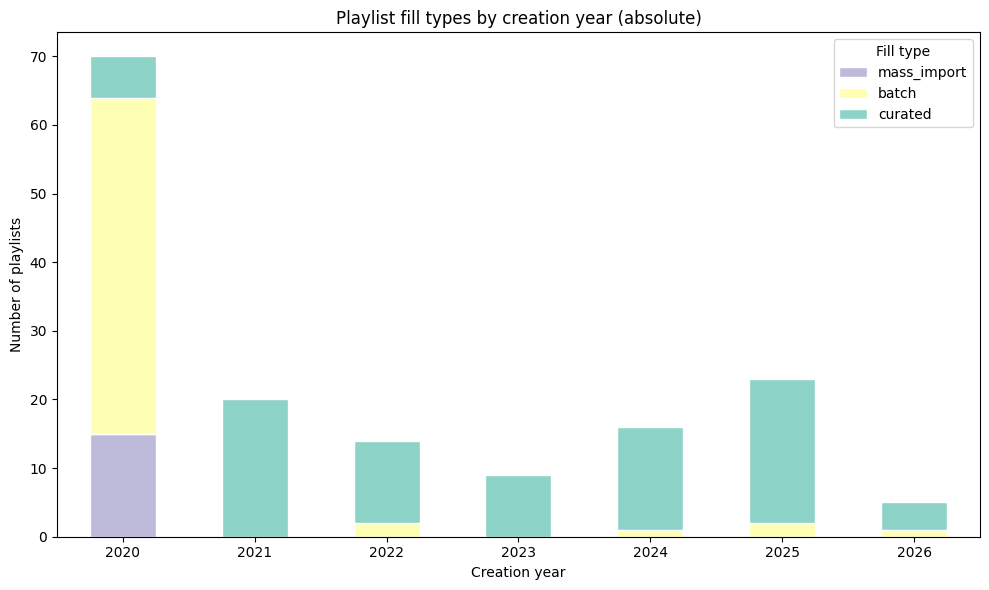

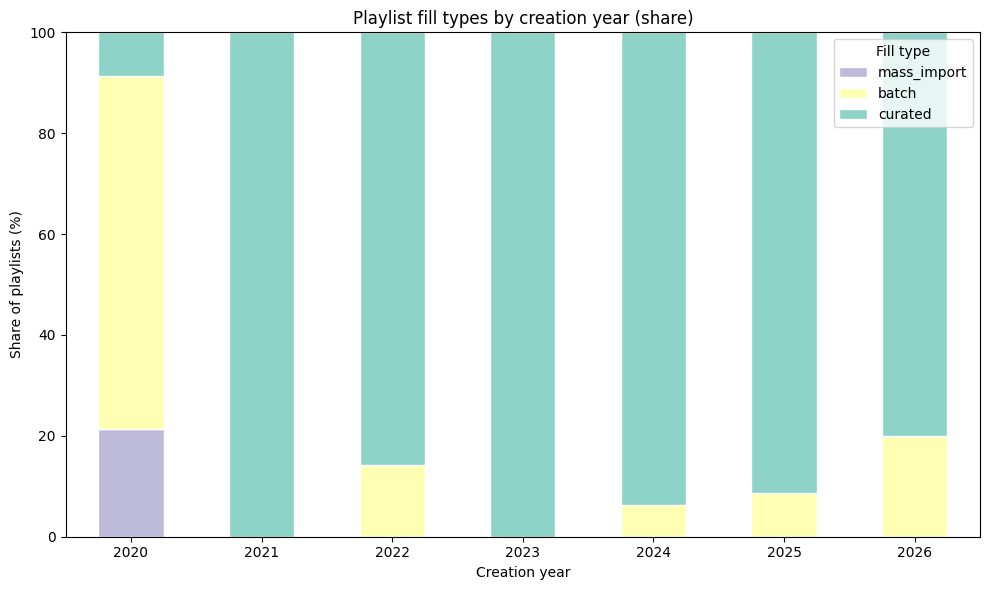

📊 Fill types by creation year (absolute):


fill_type,mass_import,batch,curated
creation_year,,,
2020,15,49,6
2021,0,0,20
2022,0,2,12
2023,0,0,9
2024,0,1,15
2025,0,2,21
2026,0,1,4



📊 Fill type share within year (%):


fill_type,mass_import,batch,curated
creation_year,,,
2020,21.4,70.0,8.6
2021,0.0,0.0,100.0
2022,0.0,14.3,85.7
2023,0.0,0.0,100.0
2024,0.0,6.2,93.8
2025,0.0,8.7,91.3
2026,0.0,20.0,80.0



🔍 Interpretation:
• In 2020: dominant type is "batch" (70.0%).
• In 2026: dominant type is "curated" (80.0%).
• Shift detected: dominant fill type changed from "batch" to "curated".
• "mass_import" peaks in 2020: 15 playlists (21.4%).
• "batch" peaks in 2020: 49 playlists (70.0%).
• "curated" peaks in 2025: 21 playlists (91.3%).
• Full transition from mass import to conscious curation.


In [96]:
# 6.2 Распределение типов наполнения по годам создания

# Анализ только personal и collaborative плейлистов.

# Убеждаемся, что own_links и fill_df есть
if 'own_links' not in globals():
    own_links = playlist_links[
        playlist_links['playlist_type'].isin(['personal', 'collaborative'])
    ].copy()
    own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)

# Удаляем старую колонку, если есть
if 'creation_year' in fill_df.columns:
    fill_df.drop(columns=['creation_year'], inplace=True)

# Год создания = минимальная дата добавления
min_dates = own_links.groupby('name_norm')['Added At'].min().reset_index()
min_dates.columns = ['name_norm', 'creation_date']
min_dates['creation_year'] = min_dates['creation_date'].dt.year

fill_df = fill_df.merge(min_dates[['name_norm', 'creation_year']], on='name_norm', how='left')

# --- Кросс-таблица: тип наполнения × год ---
cross = pd.crosstab(
    fill_df['creation_year'],
    fill_df['fill_type']
).reindex(sorted(fill_df['creation_year'].dropna().astype(int).unique()))

type_order_fill = ['mass_import', 'batch', 'curated']
cross = cross.reindex(columns=type_order_fill, fill_value=0)

# Доли внутри года
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

# Палитра
fill_colors = {
    'mass_import': '#bebada',
    'batch': '#ffffb3',
    'curated': '#8dd3c7',
}

# --- График 1: абсолютные значения ---
ax = cross.plot(
    kind='bar', stacked=True, figsize=(10, 6),
    color=[fill_colors[col] for col in cross.columns],
    edgecolor='white'
)
ax.set_title('Playlist fill types by creation year (absolute)')
ax.set_xlabel('Creation year')
ax.set_ylabel('Number of playlists')
ax.legend(title='Fill type')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

# --- График 2: доли внутри года ---
ax = cross_pct.plot(
    kind='bar', stacked=True, figsize=(10, 6),
    color=[fill_colors[col] for col in cross_pct.columns],
    edgecolor='white'
)
ax.set_title('Playlist fill types by creation year (share)')
ax.set_xlabel('Creation year')
ax.set_ylabel('Share of playlists (%)')
ax.legend(title='Fill type')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

# --- Таблицы ---
print('📊 Fill types by creation year (absolute):')
display(cross)

print('\n📊 Fill type share within year (%):')
display(cross_pct.round(1))


# --- Автоматическая интерпретация ---
print('\n🔍 Interpretation:')
if len(cross) == 0:
    print('No data.')
else:
    years = sorted(cross.index)
    first_year = years[0]
    last_year = years[-1]

    first_dom = cross_pct.loc[first_year].idxmax()
    first_dom_share = cross_pct.loc[first_year].max()
    last_dom = cross_pct.loc[last_year].idxmax()
    last_dom_share = cross_pct.loc[last_year].max()

    print(f'• In {first_year}: dominant type is "{first_dom}" ({first_dom_share:.1f}%).')
    print(f'• In {last_year}: dominant type is "{last_dom}" ({last_dom_share:.1f}%).')

    if first_dom != last_dom:
        print(f'• Shift detected: dominant fill type changed from "{first_dom}" to "{last_dom}".')
    else:
        print(f'• Dominant fill type unchanged: "{first_dom}".')

    for t in cross.columns:
        if cross[t].sum() > 0:
            max_year = cross[t].idxmax()
            max_val = cross[t].max()
            max_share = cross_pct.loc[max_year, t]
            print(f'• "{t}" peaks in {max_year}: {max_val} playlists ({max_share:.1f}%).')

    if 'mass_import' in cross.columns and 'curated' in cross.columns:
        mass_first = cross_pct.loc[first_year, 'mass_import'] if 'mass_import' in cross_pct.columns else 0
        mass_last = cross_pct.loc[last_year, 'mass_import'] if 'mass_import' in cross_pct.columns else 0
        curated_first = cross_pct.loc[first_year, 'curated'] if 'curated' in cross_pct.columns else 0
        curated_last = cross_pct.loc[last_year, 'curated'] if 'curated' in cross_pct.columns else 0

        if mass_last == 0 and curated_last > curated_first:
            print('• Full transition from mass import to conscious curation.')
        elif mass_first > 0 and mass_last == 0 and curated_last > curated_first:
            print('• Mass import disappeared; curated grew. Main shift: from batch to curated.')
        else:
            print('• No clear transition trend detected.')

### 6.2. Вывод

**Что смотрели.** Распределение типов наполнения по годам создания.

**Результат.** 2020 — первый год в данных: год создания первого аккаунта. Это единственный год, где доминируют **mass_import** и **batch**: 64 плейлиста из 70. **Mass_import** появляется только в 2020 (15 плейлистов) и после этого не встречается ни разу. С 2021 доля **curated** держится на 85–100% каждый год. **Batch** не исчезает полностью: 1–2 плейлиста в год.

**Вывод.** Массовый перенос библиотеки — стартовая стратегия первого года. Он больше не повторяется. Переход к осознанному отбору произошёл один раз, в 2020–2021, и не откатывался.

**Ограничения.** 2026 — неполный год, 5 плейлистов. Доли по нему не сравнимы с полными годами.

## 6.3.1 Типы наполнения и активность


In [97]:
# 6.3.1 Типы наполнения и активность

# Квадрантный scatter:
#   ось X — days_since_update (давность обновления)
#   ось Y — total_listens (суммарные валидные прослушивания)
#   цвет — тип наполнения (mass_import / batch / curated)
#   размер — число треков
#
# Границы: 30 и 365 дней — активное / умеренное / заброшенное.
# Горизонтальная линия — медиана прослушиваний.

if 'pl_activity' not in globals():
    print('⚠️ pl_activity not found. Run block 5 first.')
    raise SystemExit(0)

fill_activity = fill_df.merge(
    pl_activity[['name_norm', 'total_listens', 'days_since_update', 'num_tracks', 'group', 'activity']],
    on='name_norm',
    how='left'
).dropna(subset=['days_since_update']).copy()

if len(fill_activity) == 0:
    print('⚠️ No data for visualization.')
    raise SystemExit(0)

print(f'Playlists with activity data: {len(fill_activity)}\n')

# Палитра для типов наполнения (единая с 6.1)
fill_colors_plotly = {
    'mass_import': '#bebada',
    'batch': '#ffffb3',
    'curated': '#8dd3c7',
}

median_listens = fill_activity['total_listens'].median()
max_listens = fill_activity['total_listens'].max()

# --- Scatter ---
fig = px.scatter(
    fill_activity,
    x='days_since_update',
    y='total_listens',
    color='fill_type',
    size='num_tracks',
    hover_name='name_norm',
    color_discrete_map=fill_colors_plotly,
    labels={
        'days_since_update': 'Days since last update',
        'total_listens': 'Total listens',
        'fill_type': 'Fill type',
        'num_tracks': 'Number of tracks',
        'name_norm': 'Playlist',
    },
    title='Fill type vs activity (personal & collaborative)',
    opacity=0.9
)

fig.update_traces(marker=dict(line=dict(color='black', width=0.5)))

# Границы активности
fig.add_vline(x=30, line_dash='dash', line_color=COLORS['line_success'],
              annotation_text='30 days')
fig.add_vline(x=365, line_dash='dash', line_color=COLORS['line_accent'],
              annotation_text='365 days')

# Медиана прослушиваний
fig.add_shape(
    type='line',
    x0=0, x1=1, xref='paper',
    y0=median_listens, y1=median_listens,
    yref='y',
    line=dict(color=COLORS['line_primary'], dash='dash', width=1.5)
)
fig.add_annotation(
    x=0.99, xref='paper',
    y=median_listens, yref='y',
    text=f'Median listens: {median_listens:.0f}',
    showarrow=False,
    xanchor='right',
    yanchor='bottom',
    font=dict(color=COLORS['line_primary'], size=10)
)

fig.update_yaxes(type='log', range=[0, np.log10(max_listens * 1.5)])
fig.update_layout(
    hovermode='closest',
    height=650,
    legend_title='Fill type',
    paper_bgcolor='white',
    plot_bgcolor='white',
    xaxis=dict(showgrid=True, gridcolor='lightgray', zeroline=False),
    yaxis=dict(showgrid=True, gridcolor='lightgray', zeroline=False)
)

fig.show()

# --- Таблица данных с прокруткой ---
scroll_data = fill_activity[
    ['name_norm', 'fill_type', 'group', 'days_since_update', 'total_listens']
].copy()
scroll_data.columns = ['Playlist', 'Fill type', 'Activity group', 'Days since update', 'Total listens']
scroll_data = scroll_data.sort_values('Total listens', ascending=False)
scroll_data.index = range(1, len(scroll_data) + 1)
scroll_data.index.name = '№'

html_table = scroll_data.to_html()
display(HTML(f'<div style="max-height:220px; overflow-y:auto;">{html_table}</div>'))

# --- Интерпретация ---
print('\n🔍 Interpretation:')
print(f'📏 Median listens (horizontal line): {median_listens:.0f}')

group_order_5 = ['active_listened', 'active_not_listened', 'abandoned_but_listened', 'abandoned_not_listened']
group_descriptions = {
    'active_listened': 'active and frequently listened',
    'active_not_listened': 'active but rare',
    'abandoned_but_listened': 'abandoned but still listened',
    'abandoned_not_listened': 'abandoned and not listened',
}

cross_type_group = pd.crosstab(fill_activity['fill_type'], fill_activity['group'])
cross_type_group = cross_type_group.reindex(
    index=[t for t in fill_colors_plotly if t in cross_type_group.index],
    columns=group_order_5,
    fill_value=0
)
type_group_pct = cross_type_group.div(cross_type_group.sum(axis=1), axis=0) * 100

for t in type_group_pct.index:
    pct = type_group_pct.loc[t]
    dominant_group = pct.idxmax()
    dominant_share = pct.max()
    print(f'• {t}: dominant group «{group_descriptions[dominant_group]}» ({dominant_share:.0f}%).')

active_types = [t for t in type_group_pct.index if type_group_pct.loc[t, 'active_listened'] > 20]
abandoned_types = [t for t in type_group_pct.index if type_group_pct.loc[t, 'abandoned_not_listened'] > 60]

if active_types and abandoned_types:
    print(f'\n✅ Pattern: {", ".join(active_types)} are more often "active and frequently listened", '
          f'while {", ".join(abandoned_types)} are more often "abandoned and not listened".')
elif active_types:
    print(f'\n✅ Most often "active and frequently listened": {", ".join(active_types)}.')
elif abandoned_types:
    print(f'\n⚠️ Most often "abandoned and not listened": {", ".join(abandoned_types)}.')
else:
    print('\nNo clear link between fill type and activity.')
    

Playlists with activity data: 157



,Playlist,Fill type,Activity group,Days since update,Total listens
№,,,,,
1,2025,curated,active_listened,172,6611
2,ringleader,curated,active_listened,0,3469
3,🌊🌊🌊waves,curated,active_listened,57,3206
4,personal_personal_01,curated,abandoned_but_listened,971,2225
5,personal_identity_03,curated,active_listened,0,1934
6,soulful_mood,curated,active_listened,65,1867
7,2024,curated,active_listened,329,1822
8,personal_personal_17,curated,abandoned_but_listened,490,1698
9,2026,curated,active_listened,0,1633



🔍 Interpretation:
📏 Median listens (horizontal line): 61
• mass_import: dominant group «abandoned and not listened» (80%).
• batch: dominant group «abandoned and not listened» (84%).
• curated: dominant group «active and frequently listened» (44%).

✅ Pattern: curated are more often "active and frequently listened", while mass_import, batch are more often "abandoned and not listened".


### 6.3.1. Вывод

**Что смотрели.** Связь способа наполнения с попаданием плейлиста в группу активности.

**Результат.** **Mass_import** — 15 плейлистов, все заброшены, 12 из них не слушаются. **Batch** — 55 плейлистов, 84% в **abandoned_not_listened**. **Curated** — 87 плейлистов, 44% в **active_listened**. То есть **curated** даёт в 13 раз больше активных плейлистов, чем **batch** и **mass_import** вместе.

**Вывод.** Способ наполнения связан с тем, попадёт ли плейлист в активную группу. **Mass_import** и **batch** сосредоточены в заброшенных. **Curated** — единственный способ, при котором плейлист попадает в активную и слушаемую группу заметно чаще остальных. Но и внутри **curated** активных меньше половины.

**Ограничения.** **Mass_import** — 15 плейлистов, статистика неустойчива. Медиана прослушиваний (61), пороги 30 и 365 дней — эвристики. Группа **active_listened** включает и **personal**, и **collaborative**, а **batch** и **mass_import** — почти целиком **personal**. Различия между способами наполнения частично совпадают с различиями между типами плейлистов.

## 6.3.2 Длительность пополнения и прослушиваемость


📊 Fill duration and listening:


Playlists  Median_size  Median_listens  Mean_listens
Fill type   Adding span                                                      
mass_import 0 years           15.0        139.0            33.0          48.7
            1 year             NaN          NaN             NaN           NaN
            2+ years           NaN          NaN             NaN           NaN
batch       0 years           54.0         48.0             6.5          68.4
            1 year             NaN          NaN             NaN           NaN
            2+ years           1.0        130.0            89.0          89.0
curated     0 years           39.0         19.0           118.0         320.9
            1 year            31.0         63.0           219.0         613.7
            2+ years          17.0         87.0           500.0         945.5

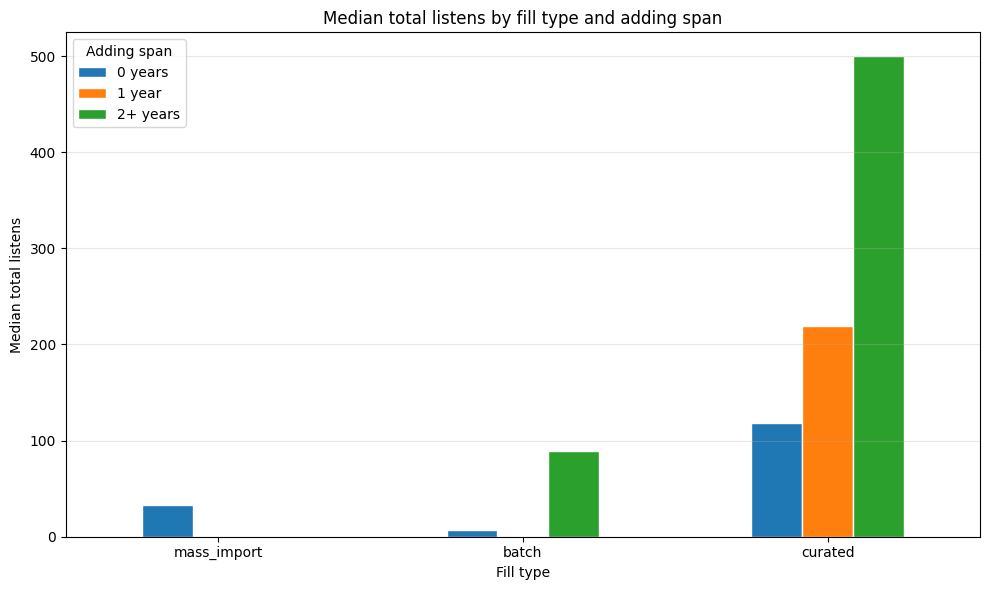


🔍 Interpretation:
• mass_import:
    0 years: median listens = 33, playlists = 15
    1 year: no playlists
    2+ years: no playlists

• batch:
    0 years: median listens = 6, playlists = 54
    1 year: no playlists
    2+ years: median listens = 89, playlists = 1

• curated:
    0 years: median listens = 118, playlists = 39
    1 year: median listens = 219, playlists = 31
    2+ years: median listens = 500, playlists = 17
    ➜ Listening grows with duration: 118 (0 years) → 500 (2+ years).

✅ Pattern: for curated, longer-running playlists get more listening.


In [98]:
# 6.3.2 Длительность пополнения и прослушиваемость

# Добавляем span_years — сколько лет плейлист пополнялся.
# Группируем по типу наполнения и категории длительности.
# Смотрим, растёт ли прослушиваемость с длительностью ведения.

if 'pl_activity' not in globals():
    print('⚠️ pl_activity not found. Run block 5 first.')
    raise SystemExit(0)

if 'own_links' not in globals():
    own_links = playlist_links[
        playlist_links['playlist_type'].isin(['personal', 'collaborative'])
    ].copy()
    own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)

# Удаляем старые колонки, если есть
for col in ['first_year', 'last_year', 'span_years', 'span_category']:
    if col in fill_df.columns:
        fill_df.drop(columns=[col], inplace=True)

# Года первого и последнего добавления
add_years = own_links.groupby('name_norm')['Added At'].agg(
    first_year=lambda x: x.min().year,
    last_year=lambda x: x.max().year
).reset_index()

fill_df = fill_df.merge(add_years, on='name_norm', how='left')
fill_df['span_years'] = (fill_df['last_year'] - fill_df['first_year']).fillna(0).astype(int)


def span_category(y):
    if y <= 0:
        return '0 years'
    elif y == 1:
        return '1 year'
    else:
        return '2+ years'


fill_df['span_category'] = fill_df['span_years'].apply(span_category)

# Присоединяем прослушивания
fill_activity = fill_df.merge(
    pl_activity[['name_norm', 'total_listens']],
    on='name_norm',
    how='left'
)

# Сводка
summary = fill_activity.groupby(['fill_type', 'span_category']).agg(
    Playlists=('name_norm', 'size'),
    Median_size=('total_tracks', 'median'),
    Median_listens=('total_listens', 'median'),
    Mean_listens=('total_listens', 'mean')
).reindex(
    pd.MultiIndex.from_product(
        [['mass_import', 'batch', 'curated'], ['0 years', '1 year', '2+ years']],
        names=['fill_type', 'span_category']
    )
).round(1)

summary.index.names = ['Fill type', 'Adding span']

print('📊 Fill duration and listening:')
display(summary)

# Pivot для графика
pivot_median = summary['Median_listens'].unstack()
pivot_median = pivot_median.reindex(
    index=['mass_import', 'batch', 'curated'],
    columns=['0 years', '1 year', '2+ years']
)

fig, ax = plt.subplots(figsize=(10, 6))
pivot_median.plot(kind='bar', ax=ax, edgecolor='white')
ax.set_title('Median total listens by fill type and adding span')
ax.set_xlabel('Fill type')
ax.set_ylabel('Median total listens')
ax.legend(title='Adding span')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# --- Автоматическая интерпретация ---
print('\n🔍 Interpretation:')

available_types = summary.index.get_level_values(0).unique().tolist()

for t in ['mass_import', 'batch', 'curated']:
    if t not in available_types:
        print(f'• {t}: no data.')
        continue
    print(f'• {t}:')
    for cat in ['0 years', '1 year', '2+ years']:
        if (t, cat) in summary.index:
            row = summary.loc[(t, cat)]
            if pd.notna(row['Playlists']):
                print(f'    {cat}: median listens = {row["Median_listens"]:.0f}, playlists = {int(row["Playlists"])}')
            else:
                print(f'    {cat}: no playlists')
        else:
            print(f'    {cat}: no playlists')

    if t == 'curated':
        if ('curated', '0 years') in summary.index and ('curated', '2+ years') in summary.index:
            med_0 = summary.loc[('curated', '0 years'), 'Median_listens']
            med_2plus = summary.loc[('curated', '2+ years'), 'Median_listens']
            if pd.notna(med_0) and pd.notna(med_2plus):
                if med_2plus > med_0:
                    print(f'    ➜ Listening grows with duration: {med_0:.0f} (0 years) → {med_2plus:.0f} (2+ years).')
                else:
                    print('    ➜ No clear growth with duration.')
    print()

if 'curated' in available_types and ('curated', '2+ years') in summary.index:
    med_0 = summary.loc[('curated', '0 years'), 'Median_listens']
    med_2plus = summary.loc[('curated', '2+ years'), 'Median_listens']
    if pd.notna(med_0) and pd.notna(med_2plus):
        if med_2plus > med_0:
            print('✅ Pattern: for curated, longer-running playlists get more listening.')
        else:
            print('No clear link between duration and listening for curated.')
    else:
        print('Not enough data to compare curated 0 years vs 2+ years.')
else:
    print('Not enough data for 2+ years curated playlists.')

## 6.3.3 Широта и глубина прослушивания


In [99]:
# 6.3.3 Широта и глубина прослушивания

# Широта (breadth) — доля уникальных треков плейлиста,
# прослушанных хотя бы раз валидно.
# Глубина (depth) — среднее число валидных прослушиваний на прослушанный трек.
#
# Позволяет отличить плейлист, где крутят 1–2 любимых трека,
# от того, что слушают целиком и многократно.

if 'own_links' not in globals():
    own_links = playlist_links[
        playlist_links['playlist_type'].isin(['personal', 'collaborative'])
    ].copy()

if 'df_events' not in globals():
    raise SystemExit('df_events not found. Run block 0 first.')

# Валидные прослушивания по трекам
valid_counts = (
    df_events[df_events['valid_play']]
    .groupby('spotify_track_uri')
    .size()
    .reset_index(name='play_count')
)

# Уникальные треки в плейлистах
pl_tracks = own_links[['name_norm', 'Track URI']].drop_duplicates()
pl_tracks = pl_tracks.merge(
    valid_counts,
    left_on='Track URI', right_on='spotify_track_uri', how='left'
)
pl_tracks['play_count'] = pl_tracks['play_count'].fillna(0).astype(int)

# Агрегация по плейлистам
breadth_depth = pl_tracks.groupby('name_norm').agg(
    total_tracks=('Track URI', 'nunique'),
    listened_tracks=('play_count', lambda x: (x > 0).sum()),
    total_listens=('play_count', 'sum')
).reset_index()

breadth_depth['breadth'] = breadth_depth['listened_tracks'] / breadth_depth['total_tracks'] * 100
breadth_depth['depth'] = breadth_depth.apply(
    lambda row: (row['total_listens'] / row['listened_tracks']) if row['listened_tracks'] > 0 else 0,
    axis=1
)

# Присоединяем тип наполнения
breadth_depth = breadth_depth.merge(
    fill_df[['name_norm', 'fill_type']],
    on='name_norm', how='left'
)

if len(breadth_depth) == 0:
    print('⚠️ No data for visualization.')
    raise SystemExit(0)

# Палитра типов наполнения
fill_colors_plotly = {
    'mass_import': '#bebada',
    'batch': '#ffffb3',
    'curated': '#8dd3c7',
}

# --- Scatter: широта vs глубина ---
fig = px.scatter(
    breadth_depth,
    x='breadth',
    y='depth',
    color='fill_type',
    size='total_tracks',
    hover_name='name_norm',
    color_discrete_map=fill_colors_plotly,
    labels={
        'breadth': 'Breadth: share of unique tracks listened at least once (%)',
        'depth': 'Depth: avg valid plays per listened track',
        'fill_type': 'Fill type',
        'total_tracks': 'Number of tracks',
        'name_norm': 'Playlist',
    },
    title='Listening breadth vs depth by fill type'
)

fig.update_traces(marker=dict(line=dict(color='black', width=1), opacity=0.85))
fig.update_layout(
    paper_bgcolor='white',
    plot_bgcolor='white',
    height=650,
    legend_title='Fill type',
    xaxis=dict(showgrid=True, gridcolor='lightgray', zeroline=False),
    yaxis=dict(showgrid=True, gridcolor='lightgray', zeroline=False)
)
fig.show()

# --- Таблица данных с прокруткой ---
scroll_bd = breadth_depth[
    ['name_norm', 'fill_type', 'total_tracks', 'breadth', 'depth', 'total_listens']
].copy()
scroll_bd.columns = ['Playlist', 'Fill type', 'Tracks', 'Breadth (%)', 'Depth (plays/track)', 'Total listens']
scroll_bd = scroll_bd.sort_values('Total listens', ascending=False)
scroll_bd.index = range(1, len(scroll_bd) + 1)
scroll_bd.index.name = '№'

html_bd = scroll_bd.to_html()
display(HTML(f'<div style="max-height:220px; overflow-y:auto;">{html_bd}</div>'))

# --- Интерпретация ---
print('\n🔍 Interpretation:')

median_stats = breadth_depth.groupby('fill_type').agg(
    med_breadth=('breadth', 'median'),
    med_depth=('depth', 'median'),
    count=('name_norm', 'size')
).reindex(['mass_import', 'batch', 'curated']).dropna(how='all')

if len(median_stats) == 0:
    print('No data for interpretation.')
else:
    for ftype in median_stats.index:
        row = median_stats.loc[ftype]
        if pd.notna(row['med_breadth']):
            print(f'• {ftype}: median breadth {row["med_breadth"]:.1f}%, '
                  f'median depth {row["med_depth"]:.2f} plays/track ({int(row["count"])} playlists).')
        else:
            print(f'• {ftype}: no data.')

    if 'curated' in median_stats.index and 'mass_import' in median_stats.index:
        curated_b = median_stats.loc['curated', 'med_breadth']
        mass_b = median_stats.loc['mass_import', 'med_breadth']
        curated_d = median_stats.loc['curated', 'med_depth']
        mass_d = median_stats.loc['mass_import', 'med_depth']

        if curated_b > mass_b and curated_d > mass_d:
            print('\n✅ Curated playlists significantly outperform mass_import '
                  'on both breadth and depth.')
            print('   This confirms that conscious curation leads to full and repeated use.')
        elif curated_b > mass_b or curated_d > mass_d:
            print('\nℹ️ Curated playlists lead on at least one of the two metrics.')
        else:
            print('\nNo clear advantage of curated over mass_import.')
    elif 'curated' in median_stats.index:
        print('\nOnly curated playlists present; comparison with other types not possible.')

,Playlist,Fill type,Tracks,Breadth (%),Depth (plays/track),Total listens
№,,,,,,
1,2025,curated,576,97.743056,11.742451,6611
2,ringleader,curated,228,98.245614,15.486607,3469
3,🌊🌊🌊waves,curated,358,95.251397,9.401760,3206
4,personal_personal_01,curated,101,99.009901,22.250000,2225
5,personal_identity_03,curated,137,100.000000,14.116788,1934
6,soulful_mood,curated,184,84.782609,11.967949,1867
7,2024,curated,290,87.931034,7.145098,1822
8,personal_personal_17,curated,201,92.537313,9.129032,1698
9,2026,curated,276,97.463768,6.070632,1633



🔍 Interpretation:
• mass_import: median breadth 10.4%, median depth 2.24 plays/track (15 playlists).
• batch: median breadth 9.5%, median depth 2.00 plays/track (55 playlists).
• curated: median breadth 85.7%, median depth 6.03 plays/track (87 playlists).

✅ Curated playlists significantly outperform mass_import on both breadth and depth.
   This confirms that conscious curation leads to full and repeated use.


### 6.3.3. Вывод

**Что смотрели.** Широту и глубину прослушивания по типам наполнения. Широта — доля уникальных треков плейлиста, прослушанных хотя бы раз. Глубина — среднее число валидных прослушиваний на прослушанный трек.

**Результат.** **Curated** — медиана широты 85.7%, медиана глубины 6.03. **Mass_import** — 10.4% и 2.24. **Batch** — 9.5% и 2.00. По обеим метрикам **curated** отличается от остальных в разы.

**Вывод.** Широта и глубина различают типы наполнения сильнее, чем активность. **Mass_import** и **batch** не только заброшены — внутри них прослушивается примерно десятая часть треков, и каждый прослушанный трек играется в среднем дважды. Это не «плейлист, который слушают мало», а «плейлист, который почти не открывают». **Curated** — наоборот: почти каждый трек хотя бы раз прослушан и возвращается в среднем шесть раз.

**Ограничения.** **Mass_import** — 15 плейлистов. Медианы при таком объёме неустойчивы.

## 6.4 Сравнение типов наполнения по жанрам и аудио


ℹ️ Analyzing personal and collaborative playlists.
   Fill types: mass_import, batch, curated.



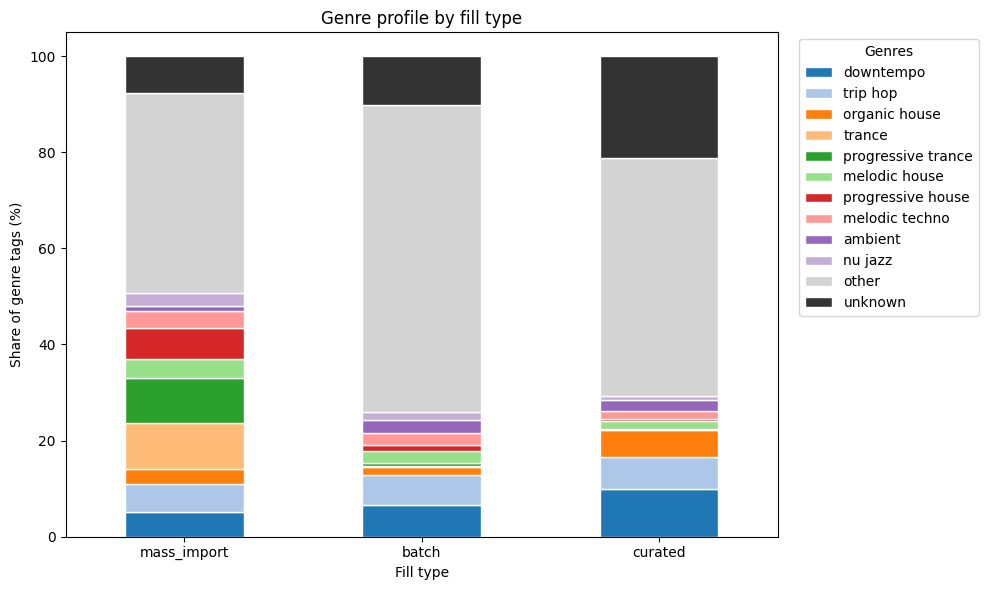

📊 Genre profile by fill type (% of all genre tags):


,downtempo,trip hop,organic house,trance,progressive trance,melodic house,progressive house,melodic techno,ambient,nu jazz,other,unknown
Fill type,,,,,,,,,,,,
mass_import,5.1,5.8,3.2,9.6,9.4,4.0,6.3,3.6,0.9,2.9,41.6,7.6
batch,6.6,6.1,1.7,0.3,0.5,2.6,1.2,2.5,2.7,1.6,63.9,10.2
curated,10.0,6.5,5.7,0.2,0.1,1.7,0.4,1.7,2.2,0.8,49.7,21.1



📊 Median audio features by fill type:


,valence,energy,danceability,acousticness,instrumentalness,popularity,tempo
Fill type,,,,,,,
mass_import,0.285,0.695,0.620,0.033,0.768,0.0,123.986
batch,0.252,0.546,0.598,0.184,0.647,4.0,120.010
curated,0.241,0.509,0.611,0.259,0.590,24.0,118.000



📊 Statistical significance (Kruskal-Wallis):
  valence: significant (p=7.104e-13)
    ⚠️ mass_import vs batch: significant, but below threshold (0.019 < 0.02)
    ✅ mass_import vs curated: mass_import higher by 0.048 (medians: 0.28 vs 0.24)
    ✅ batch vs curated: batch higher by 0.029 (medians: 0.25 vs 0.24)
  energy: significant (p=8.300e-167)
    ✅ mass_import vs batch: mass_import higher by 0.105 (medians: 0.69 vs 0.55)
    ✅ mass_import vs curated: mass_import higher by 0.139 (medians: 0.69 vs 0.51)
    ✅ batch vs curated: batch higher by 0.034 (medians: 0.55 vs 0.51)
  danceability: significant (p=1.977e-07)
    ✅ mass_import vs batch: mass_import higher by 0.030 (medians: 0.62 vs 0.60)
    ⚠️ mass_import vs curated: significant, but below threshold (0.015 < 0.02)
    ⚠️ batch vs curated: significant, but below threshold (0.015 < 0.02)
  acousticness: significant (p=1.129e-159)
    ✅ mass_import vs batch: mass_import lower by 0.109 (medians: 0.03 vs 0.18)
    ✅ mass_import vs cu

In [100]:
# 6.4 Сравнение типов наполнения по жанрам и аудио

# Сравниваем mass_import / batch / curated по:
#   1. Жанровому профилю (топ-10 + other + unknown).
#   2. Медианам аудио-характеристик.
#   3. Статистической значимости различий.

print('ℹ️ Analyzing personal and collaborative playlists.')
print('   Fill types: mass_import, batch, curated.\n')

# Множества URI по типам наполнения
mass_names = set(fill_df.loc[fill_df['fill_type'] == 'mass_import', 'name_norm'])
batch_names = set(fill_df.loc[fill_df['fill_type'] == 'batch', 'name_norm'])
curated_names = set(fill_df.loc[fill_df['fill_type'] == 'curated', 'name_norm'])


def get_tracks_for_names(names):
    uris = playlist_links[playlist_links['name_norm'].isin(names)]['Track URI'].unique()
    return tracks_exportify[tracks_exportify['spotify_track_uri'].isin(uris)]


mass_tracks = get_tracks_for_names(mass_names)
batch_tracks = get_tracks_for_names(batch_names)
curated_tracks = get_tracks_for_names(curated_names)

# --- Жанровый профиль ---
# Общий топ-10 по всем типам наполнения
all_tags = []
for tracks in [mass_tracks, batch_tracks, curated_tracks]:
    genres = tracks['genres_normalized'].dropna().str.split(',').explode().str.strip()
    genres = genres[genres != 'unknown']
    all_tags.extend(genres.tolist())
top10_genres = pd.Series(all_tags).value_counts().head(10).index.tolist()


def calculate_genre_share(tracks, top10):
    """Доли топ-10 + other + unknown от всех жанровых тегов."""
    genres = tracks['genres_normalized'].dropna().str.split(',').explode().str.strip()
    total = len(genres)
    other_count = 0
    unknown_count = 0
    top_counts = {g: 0 for g in top10}
    for g in genres:
        if g == 'unknown':
            unknown_count += 1
        elif g in top_counts:
            top_counts[g] += 1
        else:
            other_count += 1
    if total == 0:
        return [0] * (len(top10) + 2)
    shares = [top_counts[g] / total * 100 for g in top10]
    shares += [other_count / total * 100, unknown_count / total * 100]
    return shares


mass_shares = calculate_genre_share(mass_tracks, top10_genres)
batch_shares = calculate_genre_share(batch_tracks, top10_genres)
curated_shares = calculate_genre_share(curated_tracks, top10_genres)

genre_df = pd.DataFrame(
    [mass_shares, batch_shares, curated_shares],
    index=['mass_import', 'batch', 'curated'],
    columns=top10_genres + ['other', 'unknown']
)
genre_df.index.name = 'Fill type'

# Палитра для жанров — tab20, потому что жанров много
tab20 = plt.cm.tab20.colors
genre_colors = {g: tab20[i % len(tab20)] for i, g in enumerate(top10_genres)}
genre_colors['other'] = COLORS['muted']
genre_colors['unknown'] = '#333333'

ax = genre_df.plot(
    kind='bar', stacked=True, figsize=(10, 6),
    color=[genre_colors[g] for g in genre_df.columns],
    edgecolor='white'
)
ax.set_title('Genre profile by fill type')
ax.set_xlabel('Fill type')
ax.set_ylabel('Share of genre tags (%)')
ax.legend(title='Genres', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

print('📊 Genre profile by fill type (% of all genre tags):')
display(genre_df.round(1))


# --- Аудио-характеристики ---
features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'popularity', 'tempo']
type_tracks_dict = {
    'mass_import': mass_tracks,
    'batch': batch_tracks,
    'curated': curated_tracks,
}

# Медианы
med_rows = {}
for ftype, tracks in type_tracks_dict.items():
    med_rows[ftype] = [tracks[f].dropna().median() for f in features]

med_df = pd.DataFrame(med_rows, index=features).T
med_df.index.name = 'Fill type'

formatters = {}
for f in features:
    formatters[f] = '{:.1f}' if f in ['popularity', 'tempo'] else '{:.3f}'

print('\n📊 Median audio features by fill type:')
display(med_df.round(3))


# --- Статистическая проверка ---
from scipy.stats import kruskal
from itertools import combinations

print('\n📊 Statistical significance (Kruskal-Wallis):')
for feat in features:
    groups = [type_tracks_dict[ft][feat].dropna() for ft in type_tracks_dict]
    if any(len(g) < 30 for g in groups):
        print(f'  {feat}: insufficient data')
        continue
    h, p = kruskal(*groups)
    if p < 0.05:
        print(f'  {feat}: significant (p={p:.3e})')
        for ft1, ft2 in combinations(type_tracks_dict, 2):
            a = type_tracks_dict[ft1][feat].dropna()
            b = type_tracks_dict[ft2][feat].dropna()
            u, p_pair = stats.mannwhitneyu(a, b, alternative='two-sided')
            mean_diff = a.mean() - b.mean()
            thresh = PRACTICAL_THRESHOLDS.get(feat, 0.02)
            if p_pair < 0.05 and abs(mean_diff) >= thresh:
                direction = 'higher' if mean_diff > 0 else 'lower'
                print(f'    ✅ {ft1} vs {ft2}: {ft1} {direction} by {abs(mean_diff):.3f} '
                      f'(medians: {a.median():.2f} vs {b.median():.2f})')
            elif p_pair < 0.05 and abs(mean_diff) < thresh:
                print(f'    ⚠️ {ft1} vs {ft2}: significant, but below threshold '
                      f'({abs(mean_diff):.3f} < {thresh})')
    else:
        print(f'  {feat}: not significant (p={p:.3f})')


# --- Автоматический вывод ---
print('\n🔍 Auto conclusion:')
for feat in features:
    max_type = med_df[feat].idxmax()
    min_type = med_df[feat].idxmin()
    max_val = med_df[feat].max()
    min_val = med_df[feat].min()
    print(f'• {feat}: max in {max_type} ({max_val:.2f}), min in {min_type} ({min_val:.2f})')

### 6.4. Вывод

**Что смотрели.** Жанровый профиль и медианы аудио по типам наполнения.

**Результат.** Жанрово типы расходятся. **Mass_import** тянет trance (9.6%) и progressive trance (9.4%), у **batch** и **curated** их доли ниже 1%. **Curated** держит downtempo (10.0%) и organic house (5.7%). Общее у всех — trip hop: 5.8–6.5%.

Аудио-профили противоположны. **Mass_import**: energy 0.695, acousticness 0.033. **Curated**: energy 0.509, acousticness 0.259. По energy, acousticness, instrumentalness и popularity все три типа значимо различаются между собой.

**Вывод.** Способ наполнения связан не только с тем, как плейлист живёт, но и с тем, что в нём лежит. **Mass_import** — трансовое, инструментальное, громкое. **Curated** — даунтемпо, акустичное, тихое. По popularity **curated** выше остальных типов наполнения, но в абсолюте остаётся малоизвестной музыкой. **Batch** занимает промежуточное положение, не совпадая ни с **mass_import**, ни с **curated**.

**Ограничения.** **Mass_import** — 15 плейлистов. Медиана popularity 0.0 у **mass_import** означает, что больше половины треков имеют popularity ровно 0. Это не «непопулярная музыка», а отсутствие метаданных: ноль в Spotify — признак трека без индекса или без подтянутых данных. Сравнение popularity между типами наполнения некорректно, у **mass_import** данные отсутствуют, а не низкие.

**Unknown** в жанрах: 21.1% у **curated**, 10.2% у **batch**, 7.6% у **mass_import**. Жанровые выводы по **curated** ограничены сильнее остальных.

## 6.5. Характеристики curated-плейлистов

**Подгруппы curated** — по регулярности пополнения. Интервал — разница в днях между соседними днями добавления. **CV интервалов** — `CV = std(интервалы) / mean(интервалы)` по этим интервалам, безразмерная мера разброса: чем ниже, тем регулярнее пополнение. 
- **Few_sessions** — меньше 5 дней добавления, CV интервалов по ним не считается. 
- **Steady** — CV ≤ 0.5. 
- **Mixed** — 0.5 < CV ≤ 1.5. 
- **Bursty** — CV > 1.5. CV — коэффициент вариации интервалов между днями добавления; чем ниже, тем регулярнее.

ℹ️ Analyzing curated playlists only.
   Playlists with < 5 adding days are in few_sessions (CV not meaningful).

📊 Curated: addition metrics summary:


,N,Mean,Std,Min,Q1,Median,Q3,Max
add_days,87.0,18.22,24.84,1.00,3.50,8.00,24.50,131.00
lifespan_days,87.0,322.78,358.97,0.00,48.00,213.00,477.50,1703.00
avg_session_size,87.0,10.48,21.36,1.00,2.42,3.43,7.80,112.50
max_session_size,87.0,31.45,43.17,1.00,7.00,15.00,35.50,224.00
median_interval_days,87.0,42.96,156.17,0.00,2.25,7.00,12.00,1009.00
interval_cv,87.0,1.07,0.82,0.00,0.51,1.04,1.53,3.74
top_day_share,87.0,0.48,0.30,0.04,0.27,0.38,0.69,1.00



ℹ️ Playlists with < 5 adding days (few_sessions): 27 of 87
📊 Curated subgroups by fill regularity (≥5 adding days):


,№,Subgroup,Playlists,Adding days,Lifespan,Mean portion,Max portion,Interval,CV interval,Top-day share
0,1,steady (CV≤0.5),2,5.0,19.0,12.20,52.5,4.75,0.30,0.64
1,2,mixed (0.5<CV≤1.5),34,10.0,189.5,3.34,11.5,8.50,1.07,0.33
2,3,bursty (CV>1.5),24,32.0,491.5,3.15,30.0,6.00,1.88,0.27



Legend:


,Metric,Description
№,,
1,Adding days,unique dates when tracks were added
2,Lifespan,days from first to last addition
3,Mean portion,average number of tracks added per day
4,Max portion,largest single-day batch
5,Interval,median days between additions
6,CV interval,coefficient of variation of intervals (lower =...
7,Top-day share,share of all tracks added on the most active day



🔍 Auto conclusion:
• steady: 2 playlists, 5 adding days, lifespan 19 days, mean portion 12.2, max 52, interval 4 days, top-day 0.64
• mixed: 34 playlists, 10 adding days, lifespan 189 days, mean portion 3.34, max 11, interval 8 days, top-day 0.33
• bursty: 24 playlists, 32 adding days, lifespan 491 days, mean portion 3.15, max 30, interval 6 days, top-day 0.27


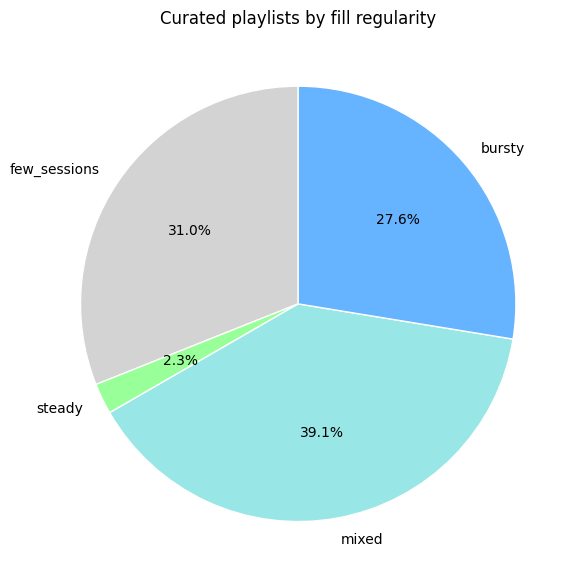

In [101]:
# 6.5 Характеристики curated-плейлистов

# Как именно ведётся живое ядро коллекции — curated-плейлисты.
# Для каждого считаем метрики пополнения:
#   add_days          — сколько уникальных дней добавления
#   lifespan_days     — от первого до последнего добавления
#   avg_session_size  — средняя порция за день
#   max_session_size  — максимальная разовая добавка
#   median_interval   — медианный интервал между добавлениями (дней)
#   interval_cv       — коэффициент вариации интервалов
#   top_day_share     — доля треков в самый активный день
#
# Плейлисты с add_days < 5 выделены в few_sessions:
# для них CV интервалов неинформативен.

print('ℹ️ Analyzing curated playlists only.')
print('   Playlists with < 5 adding days are in few_sessions (CV not meaningful).\n')

# Автономная подготовка own_links
if 'own_links' not in globals():
    own_links = playlist_links[
        playlist_links['playlist_type'].isin(['personal', 'collaborative'])
    ].copy()
    own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)


def calc_addition_metrics(group):
    """Метрики пополнения одного плейлиста."""
    total = len(group)
    if total == 0:
        return pd.Series({
            'add_days': 0, 'lifespan_days': 0,
            'avg_session_size': np.nan, 'max_session_size': np.nan,
            'median_interval_days': np.nan, 'interval_cv': np.nan,
            'top_day_share': np.nan
        })

    date_counts = group['Added At'].dt.date.value_counts()
    add_days = len(date_counts)

    session_sizes = group.groupby(group['Added At'].dt.date).size().sort_index()
    avg_session_size = session_sizes.mean()
    max_session_size = session_sizes.max()

    session_dates = pd.to_datetime(list(session_sizes.index))
    if len(session_dates) > 1:
        intervals = np.diff(session_dates).astype('timedelta64[D]').astype(int)
        median_interval = np.median(intervals)
        interval_cv = np.std(intervals) / np.mean(intervals) if np.mean(intervals) != 0 else 0.0
    else:
        median_interval = 0
        interval_cv = 0.0

    lifespan = (session_dates.max() - session_dates.min()).days
    top_day_share = date_counts.max() / total if total > 0 else np.nan

    return pd.Series({
        'add_days': add_days,
        'lifespan_days': lifespan,
        'avg_session_size': avg_session_size,
        'max_session_size': max_session_size,
        'median_interval_days': median_interval,
        'interval_cv': interval_cv,
        'top_day_share': top_day_share
    })


metrics = own_links.groupby('name_norm', group_keys=False).apply(
    calc_addition_metrics, include_groups=False
).reset_index()

curated_names = set(fill_df.loc[fill_df['fill_type'] == 'curated', 'name_norm'])
curated_metrics = metrics[metrics['name_norm'].isin(curated_names)].copy()

# Общая сводка
metric_cols = ['add_days', 'lifespan_days', 'avg_session_size', 'max_session_size',
               'median_interval_days', 'interval_cv', 'top_day_share']
overall_summary = curated_metrics[metric_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
overall_summary = overall_summary[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2)
overall_summary.columns = ['N', 'Mean', 'Std', 'Min', 'Q1', 'Median', 'Q3', 'Max']

print('📊 Curated: addition metrics summary:')
display(overall_summary)


# --- Подгруппы по регулярности ---
valid_for_cv = curated_metrics[curated_metrics['add_days'] >= 5].copy()


def cv_category(cv):
    if cv <= 0.5:
        return 'steady'
    elif cv <= 1.5:
        return 'mixed'
    else:
        return 'bursty'


valid_for_cv['cv_category'] = valid_for_cv['interval_cv'].apply(cv_category)

few_count = len(curated_metrics[curated_metrics['add_days'] < 5])

cv_order = ['steady', 'mixed', 'bursty']
cv_summary_raw = valid_for_cv.groupby('cv_category').agg(
    playlists=('name_norm', 'size'),
    add_days=('add_days', 'median'),
    lifespan_days=('lifespan_days', 'median'),
    avg_session_size=('avg_session_size', 'median'),
    max_session_size=('max_session_size', 'median'),
    median_interval_days=('median_interval_days', 'median'),
    interval_cv=('interval_cv', 'median'),
    top_day_share=('top_day_share', 'median')
).reindex(cv_order).round(2)

cv_summary = cv_summary_raw.reset_index().rename(columns={'cv_category': 'Subgroup'})
cv_summary.insert(0, '№', range(1, len(cv_summary) + 1))
cv_summary['Subgroup'] = cv_summary['Subgroup'].map({
    'steady': 'steady (CV≤0.5)',
    'mixed': 'mixed (0.5<CV≤1.5)',
    'bursty': 'bursty (CV>1.5)',
})
cv_summary.columns = ['№', 'Subgroup', 'Playlists', 'Adding days', 'Lifespan',
                      'Mean portion', 'Max portion', 'Interval', 'CV interval', 'Top-day share']

print(f'\nℹ️ Playlists with < 5 adding days (few_sessions): {few_count} of {len(curated_metrics)}')
print('📊 Curated subgroups by fill regularity (≥5 adding days):')
display(cv_summary.round(2))


# --- Легенда ---
legend_df = pd.DataFrame({
    'Metric': ['Adding days', 'Lifespan', 'Mean portion', 'Max portion',
               'Interval', 'CV interval', 'Top-day share'],
    'Description': [
        'unique dates when tracks were added',
        'days from first to last addition',
        'average number of tracks added per day',
        'largest single-day batch',
        'median days between additions',
        'coefficient of variation of intervals (lower = more regular)',
        'share of all tracks added on the most active day'
    ]
})
legend_df.index = range(1, len(legend_df) + 1)
legend_df.index.name = '№'
print('\nLegend:')
display(legend_df)


# --- Автоматический вывод ---
print('\n🔍 Auto conclusion:')
for cat in cv_order:
    row = cv_summary_raw.loc[cat]
    print(
        f"• {cat}: {int(row['playlists'])} playlists, "
        f"{int(row['add_days'])} adding days, "
        f"lifespan {int(row['lifespan_days'])} days, "
        f"mean portion {row['avg_session_size']}, "
        f"max {int(row['max_session_size'])}, "
        f"interval {int(row['median_interval_days'])} days, "
        f"top-day {row['top_day_share']:.2f}"
    )


# --- Пирог распределения подгрупп ---
pie_counts = pd.Series({
    'few_sessions': few_count,
    'steady': len(valid_for_cv[valid_for_cv['cv_category'] == 'steady']),
    'mixed': len(valid_for_cv[valid_for_cv['cv_category'] == 'mixed']),
    'bursty': len(valid_for_cv[valid_for_cv['cv_category'] == 'bursty']),
})

pie_colors_map = {
    'few_sessions': COLORS['muted'],
    'steady': COLORS['success'],
    'mixed': COLORS['secondary'],
    'bursty': COLORS['primary'],
}

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    pie_counts, labels=pie_counts.index, autopct='%1.1f%%',
    startangle=90,
    colors=[pie_colors_map[c] for c in pie_counts.index],
    wedgeprops=dict(edgecolor='white', linewidth=1)
)
ax.set_title('Curated playlists by fill regularity')
plt.tight_layout()
plt.show()

### 6.5. Вывод

**Что смотрели.** Метрики пополнения 87 **curated** плейлистов: сколько дней добавлялись, как долго жили, какими порциями.

**Результат.** Распределения сильно скошены. Медиана `add_days` — 8, но максимум 131. Медиана `lifespan` — 213 дней, максимум 1703. Медиана порции за день — 3.43 трека, среднее 10.48, максимум 112.5. Средние выше медиан в несколько раз — единичные крупные плейлисты тянут распределение.

27 из 87 (31.0%) имеют меньше 5 дней добавления. Для них CV интервалов не считается. Из оставшихся 60: **mixed** — 34 (39.1% от всех 87), **bursty** — 24 (27.6%), **steady** — 2 (2.3%). **Mixed**: 10 дней добавления, lifespan 189 дней, порция 3.34. **Bursty**: 32 дня, 491 день, порция 3.15, CV интервалов 1.88 против 1.07 у **mixed**.

**Вывод.** **Curated** — не одна стратегия. Треть плейлистов пополнялась меньше пяти раз, по ним режим не определяется. У остальных доминирует **mixed**: добавления раз в неделю-две небольшими порциями, интервалы предсказуемые. **Bursty** отличается не частотой добавлений, а их неравномерностью: интервалы колеблются сильнее, при этом плейлист живёт дольше. **Steady** в данных практически нет.

**Ограничения.** **Steady** — 2 плейлиста, выводы по нему невозможны. CV интервалов считается только для плейлистов с ≥5 днями добавления, 27 из 87 исключены. Пороги (5 добавлений, CV 0.5 и 1.5) — эвристика, не выведенная из данных. Максимум `avg_session_size` 112.5 — выброс, влияющий на средние по всей выборке.

## 6.6 Жанры и аудио-характеристики подгрупп curated


ℹ️ Analyzing curated playlists only.
   Subgroups: few_sessions (<5 adding days), steady, mixed, bursty.



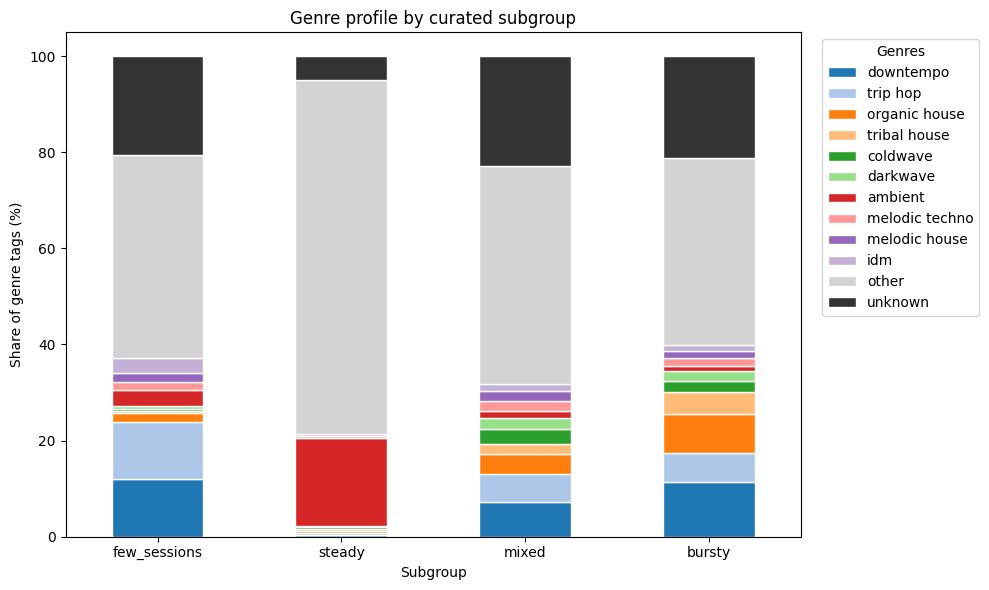

📊 Genre profile by curated subgroup (% of genre tags):


,downtempo,trip hop,organic house,tribal house,coldwave,darkwave,ambient,melodic techno,melodic house,idm,other,unknown
few_sessions,12.0,11.9,1.7,0.5,0.4,0.8,3.2,1.8,1.7,3.1,42.4,20.5
steady,0.4,0.4,0.4,0.4,0.4,0.4,18.3,0.4,0.0,0.4,73.8,4.9
mixed,7.3,5.7,4.3,2.0,3.0,2.4,1.4,2.2,2.1,1.3,45.5,22.8
bursty,11.4,6.0,8.0,4.6,2.2,2.2,1.1,1.5,1.6,1.1,39.0,21.2



📊 Median audio features by curated subgroup:


,valence,energy,danceability,acousticness,instrumentalness,popularity,tempo
few_sessions,0.250,0.504,0.585,0.262,0.506,6.0,119.042
steady,0.055,0.276,0.263,0.722,0.872,24.0,100.790
mixed,0.242,0.537,0.613,0.211,0.493,24.0,119.965
bursty,0.248,0.501,0.631,0.259,0.603,28.0,117.026



Playlist count by subgroup: {'few_sessions': 27, 'steady': 2, 'mixed': 34, 'bursty': 24}

📊 Statistical significance (Kruskal-Wallis):
  valence: not significant (p=0.652)
  energy: significant (p=2.299e-07)
    ✅ few_sessions vs mixed: few_sessions lower by 0.037
    ✅ mixed vs bursty: mixed higher by 0.030
  danceability: significant (p=6.551e-12)
    ✅ few_sessions vs mixed: few_sessions lower by 0.027
    ✅ few_sessions vs bursty: few_sessions lower by 0.044
    ⚠️ mixed vs bursty: significant, but below threshold
  acousticness: significant (p=6.935e-05)
    ✅ few_sessions vs mixed: few_sessions higher by 0.047
    ✅ mixed vs bursty: mixed lower by 0.029
  instrumentalness: significant (p=2.563e-03)
    ✅ mixed vs bursty: mixed lower by 0.041
  popularity: significant (p=3.821e-38)
    ✅ few_sessions vs mixed: few_sessions lower by 6.033
    ✅ few_sessions vs bursty: few_sessions lower by 8.362
    ⚠️ mixed vs bursty: significant, but below threshold
  tempo: not significant (p=0

In [102]:
# 6.6 Жанры и аудио-характеристики подгрупп curated

# Различаются ли модели кураторства внутри curated
# (few_sessions, steady, mixed, bursty) не только по поведению,
# но и по музыкальному содержанию.

print('ℹ️ Analyzing curated playlists only.')
print('   Subgroups: few_sessions (<5 adding days), steady, mixed, bursty.\n')

# Пересоздаём own_links
if 'own_links' not in globals():
    own_links = playlist_links[
        playlist_links['playlist_type'].isin(['personal', 'collaborative'])
    ].copy()
    own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)


def calc_add_days_and_cv(group):
    """Только add_days и interval_cv для классификации подгруппы."""
    total = len(group)
    if total == 0:
        return 0, 0.0
    dates = group['Added At'].dropna()
    date_counts = dates.dt.date.value_counts()
    add_days = len(date_counts)
    session_sizes = group.groupby(dates.dt.date).size().sort_index()
    session_dates = pd.to_datetime(list(session_sizes.index))
    if len(session_dates) > 1:
        intervals = np.diff(session_dates).astype('timedelta64[D]').astype(int)
        interval_cv = np.std(intervals) / np.mean(intervals) if np.mean(intervals) != 0 else 0.0
    else:
        interval_cv = 0.0
    return add_days, interval_cv


metrics = own_links.groupby('name_norm', group_keys=False).apply(
    lambda g: pd.Series(calc_add_days_and_cv(g), index=['add_days', 'interval_cv']),
    include_groups=False
).reset_index()

curated_names = set(fill_df.loc[fill_df['fill_type'] == 'curated', 'name_norm'])
curated_metrics = metrics[metrics['name_norm'].isin(curated_names)].copy()


def curated_subgroup(row):
    if row['add_days'] < 5:
        return 'few_sessions'
    elif row['interval_cv'] <= 0.5:
        return 'steady'
    elif row['interval_cv'] <= 1.5:
        return 'mixed'
    else:
        return 'bursty'


curated_metrics['subgroup'] = curated_metrics.apply(curated_subgroup, axis=1)

# Присоединяем подгруппу к fill_df
fill_df = fill_df.merge(curated_metrics[['name_norm', 'subgroup']], on='name_norm', how='left')
fill_df['subgroup'] = fill_df['subgroup'].fillna('not_curated')


# --- Собираем треки по подгруппам ---
def get_tracks_for_subgroup(subgroup_name):
    names = set(fill_df.loc[fill_df['subgroup'] == subgroup_name, 'name_norm'])
    uris = playlist_links[playlist_links['name_norm'].isin(names)]['Track URI'].unique()
    return tracks_exportify[tracks_exportify['spotify_track_uri'].isin(uris)]


subgroups = ['few_sessions', 'steady', 'mixed', 'bursty']
subgroup_tracks = {sg: get_tracks_for_subgroup(sg) for sg in subgroups}

# --- Жанровый профиль ---
all_tags = []
for sg in subgroups:
    tracks = subgroup_tracks[sg]
    genres = tracks['genres_normalized'].dropna().str.split(',').explode().str.strip()
    genres = genres[genres != 'unknown']
    all_tags.extend(genres.tolist())
top10_genres = pd.Series(all_tags).value_counts().head(10).index.tolist()


def calculate_genre_share(tracks, top10):
    genres = tracks['genres_normalized'].dropna().str.split(',').explode().str.strip()
    total = len(genres)
    other_count = 0
    unknown_count = 0
    top_counts = {g: 0 for g in top10}
    for g in genres:
        if g == 'unknown':
            unknown_count += 1
        elif g in top_counts:
            top_counts[g] += 1
        else:
            other_count += 1
    if total == 0:
        return [0] * (len(top10) + 2)
    shares = [top_counts[g] / total * 100 for g in top10]
    shares += [other_count / total * 100, unknown_count / total * 100]
    return shares


genre_rows = {sg: calculate_genre_share(subgroup_tracks[sg], top10_genres) for sg in subgroups}
genre_df = pd.DataFrame(genre_rows, index=top10_genres + ['other', 'unknown']).T

tab20 = plt.cm.tab20.colors
genre_colors = {g: tab20[i % len(tab20)] for i, g in enumerate(top10_genres)}
genre_colors['other'] = COLORS['muted']
genre_colors['unknown'] = '#333333'

ax = genre_df.plot(
    kind='bar', stacked=True, figsize=(10, 6),
    color=[genre_colors[g] for g in genre_df.columns],
    edgecolor='white'
)
ax.set_title('Genre profile by curated subgroup')
ax.set_xlabel('Subgroup')
ax.set_ylabel('Share of genre tags (%)')
ax.legend(title='Genres', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

print('📊 Genre profile by curated subgroup (% of genre tags):')
display(genre_df.round(1))


# --- Аудио-характеристики ---
features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'popularity', 'tempo']

med_rows = {}
for sg in subgroups:
    tracks = subgroup_tracks[sg]
    med_rows[sg] = [tracks[f].dropna().median() for f in features]

med_df = pd.DataFrame(med_rows, index=features).T
formatters = {f: ('{:.1f}' if f in ['popularity', 'tempo'] else '{:.3f}') for f in features}

print('\n📊 Median audio features by curated subgroup:')
display(med_df.round(3))


# --- Статистика (без steady — там 2 плейлиста) ---
subgroup_playlists_count = {
    sg: len(set(fill_df.loc[fill_df['subgroup'] == sg, 'name_norm']))
    for sg in subgroups
}
print('\nPlaylist count by subgroup:', subgroup_playlists_count)

subgroups_for_kw = [sg for sg in subgroups if subgroup_playlists_count[sg] >= 5 and sg != 'steady']

if len(subgroups_for_kw) >= 2:
    print('\n📊 Statistical significance (Kruskal-Wallis):')
    for feat in features:
        groups = [subgroup_tracks[sg][feat].dropna() for sg in subgroups_for_kw]
        if any(len(g) < 30 for g in groups):
            print(f'  {feat}: insufficient data')
            continue
        h, p = kruskal(*groups)
        if p < 0.05:
            print(f'  {feat}: significant (p={p:.3e})')
            for sg1, sg2 in combinations(subgroups_for_kw, 2):
                a = subgroup_tracks[sg1][feat].dropna()
                b = subgroup_tracks[sg2][feat].dropna()
                u, p_pair = stats.mannwhitneyu(a, b, alternative='two-sided')
                mean_diff = a.mean() - b.mean()
                thresh = PRACTICAL_THRESHOLDS.get(feat, 0.02)
                if p_pair < 0.05 and abs(mean_diff) >= thresh:
                    direction = 'higher' if mean_diff > 0 else 'lower'
                    print(f'    ✅ {sg1} vs {sg2}: {sg1} {direction} by {abs(mean_diff):.3f}')
                elif p_pair < 0.05 and abs(mean_diff) < thresh:
                    print(f'    ⚠️ {sg1} vs {sg2}: significant, but below threshold')
        else:
            print(f'  {feat}: not significant (p={p:.3f})')
else:
    print('\nNot enough subgroups for statistical test.')

### 6.6. Вывод

**Что смотрели.** Жанровый профиль и медианы аудио по подгруппам **curated**.

**Результат.** Жанрово подгруппы различаются слабо. downtempo и trip hop есть у всех: 12.0 и 11.9 у **few_sessions**, 7.3 и 5.7 у **mixed**, 11.4 и 6.0 у **bursty**. Различие — в organic house (8.0 у **bursty** против 1.7 у **few_sessions**) и tribal house (4.6 против долей ниже 1).

Аудио различает сильнее. **few_sessions**: popularity 6.0. **mixed**: 24.0. **bursty**: 28.0. Все три попарных различия по popularity значимы. **Bursty** выше **mixed** по instrumentalness (0.603 против 0.493) и ниже по acousticness (0.259 против 0.211). По valence и tempo различий нет.

**Вывод.** Подгруппы **curated** различаются не жанром, а степенью погружения. **Few_sessions** — плейлисты с минимальным участием: мало добавлений, самая низкая popularity. **Bursty** — самые продуманные: долгий срок жизни, высокий instrumentalness, выше доля organic house. **Mixed** — между ними. Это не три разных музыкальных вкуса, а три уровня вовлечённости в одном жанровом поле.

**Ограничения.** **Steady** — 2 плейлиста, в статистику не включён. **Unknown** в жанрах: 20.5–22.8% у **few_sessions**, **mixed** и **bursty**. Жанровые выводы по этим подгруппам ограничены. Organic house у **bursty** — 8.0% при 24 плейлистах, доля неустойчива.

## 6.7. Создание и жизнь подгрупп curated во времени

**Когорта** — плейлисты одного года создания. **Cohort survival** — доля плейлистов когорты, которые ещё пополнялись в каждый последующий год. Плейлист считается выжившим в году Y, если его последнее добавление не раньше Y.

ℹ️ Analyzing curated subgroups: few_sessions, steady, mixed, bursty.

📊 Curated playlists by creation year (counts):


subgroup,few_sessions,mixed,bursty,steady
creation_year,,,,
2020,4,1,0,1
2021,9,8,3,0
2022,2,8,2,0
2023,3,3,3,0
2024,1,6,8,0
2025,5,7,8,1
2026,3,1,0,0



📊 Share of subgroups within creation year (%):


subgroup,few_sessions,mixed,bursty,steady
creation_year,,,,
2020,66.7,16.7,0.0,16.7
2021,45.0,40.0,15.0,0.0
2022,16.7,66.7,16.7,0.0
2023,33.3,33.3,33.3,0.0
2024,6.7,40.0,53.3,0.0
2025,23.8,33.3,38.1,4.8
2026,75.0,25.0,0.0,0.0


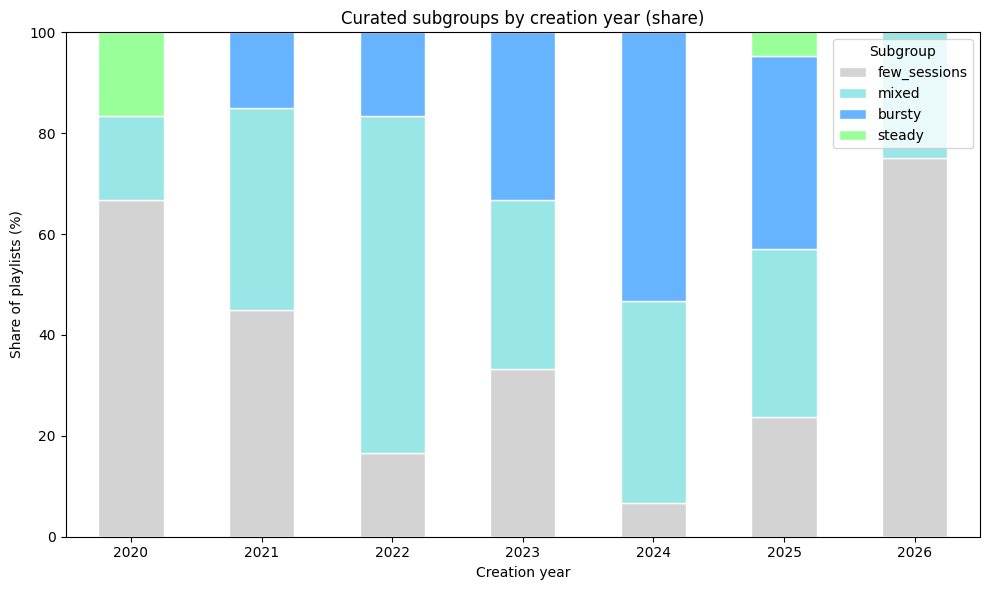


📊 Cohort survival (fill activity): few_sessions


,2020,2021,2022,2023,2024,2025,2026
2020,100.0,75.0,0.0,0.0,0.0,0.0,0.0
2021,NaN,100.0,0.0,0.0,0.0,0.0,0.0
2022,NaN,NaN,100.0,100.0,100.0,100.0,0.0
2023,NaN,NaN,NaN,100.0,33.3,33.3,0.0
2024,NaN,NaN,NaN,NaN,100.0,0.0,0.0
2025,NaN,NaN,NaN,NaN,NaN,100.0,40.0
2026,NaN,NaN,NaN,NaN,NaN,NaN,100.0


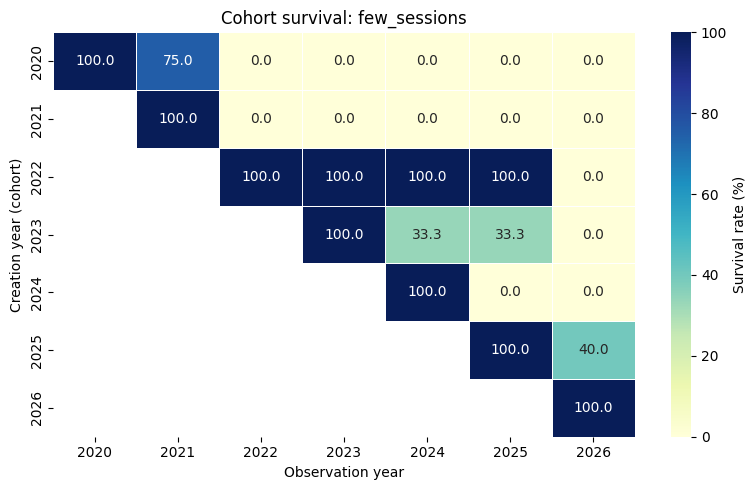


📊 Cohort survival (fill activity): mixed


,2020,2021,2022,2023,2024,2025,2026
2020,100.0,100.0,0.0,0.0,0.0,0.0,0.0
2021,NaN,100.0,25.0,12.5,12.5,12.5,0.0
2022,NaN,NaN,100.0,37.5,12.5,12.5,0.0
2023,NaN,NaN,NaN,100.0,66.7,66.7,0.0
2024,NaN,NaN,NaN,NaN,100.0,100.0,16.7
2025,NaN,NaN,NaN,NaN,NaN,100.0,57.1
2026,NaN,NaN,NaN,NaN,NaN,NaN,100.0


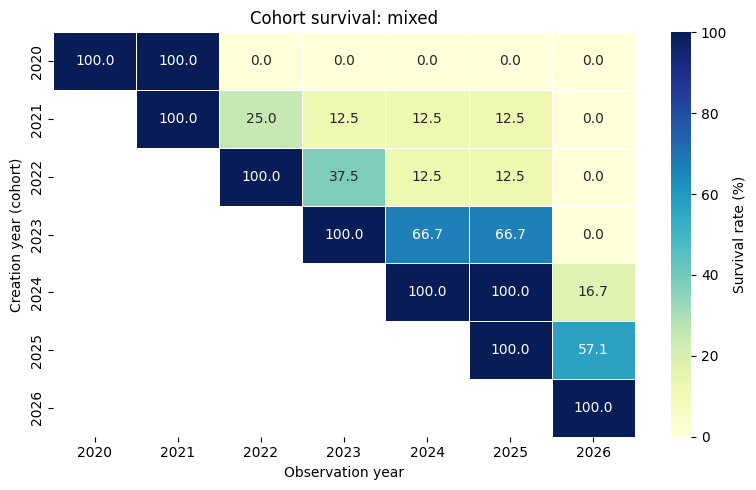


📊 Cohort survival (fill activity): bursty


,2021,2022,2023,2024,2025,2026
2021,100.0,66.7,0.0,0.0,0.0,0.0
2022,NaN,100.0,100.0,100.0,100.0,50.0
2023,NaN,NaN,100.0,100.0,66.7,66.7
2024,NaN,NaN,NaN,100.0,100.0,62.5
2025,NaN,NaN,NaN,NaN,100.0,87.5
2026,NaN,NaN,NaN,NaN,NaN,NaN


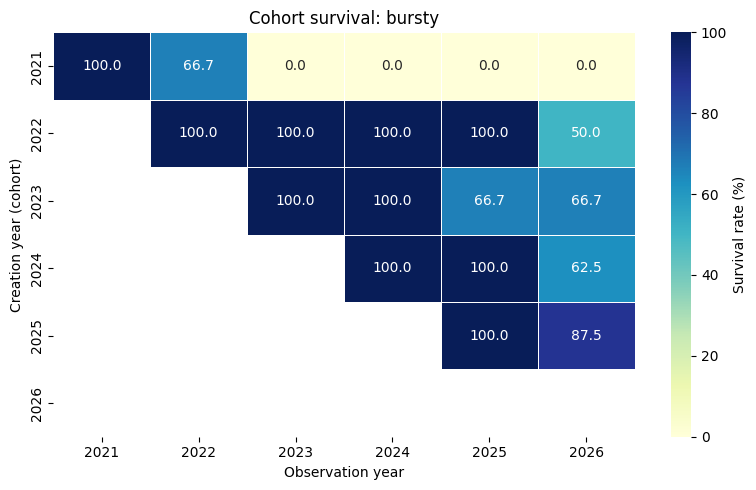


⚠️ steady: insufficient playlists for cohort survival.


In [103]:
# 6.7 Создание и жизнь подгрупп curated во времени

# Когда создавались curated-плейлисты разных подгрупп
# (few_sessions, steady, mixed, bursty), и как долго они живут.
#
# Две части:
#   1. Распределение по годам создания.
#   2. Когортная выживаемость по пополнению — доля плейлистов,
#      которые ещё пополнялись в каждый последующий год.

print('ℹ️ Analyzing curated subgroups: few_sessions, steady, mixed, bursty.\n')
# Если subgroup не попала в fill_df — пересчитываем
if 'subgroup' not in fill_df.columns:
    if 'own_links' not in globals():
        own_links = playlist_links[
            playlist_links['playlist_type'].isin(['personal', 'collaborative'])
        ].copy()
        own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)

    def _calc_add_days_and_cv(group):
        total = len(group)
        if total == 0:
            return 0, 0.0
        dates = group['Added At'].dropna()
        date_counts = dates.dt.date.value_counts()
        add_days = len(date_counts)
        session_sizes = group.groupby(dates.dt.date).size().sort_index()
        session_dates = pd.to_datetime(list(session_sizes.index))
        if len(session_dates) > 1:
            intervals = np.diff(session_dates).astype('timedelta64[D]').astype(int)
            cv = np.std(intervals) / np.mean(intervals) if np.mean(intervals) != 0 else 0.0
        else:
            cv = 0.0
        return add_days, cv

    _m = own_links.groupby('name_norm', group_keys=False).apply(
        lambda g: pd.Series(_calc_add_days_and_cv(g), index=['add_days', 'interval_cv']),
        include_groups=False
    ).reset_index()

    _curated_names = set(fill_df.loc[fill_df['fill_type'] == 'curated', 'name_norm'])
    _curated_metrics = _m[_m['name_norm'].isin(_curated_names)].copy()

    def _curated_subgroup(row):
        if row['add_days'] < 5:
            return 'few_sessions'
        elif row['interval_cv'] <= 0.5:
            return 'steady'
        elif row['interval_cv'] <= 1.5:
            return 'mixed'
        else:
            return 'bursty'

    _curated_metrics['subgroup'] = _curated_metrics.apply(_curated_subgroup, axis=1)
    fill_df = fill_df.merge(
        _curated_metrics[['name_norm', 'subgroup']],
        on='name_norm', how='left'
    )
    fill_df['subgroup'] = fill_df['subgroup'].fillna('not_curated')
    print('ℹ️ subgroup recomputed and added to fill_df.')
# Убеждаемся, что own_links есть
if 'own_links' not in globals():
    own_links = playlist_links[
        playlist_links['playlist_type'].isin(['personal', 'collaborative'])
    ].copy()
    own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)

# Год создания и последнего добавления
add_years = own_links.groupby('name_norm')['Added At'].agg(
    creation_year=lambda x: x.min().year,
    last_year=lambda x: x.max().year
).reset_index()

# Присоединяем подгруппу
curated_metrics_7 = fill_df[['name_norm', 'subgroup']].drop_duplicates().merge(
    add_years, on='name_norm', how='left'
)
curated_metrics_7 = curated_metrics_7[
    curated_metrics_7['subgroup'].isin(['few_sessions', 'steady', 'mixed', 'bursty'])
].copy()


# ==========================================
# ЧАСТЬ 1: Распределение по годам создания
# ==========================================
cross_subgroup_year = pd.crosstab(
    curated_metrics_7['creation_year'],
    curated_metrics_7['subgroup']
)
subgroup_order = ['few_sessions', 'mixed', 'bursty', 'steady']
cross_subgroup_year = cross_subgroup_year.reindex(columns=subgroup_order, fill_value=0)

print('📊 Curated playlists by creation year (counts):')
display(cross_subgroup_year)

cross_subgroup_year_pct = cross_subgroup_year.div(cross_subgroup_year.sum(axis=1), axis=0) * 100

print('\n📊 Share of subgroups within creation year (%):')
display(cross_subgroup_year_pct.round(1))

# Палитра подгрупп curated
subgroup_colors = {
    'few_sessions': COLORS['muted'],
    'mixed': COLORS['secondary'],
    'bursty': COLORS['primary'],
    'steady': COLORS['success'],
}

ax = cross_subgroup_year_pct[subgroup_order].plot(
    kind='bar', stacked=True, figsize=(10, 6),
    color=[subgroup_colors[s] for s in subgroup_order],
    edgecolor='white'
)
ax.set_title('Curated subgroups by creation year (share)')
ax.set_xlabel('Creation year')
ax.set_ylabel('Share of playlists (%)')
ax.legend(title='Subgroup')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()


# ==========================================
# ЧАСТЬ 2: Когортная выживаемость по пополнению
# ==========================================
def cohort_survival_for_subgroup(subgroup_name):
    """
    Доля плейлистов когорты, которые ещё пополнялись в каждый год.
    Когорта = год создания. Плейлист выжил в году Y, если last_year >= Y.
    """
    sub = curated_metrics_7[curated_metrics_7['subgroup'] == subgroup_name].copy()
    if len(sub) < 5:
        return None

    years = sorted(set(sub['creation_year'].dropna().astype(int)) |
                   set(sub['last_year'].dropna().astype(int)))
    survival = pd.DataFrame(index=years, columns=years, dtype=float)

    for cy in years:
        cohort = sub[sub['creation_year'] == cy]
        total = len(cohort)
        if total == 0:
            survival.loc[cy] = np.nan
            continue
        for oy in years:
            if oy < cy:
                survival.loc[cy, oy] = np.nan
            else:
                survived = (cohort['last_year'] >= oy).sum()
                survival.loc[cy, oy] = survived / total * 100
    return survival


for sg in subgroup_order:
    surv = cohort_survival_for_subgroup(sg)
    if surv is None:
        print(f'\n⚠️ {sg}: insufficient playlists for cohort survival.')
        continue

    print(f'\n📊 Cohort survival (fill activity): {sg}')
    display(surv.round(1))

    plt.figure(figsize=(8, 5))
    sns.heatmap(
        surv.astype(float),
        annot=True, fmt='.1f', cmap='YlGnBu',
        cbar_kws={'label': 'Survival rate (%)'},
        linewidths=0.5, mask=surv.isna()
    )
    plt.title(f'Cohort survival: {sg}')
    plt.xlabel('Observation year')
    plt.ylabel('Creation year (cohort)')
    plt.tight_layout()
    plt.show()

### 6.7. Вывод

**Что смотрели.** Как подгруппы **curated** распределены по годам создания и как долго каждая когорта продолжает пополняться. Выживаемость — доля плейлистов когорты, у которых последнее добавление не раньше данного года.

**Результат.** По годам доли смещаются. В 2020–2021 доминирует **few_sessions** (66.7% и 45.0%). К 2024–2025 вперёд выходит **bursty** (53.3% и 38.1%), **few_sessions** падает до 6.7% и 23.8%. **Mixed** держится ровно: 33–40% каждый год.

Выживаемость различается сильно. **Few_sessions** умирают в первые два года: когорты 2020 и 2021 к третьему году дают 0%. **Mixed** живут дольше: когорта 2023 держит 66.7% на второй год, 2025 — 57.1%. **Bursty** — самые живучие: когорта 2022 сохраняет 100% до 2025 года, 2023 — 66.7%, 2024 — 62.5%, 2025 — 87.5%.

**Вывод.** Регулярность пополнения связана с долговечностью. **Few_sessions** — стартовая стратегия ранних лет: плейлисты быстро забрасываются. **Bursty** — поздняя и самая устойчивая: плейлисты живут годами, возвращаясь к пополнению. Сдвиг в составе **curated** по годам — не косметический: меняется не только доля, но и тип поведения за ней.

**Ограничения.** **Steady** — 2 плейлиста, выживаемость не считается. 2026 — неполный год. Когорты малы: от 1 до 9 плейлистов в год на подгруппу, отдельные доли выживаемости держатся на единичных случаях. «Выживаемость» здесь — по пополнению, а не по прослушиванию; это разные вещи, вторая считается в 6.8.

ℹ️ Analyzing curated subgroups: few_sessions, mixed, bursty, steady.
   Playlist is active in a year if at least 10% of its unique tracks were played validly.


📊 Cohort listening survival: few_sessions (threshold 10%)


,2020,2021,2022,2023,2024,2025,2026
2020,25.0,50.0,0.0,0.0,0.0,25.0,0.0
2021,NaN,88.9,77.8,22.2,0.0,33.3,0.0
2022,NaN,NaN,100.0,50.0,50.0,100.0,50.0
2023,NaN,NaN,NaN,100.0,66.7,66.7,33.3
2025,NaN,NaN,NaN,NaN,NaN,100.0,60.0
2026,NaN,NaN,NaN,NaN,NaN,NaN,100.0


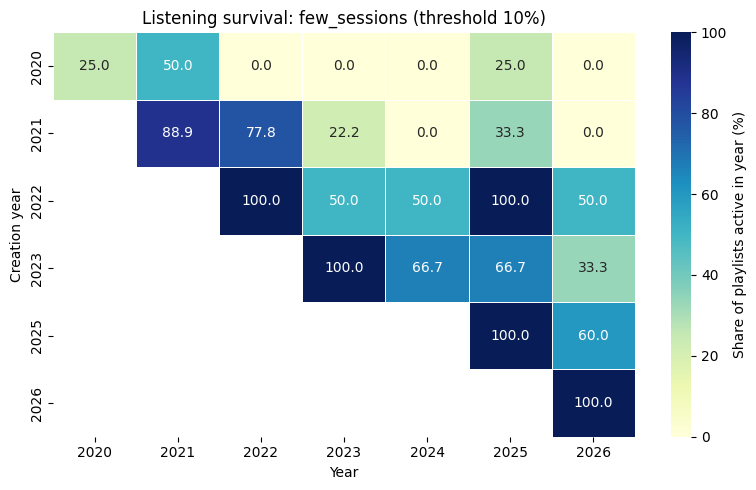


📊 Cohort listening survival: mixed (threshold 10%)


,2020,2021,2022,2023,2024,2025,2026
2020,100.0,100.0,100.0,0.0,0.0,0.0,0.0
2021,NaN,87.5,62.5,62.5,25.0,50.0,25.0
2022,NaN,NaN,100.0,100.0,37.5,62.5,25.0
2023,NaN,NaN,NaN,100.0,66.7,66.7,33.3
2024,NaN,NaN,NaN,NaN,83.3,100.0,50.0
2025,NaN,NaN,NaN,NaN,NaN,100.0,85.7
2026,NaN,NaN,NaN,NaN,NaN,NaN,100.0


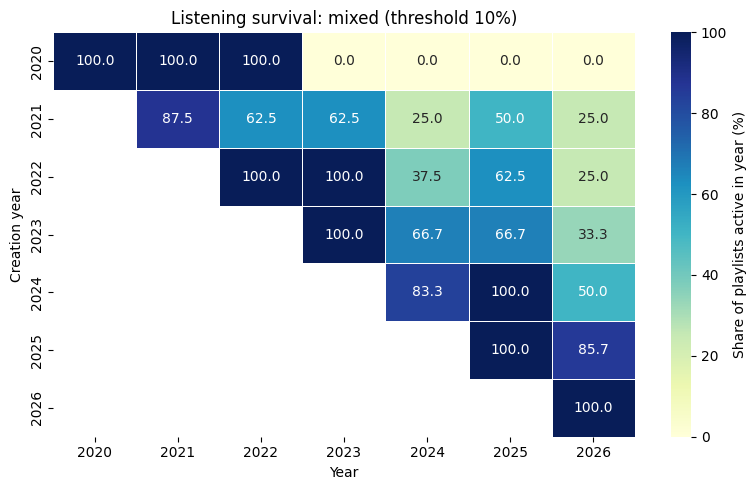


📊 Cohort listening survival: bursty (threshold 10%)


,2020,2021,2022,2023,2024,2025,2026
2021,NaN,66.7,66.7,33.3,0.0,0.0,0.0
2022,NaN,NaN,100.0,100.0,50.0,100.0,0.0
2023,NaN,NaN,NaN,100.0,100.0,100.0,66.7
2024,NaN,NaN,NaN,NaN,87.5,100.0,75.0
2025,NaN,NaN,NaN,NaN,NaN,100.0,87.5


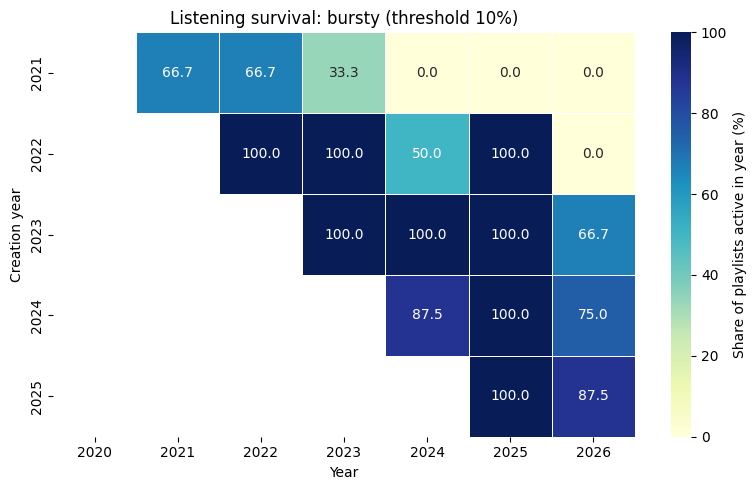


📊 Cohort listening survival: steady (threshold 10%)


,2020,2021,2022,2024,2025,2026
2020,100.0,100.0,100.0,0.0,0.0,0.0
2025,NaN,NaN,NaN,NaN,100.0,0.0


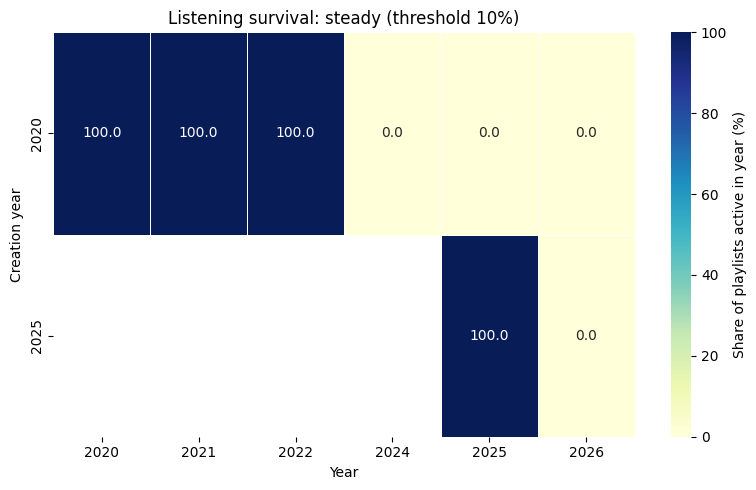

In [104]:
# 6.8 Выживаемость подгрупп curated по прослушиванию

# Отличается от 6.7: там смотрели, пополняется ли плейлист,
# здесь — слушается ли он. Плейлист считается активным в году,
# если не менее MIN_UNIQUE_SHARE его уникальных треков
# было прослушано валидно в этом году.

MIN_UNIQUE_SHARE = 0.10

print(f'ℹ️ Analyzing curated subgroups: few_sessions, mixed, bursty, steady.')
print(f'   Playlist is active in a year if at least {MIN_UNIQUE_SHARE*100:.0f}% '
      f'of its unique tracks were played validly.\n')

# Пересоздаём own_links
if 'own_links' not in globals():
    own_links = playlist_links[
        playlist_links['playlist_type'].isin(['personal', 'collaborative'])
    ].copy()
    own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)

# Связи плейлист-трек
pl_tracks = own_links[['name_norm', 'Track URI']].drop_duplicates()

# Валидные прослушивания: трек → годы
valid = df_events[df_events['valid_play']].copy()
valid['year'] = pd.to_datetime(valid['ts'], errors='coerce').dt.year
track_years = valid.groupby('spotify_track_uri')['year'].unique().reset_index()
track_years = track_years.explode('year')
track_years['year'] = track_years['year'].astype(int)

# Присоединяем годы прослушиваний
pl_year = pl_tracks.merge(
    track_years,
    left_on='Track URI', right_on='spotify_track_uri', how='inner'
)
pl_year = pl_year[['name_norm', 'year', 'Track URI']].drop_duplicates()

# Добавляем подгруппу
pl_year = pl_year.merge(
    fill_df[['name_norm', 'subgroup']],
    on='name_norm', how='left'
)
pl_year = pl_year[
    pl_year['subgroup'].isin(['few_sessions', 'steady', 'mixed', 'bursty'])
].copy()

# Добавляем год создания
add_years = own_links.groupby('name_norm')['Added At'].min().reset_index()
add_years.columns = ['name_norm', 'creation_date']
add_years['creation_year'] = add_years['creation_date'].dt.year
pl_year = pl_year.merge(
    add_years[['name_norm', 'creation_year']],
    on='name_norm', how='left'
)

# Уникальные треки на плейлист
unique_tracks_per_playlist = own_links.groupby('name_norm')['Track URI'].nunique().to_dict()

# Прослушанные уникальные треки в каждом году
listened_tracks_per_year = pl_year.groupby(
    ['name_norm', 'year', 'subgroup', 'creation_year']
)['Track URI'].nunique().reset_index()
listened_tracks_per_year.columns = ['name_norm', 'year', 'subgroup', 'creation_year', 'listened_unique']

listened_tracks_per_year['total_unique'] = (
    listened_tracks_per_year['name_norm'].map(unique_tracks_per_playlist)
)
listened_tracks_per_year['unique_share'] = (
    listened_tracks_per_year['listened_unique'] / listened_tracks_per_year['total_unique']
)


def cohort_listening_survival(subgroup_name):
    """
    Когортная выживаемость по прослушиванию:
    доля плейлистов когорты, активных в каждый год
    (не менее MIN_UNIQUE_SHARE уникальных треков прослушано).
    """
    sub = listened_tracks_per_year[
        listened_tracks_per_year['subgroup'] == subgroup_name
    ].copy()
    if len(sub) == 0:
        return None

    creation_years = sorted(sub['creation_year'].dropna().astype(int).unique())
    years = sorted(sub['year'].unique())
    survival = pd.DataFrame(index=creation_years, columns=years, dtype=float)

    for cy in creation_years:
        cohort = sub[sub['creation_year'] == cy]
        total_pl = cohort['name_norm'].nunique()
        if total_pl == 0:
            survival.loc[cy] = np.nan
            continue
        for y in years:
            if y < cy:
                survival.loc[cy, y] = np.nan
            else:
                active_pl = cohort[
                    (cohort['year'] == y) &
                    (cohort['unique_share'] >= MIN_UNIQUE_SHARE)
                ]['name_norm'].nunique()
                survival.loc[cy, y] = active_pl / total_pl * 100
    return survival


subgroup_order = ['few_sessions', 'mixed', 'bursty', 'steady']
for sg in subgroup_order:
    surv = cohort_listening_survival(sg)
    if surv is None:
        print(f'\n⚠️ {sg}: insufficient data.')
        continue

    print(f'\n📊 Cohort listening survival: {sg} '
          f'(threshold {MIN_UNIQUE_SHARE*100:.0f}%)')
    display(surv.round(1))

    plt.figure(figsize=(8, 5))
    sns.heatmap(
        surv.astype(float),
        annot=True, fmt='.1f', cmap='YlGnBu',
        cbar_kws={'label': 'Share of playlists active in year (%)'},
        linewidths=0.5, mask=surv.isna()
    )
    plt.title(f'Listening survival: {sg} (threshold {MIN_UNIQUE_SHARE*100:.0f}%)')
    plt.xlabel('Year')
    plt.ylabel('Creation year')
    plt.tight_layout()
    plt.show()

### 6.8. Вывод

**Что смотрели.** Выживаемость подгрупп **curated** по прослушиванию. Плейлист считается активным в году, если не менее 10% его уникальных треков прослушано валидно. Это не то же, что выживаемость по пополнению из 6.7.

**Результат.** Общий паттерн одинаков у всех подгрупп: когорты 2020–2021 к 2024–2025 в основном мертвы (0%). Когорты 2023–2025 ещё активны, но это ожидаемо — правый край истории.

Различаются подгруппы по скорости падения. **Bursty**, когорта 2023: 100% на второй и третий год, 66.7% на четвёртый. **Mixed**, когорта 2023: 100%, 66.7%, 33.3%. **Few_sessions**, когорта 2023: 100%, 66.7%, 33.3%. То есть **bursty** держит прослушивание на год дольше.

**Вывод.** По прослушиванию **bursty** выживает лучше остальных подгрупп — согласуется с 6.7, где **bursty** был самым живучим по пополнению. Но есть и расхождение: **few_sessions** в 6.7 умирали за 2 года, а здесь когорта 2023 держится три года на уровне 66.7%. То есть плейлисты **few_sessions** перестают пополняться, но какое-то время продолжают слушаться. Это тот же паттерн, что **abandoned_but_listened** в блоке 5.

**Ограничения.** Когорты малы: 1–9 плейлистов в год. Отдельные доли держатся на единичных случаях. **Steady** — 2 плейлиста. **Few_sessions** за 2024 в таблице отсутствует — когорта пустая. 2025–2026 — правый край истории, высокие доли там ожидаемы и не сравнимы с более старыми годами.

## Блок 6. Вывод

**Стратегии как этапы.** **Mass_import**, **batch** и **curated** — не три параллельных способа, а последовательность. Массовый перенос и пакетное копирование — стартовые стратегии первого года. **Curated** приходит им на смену и остаётся единственной. Это не выбор из трёх, а путь от одного к другому.

**Один признак — два следствия.** Способ наполнения связан и с тем, что с плейлистом происходит дальше, и с тем, что лежит внутри. **Mass_import** и **batch** дают заброшенные плейлисты с трансовым, инструментальным, громким содержимым. **Curated** — активные с даунтемпо и акустикой. Поведение и содержание идут вместе, а не независимо.

**Смена кураторства.** Внутри **curated** состав подгрупп по годам меняется: в ранние годы преобладают **few_sessions**, в поздние — **bursty**. Это смена типа кураторства, а не рост числа плейлистов. **Few_sessions** умирают по пополнению за два года, **bursty** живут годами. Соотношение между ними определяет, сколько в коллекции живого и сколько балласта.

**Заброшенность не равна исчезновению.** Выживаемость по пополнению и по прослушиванию расходятся. **Few_sessions** перестают пополняться быстро, но какое-то время продолжают слушаться. Тот же разрыв виден в блоке 5 между **abandoned** и **abandoned_but_listened**. Плейлист может быть мёртв по обновлению и жив по прослушиванию.

**Связка с блоком 5.** Блок 5 показал, что мёртвый груз существует и составляет большинство. Блок 6 объясняет, откуда он берётся: из **mass_import** и **batch** первого года. Без этого объяснения заброшенные плейлисты выглядели бы как свойство коллекции, а не как следствие конкретной стратегии.

**Связка с блоком 7.** **Curated** — единственная стратегия, возвращающая плейлисты в ротацию. Дальше вопрос — что происходит с треками, которые попадают в несколько плейлистов. Если повторы идут именно из **curated**, это подтверждает, что осознанный отбор создаёт ядро. Блок 7 считает Jaccard между типами наполнения и разбирает повторяющиеся треки.

# Блок 7. Пересечения и повторы

## Блок 7. Пересечения и повторы

Блок считает Jaccard между типами наполнения, ищет повторяющиеся треки, сравнивает их с уникальными по жанрам и аудио, разбирает происхождение и путь повторов.

Срез — **playlist_links**, **tracks_exportify**, **df_events** с **valid_play**. Единица анализа — уникальный трек.

**Jaccard (индекс Жаккара)** — мера сходства двух множеств. Считается как `|A ∩ B| / |A ∪ B|`: доля общих элементов от объединения. Значение от 0 (нет общих элементов) до 1 (множества совпадают). В отличие от абсолютного пересечения, не зависит от размера множеств: большие плейлисты не доминируют в матрице.

**Повторяющийся трек** — трек, который встречается в 2 и более собственных плейлистах (**personal** или **collaborative**). Считается по `num_playlists > 1`, где `num_playlists` — число уникальных **name_norm**, в которых есть этот трек.

**Уникальный трек** — трек, который встречается ровно в одном собственном плейлисте.

**Fill type combination** — набор типов наполнения, в которых встречается трек. Например, `curated` — трек только в **curated**-плейлистах, `curated+batch` — и там, и там.

**Происхождение повтора** — тип плейлиста, в котором трек появился впервые. Определяется по минимальной дате добавления среди всех вхождений.

**Задержка добавления** — разница в днях между первым валидным прослушиванием трека и первым добавлением в собственный плейлист. Отрицательное значение означает, что трек добавили до того, как его впервые прослушали.

1. Пересечения треков между типами наполнения (Jaccard).
2. Повторяющиеся треки.
3. Происхождение и путь повторяющихся треков.

## 7.1 Пересечения треков между типами наполнения (Jaccard)


ℹ️ Analyzing intersections of unique tracks between fill types: mass_import, batch, curated.

📊 Absolute intersections (tracks):


,mass_import,batch,curated
mass_import,3178.0,296.0,341.0
batch,296.0,2441.0,498.0
curated,341.0,498.0,5081.0



📊 Jaccard similarity:


,mass_import,batch,curated
mass_import,1.000,0.056,0.043
batch,0.056,1.000,0.071
curated,0.043,0.071,1.000


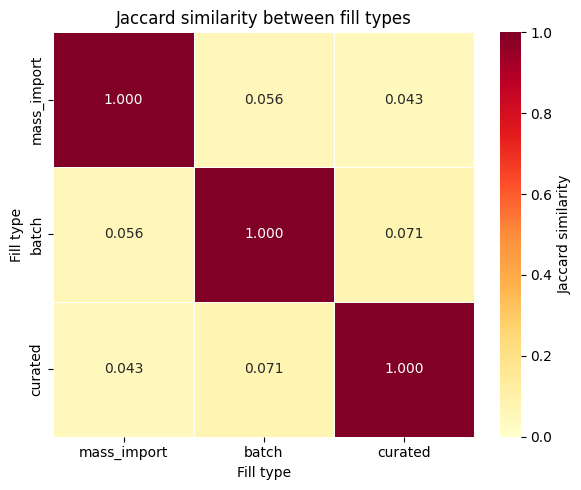

🔍 Highest similarity: batch ↔ curated
   Jaccard = 0.071, intersection = 498.0 tracks, union = 7024.0 tracks.


In [105]:
# 7.1 Пересечения треков между типами наполнения (Jaccard)

# Индекс Жаккара вместо абсолютных чисел:
#   J(A,B) = |A ∩ B| / |A ∪ B|
# Не даёт большим плейлистам доминировать.

print('ℹ️ Analyzing intersections of unique tracks between fill types: '
      'mass_import, batch, curated.\n')

# Множества URI по типам наполнения
mass_names = set(fill_df.loc[fill_df['fill_type'] == 'mass_import', 'name_norm'])
batch_names = set(fill_df.loc[fill_df['fill_type'] == 'batch', 'name_norm'])
curated_names = set(fill_df.loc[fill_df['fill_type'] == 'curated', 'name_norm'])


def get_uris(names):
    return set(
        playlist_links[playlist_links['name_norm'].isin(names)]['Track URI'].dropna()
    )


uri_dict = {
    'mass_import': get_uris(mass_names),
    'batch': get_uris(batch_names),
    'curated': get_uris(curated_names),
}
types = list(uri_dict.keys())

# Матрицы: абсолютное пересечение, размер объединения, Jaccard
intersection_abs = pd.DataFrame(index=types, columns=types, dtype=int)
union_abs = pd.DataFrame(index=types, columns=types, dtype=int)
jaccard_df = pd.DataFrame(index=types, columns=types, dtype=float)

for t1 in types:
    for t2 in types:
        inter = len(uri_dict[t1] & uri_dict[t2])
        union = len(uri_dict[t1] | uri_dict[t2])
        intersection_abs.loc[t1, t2] = inter
        union_abs.loc[t1, t2] = union
        jaccard_df.loc[t1, t2] = inter / union if union > 0 else 0.0

print('📊 Absolute intersections (tracks):')
display(intersection_abs)

print('\n📊 Jaccard similarity:')
display(jaccard_df.round(3))

# Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    jaccard_df.astype(float),
    annot=True, fmt='.3f', cmap='YlOrRd',
    cbar_kws={'label': 'Jaccard similarity'},
    linewidths=0.5, vmin=0, vmax=1
)
plt.title('Jaccard similarity between fill types')
plt.xlabel('Fill type')
plt.ylabel('Fill type')
plt.tight_layout()
plt.show()

# Автоматическая интерпретация наибольшего сходства
max_jaccard = 0
max_pair = None
for i, t1 in enumerate(types):
    for t2 in types[i+1:]:
        val = jaccard_df.loc[t1, t2]
        if val > max_jaccard:
            max_jaccard = val
            max_pair = (t1, t2)

if max_pair:
    t1, t2 = max_pair
    inter = intersection_abs.loc[t1, t2]
    union = union_abs.loc[t1, t2]
    print(f'🔍 Highest similarity: {t1} ↔ {t2}')
    print(f'   Jaccard = {max_jaccard:.3f}, intersection = {inter} tracks, '
          f'union = {union} tracks.')

### 7.1. Вывод

**Что смотрели.** Пересечения уникальных треков между типами наполнения. Jaccard — доля общих треков от объединения. Чем ближе к 1, тем сильнее совпадение множеств.

**Результат.** Все три Jaccard ниже 0.1. Максимум — **batch** ↔ **curated**: 0.071. **Mass_import** ↔ **batch** — 0.056, **mass_import** ↔ **curated** — 0.043.

**Вывод.** Типы наполнения почти не пересекаются по содержанию. Даже самая близкая пара — **batch** и **curated** — совпадает на 7%. То есть разные стратегии наполнения втягивают в коллекцию разную музыку, а не одну и ту же. Это согласуется с 6.4, где типы различались по жанрам и аудио, но здесь видно, что различие идёт до уровня конкретных треков, а не только усреднённых профилей.

**Ограничения.** Jaccard считается по множествам `Track URI`. Если один и тот же трек присутствует в разных изданиях (альбом, сингл, ремастер) с разными URI, пересечение занижается. В данных это не проверялось.

## 7.2 Повторяющиеся треки


In [106]:
# 7.2 Повторяющиеся треки

# Сколько треков встречается в 2+ собственных плейлистах.
# Сравниваем повторяющиеся и уникальные по жанрам и аудио-профилю.
#
# В конце — разрез по типам наполнения: в каких типах
# встречаются повторяющиеся треки.

print('ℹ️ Analyzing repeated tracks in personal/collaborative playlists.\n')

# Пересоздаём own_links
if 'own_links' not in globals():
    own_links = playlist_links[
        playlist_links['playlist_type'].isin(['personal', 'collaborative'])
    ].copy()
    own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)


# ==========================================
# ЧАСТЬ 1: Распределение по числу вхождений
# ==========================================
track_playlist_count = (
    own_links.groupby('Track URI')['name_norm'].nunique()
    .reset_index()
    .rename(columns={'name_norm': 'num_playlists'})
)

# Присоединяем метаданные
track_info = tracks_exportify[[
    'spotify_track_uri', 'track_name', 'artist_name', 'genres_normalized',
    'valence', 'energy', 'danceability', 'acousticness', 'instrumentalness',
    'popularity', 'tempo'
]]
track_playlist_count = track_playlist_count.merge(
    track_info, left_on='Track URI', right_on='spotify_track_uri', how='left'
)

# Распределение по числу вхождений
dist = track_playlist_count['num_playlists'].value_counts().sort_index()
dist_df = pd.DataFrame({
    'Num playlists': dist.index,
    'Tracks': dist.values
})
dist_df['Share (%)'] = (dist_df['Tracks'] / len(track_playlist_count) * 100).round(1)
dist_df.index = range(1, len(dist_df) + 1)
dist_df.index.name = '№'

print('📊 Distribution of tracks by number of playlists:')
display(dist_df)

# Доля повторяющихся
dup_share = (track_playlist_count['num_playlists'] > 1).mean() * 100
print(f'🔍 Share of tracks in 2+ playlists: {dup_share:.1f}%\n')

# Топ-10 самых повторяющихся
top_duplicates = track_playlist_count.nlargest(10, 'num_playlists').copy()
top_duplicates = top_duplicates[[
    'track_name', 'artist_name', 'num_playlists',
    'genres_normalized', 'popularity', 'energy'
]]
top_duplicates.columns = ['Track', 'Artist', 'Playlists',
                          'Genres', 'Popularity', 'Energy']
top_duplicates.index = range(1, len(top_duplicates) + 1)
top_duplicates.index.name = '№'

print('🎵 Top-10 most repeated tracks:')
display(top_duplicates)


# ==========================================
# ЧАСТЬ 2: Сравнение повторяющихся и уникальных
# ==========================================
track_playlist_count['is_repeated'] = track_playlist_count['num_playlists'] > 1


def genre_share(series):
    genres = series.dropna().str.split(',').explode().str.strip()
    genres = genres[genres != 'unknown']
    total = len(genres)
    if total == 0:
        return pd.Series(dtype=float)
    return genres.value_counts().head(10) / total * 100


rep_genres = genre_share(
    track_playlist_count.loc[track_playlist_count['is_repeated'], 'genres_normalized']
)
uniq_genres = genre_share(
    track_playlist_count.loc[~track_playlist_count['is_repeated'], 'genres_normalized']
)

all_genres = sorted(set(rep_genres.index) | set(uniq_genres.index))
genre_compare = pd.DataFrame({
    'Genre': all_genres,
    'Repeated (%)': [rep_genres.get(g, 0) for g in all_genres],
    'Unique (%)': [uniq_genres.get(g, 0) for g in all_genres],
})
genre_compare['Diff (pp)'] = (
    genre_compare['Repeated (%)'] - genre_compare['Unique (%)']
)
genre_compare = genre_compare.sort_values('Repeated (%)', ascending=False)
genre_compare.index = range(1, len(genre_compare) + 1)
genre_compare.index.name = '№'

print('\n📊 Genre comparison: repeated vs unique tracks:')
display(genre_compare.round(1))

# Аудио-профили
features = ['valence', 'energy', 'danceability', 'acousticness',
            'instrumentalness', 'popularity', 'tempo']
rep_tracks = track_playlist_count[track_playlist_count['is_repeated']]
uniq_tracks = track_playlist_count[~track_playlist_count['is_repeated']]

rows = []
for feat in features:
    a = rep_tracks[feat].dropna()
    b = uniq_tracks[feat].dropna()
    if len(a) < 30 or len(b) < 30:
        rows.append({
            'Feature': feat,
            'Repeated median': None,
            'Unique median': None,
            'p-value': None,
            'Verdict': 'insufficient data'
        })
        continue
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    mean_diff = a.mean() - b.mean()
    thresh = PRACTICAL_THRESHOLDS.get(feat, 0.02)
    if p < 0.05 and abs(mean_diff) >= thresh:
        verdict = '✅'
    elif p < 0.05:
        verdict = '⚠️'
    else:
        verdict = '—'

    fmt = '.1f' if feat in ['popularity', 'tempo'] else '.3f'
    rows.append({
        'Feature': feat,
        'Repeated median': f'{a.median():{fmt}}',
        'Unique median': f'{b.median():{fmt}}',
        'Repeated mean': f'{a.mean():{fmt}}',
        'Unique mean': f'{b.mean():{fmt}}',
        'Mean diff': f'{mean_diff:{fmt}}',
        'p-value': f'{p:.3e}',
        'Verdict': verdict
    })

audio_compare = pd.DataFrame(rows)
audio_compare.index = range(1, len(audio_compare) + 1)
audio_compare.index.name = '№'

print('\n📊 Audio comparison: repeated vs unique tracks:')
display(audio_compare)


# ==========================================
# ЧАСТЬ 3: Разрез по типам наполнения
# ==========================================
# Для каждого трека — в каких типах наполнения он встречается
track_types = own_links.merge(
    fill_df[['name_norm', 'fill_type']], on='name_norm', how='left'
)
track_types = track_types[['Track URI', 'fill_type']].drop_duplicates()
track_types['present'] = 1
type_presence = track_types.pivot_table(
    index='Track URI', columns='fill_type', values='present', fill_value=0
)


def type_combo(row):
    parts = []
    for t in ['mass_import', 'batch', 'curated']:
        if row.get(t, 0) == 1:
            parts.append(t)
    return '+'.join(parts) if parts else 'none'


type_presence['combo'] = type_presence.apply(type_combo, axis=1)

# Считаем повторяющиеся треки по комбинации
repeated_tracks = track_playlist_count[
    track_playlist_count['is_repeated']
]['Track URI']
repeated_presence = type_presence.loc[
    type_presence.index.isin(repeated_tracks)
]
combo_counts = repeated_presence['combo'].value_counts()

print('\n📊 Repeated tracks by fill type combination:')
combo_df = pd.DataFrame({
    'Fill types': combo_counts.index,
    'Repeated tracks': combo_counts.values
})
combo_df['Share (%)'] = (
    combo_df['Repeated tracks'] / len(repeated_tracks) * 100
).round(1)
combo_df.index = range(1, len(combo_df) + 1)
combo_df.index.name = '№'
display(combo_df)

ℹ️ Analyzing repeated tracks in personal/collaborative playlists.

📊 Distribution of tracks by number of playlists:


,Num playlists,Tracks,Share (%)
№,,,
1,1,7505,77.3
2,2,1394,14.3
3,3,489,5.0
4,4,177,1.8
5,5,90,0.9
6,6,38,0.4
7,7,14,0.1
8,8,6,0.1
9,9,2,0.0


🔍 Share of tracks in 2+ playlists: 22.7%

🎵 Top-10 most repeated tracks:


,Track,Artist,Playlists,Genres,Popularity,Energy
№,,,,,,
1,Days Without You - Crussen Remix,Satori;Miou Amadée;Crussen,9,"organic house, tribal house, downtempo",38.0,0.517
2,Surge,Noisestorm,9,dubstep,0.0,0.956
3,Oriental Tales,Rapossa,8,"organic house, downtempo, tribal house",42.0,0.598
4,The Sensual Woman,The Herbaliser,8,"trip hop, downtempo, acid jazz, nu jazz",58.0,0.180
5,Girl I Love You,Massive Attack;Horace Andy,8,"trip hop, downtempo, roots reggae, dub, reggae...",57.0,0.840
6,The End,Monolink;Acid Pauli,8,"melodic techno, melodic house, techno, organic...",0.0,0.393
7,Underwater Love - Radio Edit,Luiz Bonfá;Miranda Rocha;Marc Brown;Smoke City,8,"bossa nova, brazilian jazz, latin jazz, breakb...",33.0,0.608
8,All I Need (feat. Beth Hirsch),Air;Beth Hirsch,8,"trip hop, downtempo",70.0,0.430
9,California Girls,NoMBe,7,unknown,0.0,0.533



📊 Genre comparison: repeated vs unique tracks:


,Genre,Repeated (%),Unique (%),Diff (pp)
№,,,,
1,downtempo,13.2,7.0,6.2
2,trip hop,11.5,5.4,6.2
3,organic house,4.8,4.5,0.3
4,melodic techno,3.0,2.9,0.1
5,melodic house,2.8,3.2,-0.4
6,tribal house,2.6,0.0,2.6
7,idm,2.6,0.0,2.6
8,ambient,2.3,2.0,0.3
9,coldwave,2.3,0.0,2.3



📊 Audio comparison: repeated vs unique tracks:


,Feature,Repeated median,Unique median,Repeated mean,Unique mean,Mean diff,p-value,Verdict
№,,,,,,,,
1,valence,0.241,0.265,0.288,0.322,-0.034,3.273e-06,✅
2,energy,0.520,0.587,0.519,0.574,-0.055,7.742e-25,✅
3,danceability,0.615,0.610,0.589,0.585,0.005,4.143e-01,—
4,acousticness,0.220,0.130,0.327,0.291,0.036,5.155e-17,✅
5,instrumentalness,0.566,0.702,0.483,0.520,-0.037,7.073e-05,✅
6,popularity,19.0,8.0,22.3,17.5,4.8,3.200e-19,⚠️
7,tempo,119.4,121.0,118.6,120.2,-1.7,1.084e-05,⚠️



📊 Repeated tracks by fill type combination:


,Fill types,Repeated tracks,Share (%)
№,,,
1,curated,1200,54.3
2,batch+curated,348,15.7
3,mass_import+curated,191,8.6
4,mass_import+batch+curated,150,6.8
5,mass_import+batch,146,6.6
6,batch,120,5.4
7,mass_import,55,2.5


### 7.2. Вывод

**Что смотрели.** Сколько треков встречается в нескольких собственных плейлистах. Чем повторяющиеся отличаются от уникальных по жанрам и аудио. В каких типах наполнения они живут.

**Результат.** 77.3% треков встречаются в одном плейлисте, 22.7% — в двух и более. Распределение скошено: 14.3% в двух, 5.0% в трёх, дальше единицы. Максимум — 9 плейлистов, два трека.

Жанрово повторы смещены. У повторяющихся выше доли downtempo и trip hop (13.2% и 11.5% против 7.0% и 5.4%). Уникальным, наоборот, принадлежат trance и progressive trance (5.5% и 5.4% против нуля у повторов).

Аудио. Пять признаков из семи значимо и практически различаются. Повторяющиеся ниже по energy (0.520 против 0.587), valence (0.241 против 0.265) и instrumentalness (0.566 против 0.702), выше по acousticness (0.220 против 0.130). Popularity и tempo — статистически значимы, но ниже порога: у popularity разница средних 4.8 при пороге 5.0, у tempo −1.7 при пороге 2.0.

По типам наполнения 54.3% повторов живут только в **curated**, ещё 31.1% — в комбинациях с участием **curated**. Только **mass_import** — 2.5%, только **batch** — 5.4%.

**Вывод.** Повторяющиеся треки отличаются от уникальных по профилю: тише, акустичнее, менее инструментальные, с концентрацией в downtempo и trip hop. И почти все они проходят через **curated**. Треки из **mass_import** и **batch** в повторы почти не попадают.

**Ограничения.** По popularity медианы расходятся на 11 пунктов (19.0 против 8.0), а средние — только на 4.8. Это признак скошенного распределения: больше половины треков имеют popularity 0, при этом есть длинный хвост популярных. Медиана отражает «типичный трек», среднее — вклад хвоста. Для повторов важнее второе: их популярность набирается не массой, а отдельными треками.

## 7.3 Происхождение и путь повторяющихся треков


ℹ️ Analyzing repeated tracks (in 2+ playlists) from personal/collaborative.

📊 Repeated tracks by first playlist type:


,Repeated_tracks,Median_playlists,Median_add_days,Share_listened_before,Median_days_from_listen,Median_valid_plays
First playlist type,,,,,,
mass_import,313,2.0,1.0,0.00,-332.0,0.0
batch,453,2.0,1.0,0.01,-263.0,0.0
curated,1444,2.0,2.0,0.33,-1.0,6.0


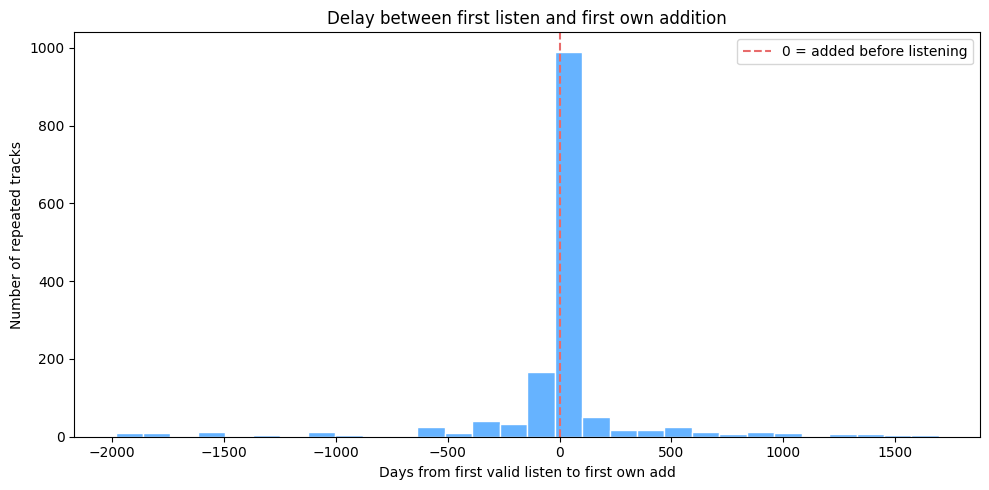

🔍 Share of repeated tracks added to different playlists on the same day: 44.9%

📊 Repeated tracks by curated subgroup:


,Repeated_tracks,Median_playlists,Median_valid_plays
Curated subgroup,,,
few_sessions,633,3.0,1.0
mixed,1193,2.0,7.0
bursty,1208,2.0,6.0
steady,10,3.0,3.0
not_in_curated,321,2.0,0.0


In [107]:
# 7.3 Происхождение и путь повторяющихся треков

# Как повторяющиеся треки попадали в коллекцию:
#   - тип первого плейлиста (mass_import / batch / curated);
#   - задержка между первым прослушиванием и первым добавлением;
#   - сколько плейлистов и за сколько дней они попали;
#   - связь с подгруппами curated.

print('ℹ️ Analyzing repeated tracks (in 2+ playlists) from personal/collaborative.\n')

# Пересоздаём own_links с датами
if 'own_links' not in globals():
    own_links = playlist_links[
        playlist_links['playlist_type'].isin(['personal', 'collaborative'])
    ].copy()
    own_links['Added At'] = pd.to_datetime(own_links['Added At'], errors='coerce').dt.tz_localize(None)

# Первое валидное прослушивание и число валидных прослушиваний
valid = df_events[df_events['valid_play']].copy()
valid['ts'] = pd.to_datetime(valid['ts'], errors='coerce').dt.tz_localize(None)
first_valid_seen = valid.groupby('spotify_track_uri')['ts'].min().reset_index()
first_valid_seen.columns = ['Track URI', 'first_valid_seen']
valid_count = valid.groupby('spotify_track_uri').size().reset_index(name='valid_play_count')
valid_count.columns = ['Track URI', 'valid_play_count']

# Тип наполнения
own_links = own_links.merge(
    fill_df[['name_norm', 'fill_type']], on='name_norm', how='left'
)

# Повторяющиеся треки
repeated_uris = track_playlist_count[
    track_playlist_count['is_repeated']
]['Track URI'].unique()

rep_links = own_links[own_links['Track URI'].isin(repeated_uris)].copy()
rep_links = rep_links.sort_values('Added At')

# Первое добавление трека
first_add = rep_links.groupby('Track URI').agg(
    first_add_date=('Added At', 'min'),
    first_own_type=('fill_type', 'first'),
    n_add_events=('Added At', 'size'),
    n_add_days=('Added At', lambda x: x.dt.date.nunique()),
    n_playlists=('name_norm', 'nunique')
).reset_index()

first_add = first_add.merge(first_valid_seen, on='Track URI', how='left')
first_add = first_add.merge(valid_count, on='Track URI', how='left')

first_add['listened_before_add'] = first_add['first_valid_seen'] < first_add['first_add_date']
first_add['days_from_listen_to_add'] = (
    first_add['first_add_date'] - first_add['first_valid_seen']
).dt.days
first_add['valid_play_count'] = first_add['valid_play_count'].fillna(0).astype(int)


# ==========================================
# Сводка по типу первого появления
# ==========================================
first_type_summary = first_add.groupby('first_own_type').agg(
    Repeated_tracks=('Track URI', 'size'),
    Median_playlists=('n_playlists', 'median'),
    Median_add_days=('n_add_days', 'median'),
    Share_listened_before=('listened_before_add', 'mean'),
    Median_days_from_listen=('days_from_listen_to_add', 'median'),
    Median_valid_plays=('valid_play_count', 'median')
).reindex(['mass_import', 'batch', 'curated']).round(2)

first_type_summary.index.name = 'First playlist type'
print('📊 Repeated tracks by first playlist type:')
display(first_type_summary)


# ==========================================
# Гистограмма задержки
# ==========================================
plt.figure(figsize=(10, 5))
plt.hist(
    first_add['days_from_listen_to_add'].dropna(),
    bins=30, color=COLORS['primary'], edgecolor='white'
)
plt.axvline(x=0, color=COLORS['line_accent'], linestyle='--',
            label='0 = added before listening')
plt.xlabel('Days from first valid listen to first own add')
plt.ylabel('Number of repeated tracks')
plt.title('Delay between first listen and first own addition')
plt.legend()
plt.tight_layout()
plt.show()

# Доля добавленных в разные плейлисты в один день
same_day_add = (first_add['n_add_days'] == 1).mean() * 100
print(f'🔍 Share of repeated tracks added to different playlists on the same day: '
      f'{same_day_add:.1f}%')


# ==========================================
# Связь с подгруппами curated
# ==========================================
curated_presence = own_links[own_links['fill_type'] == 'curated'].merge(
    fill_df[['name_norm', 'subgroup']], on='name_norm', how='left'
)
curated_presence = curated_presence[['Track URI', 'subgroup']].drop_duplicates()
first_add = first_add.merge(curated_presence, on='Track URI', how='left')
first_add['curated_subgroup'] = first_add['subgroup'].fillna('not_in_curated')
first_add.drop(columns=['subgroup'], inplace=True)

subgroup_repeat_summary = first_add.groupby('curated_subgroup').agg(
    Repeated_tracks=('Track URI', 'size'),
    Median_playlists=('n_playlists', 'median'),
    Median_valid_plays=('valid_play_count', 'median')
).reindex(['few_sessions', 'mixed', 'bursty', 'steady', 'not_in_curated']).round(1)
subgroup_repeat_summary.index.name = 'Curated subgroup'

print('\n📊 Repeated tracks by curated subgroup:')
display(subgroup_repeat_summary)

### 7.3. Вывод

**Что смотрели.** Как повторяющиеся треки попадали в коллекцию: в каком типе плейлиста появлялись впервые, с какой задержкой между первым прослушиванием и первым добавлением, в скольких плейлистах осели.

**Результат.** 44.9% повторов добавлены в разные плейлисты в один день. Гистограмма задержки имеет пик на нуле и длинные хвосты в обе стороны: от −2000 до +1500 дней.

По типу первого появления картина расходится. Треки, впервые попавшие в **mass_import** (313) или **batch** (453): прослушано до добавления 0% и 1%, медиана задержки −332 и −263 дня, медиана валидных прослушиваний 0. Треки, впервые попавшие в **curated** (1444): прослушано до добавления 33%, медиана задержки −1 день, медиана валидных прослушиваний 6.

По подгруппам **curated**: у **mixed** и **bursty** медиана 7 и 6 прослушиваний, у **few_sessions** — 1. У треков вне **curated** — 0.

**Вывод.** Повторы делятся на два типа. Первый — механический: трек попал в массовый импорт или пакетное копирование, не слушался, потом оказался в нескольких плейлистах по инерции. Второй — осознанный: трек добавлен через **curated**, часто после прослушивания, возвращается многократно. Медиана 6–7 прослушиваний у **curated**-повторов против 0 у остальных показывает, что это разные объекты, а не разные степени одного.

**Ограничения.** В разбивке по подгруппам **curated** трек может попасть в несколько подгрупп одновременно. Сумма по подгруппам (3044) превышает общее число **curated**-повторов (1444), поэтому подгрупповые числа — это вхождения, не уникальные треки.

Медиана задержки отрицательная, потому что задержка считается как «добавление минус прослушивание». Отрицательное значение означает, что трек добавили до первого валидного прослушивания.

## Блок 7. Вывод

**Типы наполнения не пересекаются.** Jaccard между **mass_import**, **batch** и **curated** ниже 0.1 у всех пар. Даже самая близкая — **batch** и **curated** — совпадает на 7%. Три стратегии втягивают в коллекцию разную музыку, а не одну и ту же. Значит, классификация по способу наполнения отражает содержательное различие.

**Одна ось на трёх уровнях.** Разделение, которое видно в блоке 2 между **personal** и **foreign**, повторяется ещё дважды. По способу наполнения — **mass_import** против **curated**. По повторяемости — уникальные против повторяющихся. Везде одно и то же: нишевое, инструментальное, энергичное против популярного, акустичного, тихого.

**Два механизма повтора.** Тип первого появления различает повторы. Через **mass_import** и **batch** трек попадает в несколько плейлистов механически, не будучи прослушанным: медиана валидных прослушиваний 0. Через **curated** — после прослушивания, с возвратом: медиана 6–7. Это разные объекты, а не разные степени одного.

**Механическое большинство.** 44.9% повторов добавлены в разные плейлисты в один день. Такие повторы не несут смысла «любимого трека» — они побочный продукт копирования.

**Связка с блоком 8.** Блок 7 показал, что структура коллекции неоднородна на нескольких уровнях одновременно. Дальше — вопрос о свойствах плейлистов как целых. Блок 8 считает эпоху, разнообразие и вовлечённость для всех четырёх типов и проверяет, отличаются ли свои плейлисты от чужих по этим характеристикам.

# Блок 8. Характеристики плейлистов


## Блок 8. Характеристики плейлистов

Блок считает для всех плейлистов эпоху, разнообразие и вовлечённость. Сравнивает **own** и **foreign**. Даёт список плейлистов для выбора. Строит автопортрет выбранного плейлиста.

Срез — **playlist_links**, **tracks_exportify**, **df_events**. Единица анализа — плейлист.

**Эпоха** — возрастная характеристика плейлиста по годам релиза треков.

- **mode_release_year** — мода года релиза среди треков плейлиста.
- **decade_2020s / decade_2010s / decade_2000s / decade_pre_2000** — доли треков, у которых год релиза попадает в соответствующее десятилетие. Сумма по четырём — 1.

**Разнообразие** — сколько жанров и артистов приходится на трек.

- **genre_diversity** — `unique_genres / total_tracks`. Число уникальных жанров, поделённое на число треков.
- **artist_diversity** — `unique_artists / total_tracks`. То же по артистам.

**Вовлечённость** — три метрики по событиям плейлиста.

- **skip_rate** — доля скипов от всех событий по трекам плейлиста. Считается по **df_events** без фильтра **valid_play**.
- **median_played_frac** — медиана `played_frac` среди **valid_play** событий.
- **full_play_share** — доля **valid_play** событий с `played_frac` ≥ 0.9.

**own / foreign** — слияние четырёх типов в две группы. **Own** = **personal** + **collaborative**. **Foreign** = **foreign** + **contributed**. Это не «свой вкус» и «чужой вкус». **Own** — плейлисты, которые пользователь собрал сам. **Foreign** — чужие плейлисты, которые пользователь отобрал и добавил в коллекцию. Обе группы отражают его отбор, но разными способами: в **own** он выбирает треки, в **foreign** — целые плейлисты.

**GLOBAL_SPOTIFY_BASELINE** — приблизительный глобальный профиль Spotify, с которым сравнивается плейлист в 8.3. Значения — популярность 42, valence 0.45, energy 0.62, danceability 0.57, acousticness 0.28, instrumentalness 0.10, tempo 121. Это ориентир, не выгруженная статистика.

**Similarity к своему вкусу** — доля признаков из семи (**valence**, **energy**, **danceability**, **acousticness**, **instrumentalness**, **popularity**, **tempo**), у которых медиана плейлиста отличается от медианы всех собственных плейлистов меньше чем на порог практической значимости из блока 3.

**Euclidean distance к своему вкусу** — нормированное расстояние между медианами плейлиста и медианами всех собственных плейлистов.

1. Обзор характеристик.
2. Свои против чужих.
3. Список плейлистов для выбора.
4. Автопортрет выбранного плейлиста.

## 8.1 Характеристики плейлистов: обзор


In [108]:
# 8.1 Характеристики плейлистов: обзор

# Для всех плейлистов (все четыре типа) считаем:
#   - эпоху: мода года релиза и доли десятилетий;
#   - разнообразие: уникальные жанры и артисты на трек;
#   - вовлечённость: skip rate, median played_frac, full_play_share.

print('ℹ️ Analyzing all playlists (personal, collaborative, contributed, foreign).\n')

# Все плейлисты
all_links = playlist_links.copy()
all_links['Added At'] = pd.to_datetime(all_links['Added At'], errors='coerce').dt.tz_localize(None)
all_names = all_links['name_norm'].unique()

# ==========================================
# 1. Эпоха
# ==========================================
pl_tracks = all_links[['name_norm', 'Track URI']].drop_duplicates()
pl_tracks = pl_tracks.merge(
    tracks_exportify[['spotify_track_uri', 'release_date', 'artist_name', 'genres_normalized']],
    left_on='Track URI', right_on='spotify_track_uri', how='left'
)
pl_tracks['release_year'] = pd.to_datetime(pl_tracks['release_date'], errors='coerce').dt.year
pl_tracks['decade'] = (pl_tracks['release_year'] // 10 * 10).astype('Int64')


def mode_year(years):
    valid = years.dropna().astype(int)
    if valid.empty:
        return np.nan
    return valid.mode().iloc[0] if not valid.mode().empty else np.nan


epoch_rows = []
for name, group in pl_tracks.groupby('name_norm'):
    epoch_rows.append({
        'name_norm': name,
        'mode_release_year': mode_year(group['release_year']),
        'decade_2020s': (group['decade'] == 2020).mean(),
        'decade_2010s': (group['decade'] == 2010).mean(),
        'decade_2000s': (group['decade'] == 2000).mean(),
        'decade_pre_2000': (group['decade'] < 2000).mean(),
    })
epoch_df = pd.DataFrame(epoch_rows)


# ==========================================
# 2. Разнообразие
# ==========================================
def count_genres(series):
    genres = series.dropna().str.split(',').explode().str.strip()
    genres = genres[genres != 'unknown']
    return genres.nunique()


diversity_rows = []
for name, group in pl_tracks.groupby('name_norm'):
    total_tracks = len(group)
    unique_genres = count_genres(group['genres_normalized'])
    unique_artists = group['artist_name'].nunique()
    diversity_rows.append({
        'name_norm': name,
        'total_tracks': total_tracks,
        'unique_genres': unique_genres,
        'unique_artists': unique_artists,
        'genre_diversity': unique_genres / total_tracks if total_tracks > 0 else 0,
        'artist_diversity': unique_artists / total_tracks if total_tracks > 0 else 0,
    })
diversity_df = pd.DataFrame(diversity_rows)


# ==========================================
# 3. Skip rate и полнота прослушивания
# ==========================================
all_events = df_events.copy()
all_events['ts'] = pd.to_datetime(all_events['ts'], errors='coerce').dt.tz_localize(None)

events_with_pl = all_events.merge(
    all_links[['name_norm', 'Track URI']].drop_duplicates(),
    left_on='spotify_track_uri', right_on='Track URI', how='inner'
)

skip_rows = []
for name, group in events_with_pl.groupby('name_norm'):
    total_events = len(group)
    skips = group['is_skip'].sum()
    skip_rate = skips / total_events if total_events > 0 else np.nan
    median_played_frac = group['played_frac'].median() if len(group) > 0 else np.nan
    full_play_share = (group['played_frac'] >= 0.9).mean() if len(group) > 0 else np.nan
    skip_rows.append({
        'name_norm': name,
        'skip_rate': skip_rate,
        'median_played_frac': median_played_frac,
        'full_play_share': full_play_share,
    })
skip_df = pd.DataFrame(skip_rows)


# ==========================================
# Объединяем
# ==========================================
playlist_profiles = epoch_df.merge(diversity_df, on='name_norm', how='left')
playlist_profiles = playlist_profiles.merge(skip_df, on='name_norm', how='left')
playlist_profiles = playlist_profiles[playlist_profiles['name_norm'].isin(all_names)]

playlist_profiles = playlist_profiles.merge(
    all_links[['name_norm', 'playlist_type']].drop_duplicates(),
    on='name_norm', how='left'
)

# Описательные статистики
metric_cols = [
    'mode_release_year',
    'decade_2020s', 'decade_2010s', 'decade_2000s', 'decade_pre_2000',
    'genre_diversity', 'artist_diversity',
    'skip_rate', 'median_played_frac', 'full_play_share'
]
overview = playlist_profiles[metric_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
overview = overview[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(3)
overview.columns = ['N', 'Mean', 'Std', 'Min', 'Q1', 'Median', 'Q3', 'Max']

print('📊 Overview of playlist characteristics:')
display(overview)

# Распределение по преобладающему десятилетию
decade_cols = ['decade_2020s', 'decade_2010s', 'decade_2000s', 'decade_pre_2000']
dominant_decade = playlist_profiles[decade_cols].idxmax(axis=1).str.replace('decade_', '')
dominant_counts = (
    dominant_decade.value_counts()
    .reindex(['2020s', '2010s', '2000s', 'pre_2000'])
    .fillna(0)
    .astype(int)
)
dominant_pct = (dominant_counts / len(playlist_profiles) * 100).round(1)
dominant_df = pd.DataFrame({
    'Decade': dominant_counts.index,
    'Playlists': dominant_counts.values,
    'Share (%)': dominant_pct.values
})
dominant_df.index = range(1, len(dominant_df) + 1)
dominant_df.index.name = '№'

print('\n📊 Playlists by dominant decade:')
display(dominant_df)

ℹ️ Analyzing all playlists (personal, collaborative, contributed, foreign).

📊 Overview of playlist characteristics:


,N,Mean,Std,Min,Q1,Median,Q3,Max
mode_release_year,296.0,2018.632,7.090,1975.000,2017.000,2020.000,2024.000,2026.000
decade_2020s,296.0,0.437,0.367,0.000,0.038,0.450,0.739,1.000
decade_2010s,296.0,0.414,0.298,0.000,0.193,0.368,0.631,1.000
decade_2000s,296.0,0.094,0.145,0.000,0.000,0.038,0.126,1.000
decade_pre_2000,296.0,0.055,0.109,0.000,0.000,0.000,0.053,0.532
genre_diversity,296.0,0.546,0.407,0.000,0.292,0.460,0.731,2.667
artist_diversity,296.0,0.796,0.183,0.042,0.709,0.833,0.923,1.000
skip_rate,273.0,0.401,0.218,0.000,0.250,0.359,0.500,1.000
median_played_frac,273.0,0.692,0.415,0.000,0.207,0.999,1.000,1.000
full_play_share,273.0,0.513,0.229,0.000,0.405,0.567,0.667,1.000



📊 Playlists by dominant decade:


,Decade,Playlists,Share (%)
№,,,
1,2020s,150,50.7
2,2010s,121,40.9
3,2000s,15,5.1
4,pre_2000,10,3.4


### 8.1. Вывод

**Что смотрели.** Для всех 296 плейлистов — эпоха (мода года релиза, доли десятилетий), разнообразие (уникальные жанры и артисты на трек), вовлечённость (skip rate, медиана `played_frac`, доля полных прослушиваний).

**Результат.** Эпоха. Медиана моды года релиза — 2020, диапазон от 1975 до 2026. Доминирующее десятилетие: 2020-е у 150 плейлистов (50.7%), 2010-е у 121 (40.9%). Вместе — 91.6%.

Разнообразие. Медиана `genre_diversity` — 0.460: меньше одного уникального жанра на два трека. Медиана `artist_diversity` — 0.833: почти у каждого трека свой артист. Жанрово плейлисты плотные, артистически широкие.

Вовлечённость. Медиана `skip_rate` — 0.359. Медиана `full_play_share` — 0.567: чуть больше половины событий дослушиваются до конца. `median_played_frac` — 0.999 в медиане, но Q1 = 0.207: у четверти плейлистов медианная доля прослушивания около 0.2, у половины — почти 1.0. Распределение бимодальное.

**Вывод.** Коллекция современная: девять из десяти плейлистов принадлежат 2020-м или 2010-м. Плейлисты жанрово плотные, но артистически широкие. По вовлечённости коллекция делится на две части: плейлисты, которые дослушиваются, и плейлисты, которые в основном скипаются. Между ними почти нет середины.

**Ограничения.** `skip_rate`, `median_played_frac` и `full_play_share` посчитаны для 273 плейлистов из 296. У 23 нет событий в **df_events**, метрики для них отсутствуют. Это преимущественно заброшенные плейлисты.

`genre_diversity` выше 1 — норма: у одного трека может быть несколько жанров. Максимум 2.667 означает, что в самом жанрово широком плейлисте на каждый трек приходится больше двух с половиной уникальных жанровых тегов.

## 8.2 Свои vs чужие: сравнение по характеристикам


In [109]:
# 8.2 Свои vs чужие: сравнение по характеристикам

# Свои = personal + collaborative.
# Чужие = foreign + contributed.
#
# Mann-Whitney U + пороги практической существенности.
# Метрики: эпоха, разнообразие, skip rate, полнота прослушивания.

print('ℹ️ Own: personal + collaborative. Foreign: foreign + contributed.\n')

playlist_profiles['ownership'] = playlist_profiles['playlist_type'].apply(
    lambda x: 'own' if x in ['personal', 'collaborative'] else 'foreign'
)

metrics = [
    'mode_release_year',
    'decade_2020s', 'decade_2010s', 'decade_2000s', 'decade_pre_2000',
    'genre_diversity', 'artist_diversity',
    'skip_rate', 'median_played_frac', 'full_play_share'
]

own = playlist_profiles[playlist_profiles['ownership'] == 'own']
foreign = playlist_profiles[playlist_profiles['ownership'] == 'foreign']

rows = []
for metric in metrics:
    a = own[metric].dropna()
    b = foreign[metric].dropna()
    if len(a) < 5 or len(b) < 5:
        rows.append({
            'Metric': metric,
            'Own median': np.nan,
            'Foreign median': np.nan,
            'p-value': np.nan,
            'Verdict': 'insufficient data'
        })
        continue

    med_own = a.median()
    med_foreign = b.median()
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    mean_diff = a.mean() - b.mean()

    if metric == 'mode_release_year':
        thresh = 2  # years
    else:
        thresh = 0.05

    if p < 0.05 and abs(mean_diff) >= thresh:
        verdict = '✅'
    elif p < 0.05:
        verdict = '⚠️'
    else:
        verdict = '—'

    rows.append({
        'Metric': metric,
        'Own median': med_own,
        'Foreign median': med_foreign,
        'p-value': p,
        'Verdict': verdict
    })

comparison = pd.DataFrame(rows)
comparison.index = range(1, len(comparison) + 1)
comparison.index.name = '№'

print('📊 Own vs foreign playlists by characteristics:')
display(comparison.round(3))

# Автоматический вывод
print('\n🔍 Conclusion:')
for _, row in comparison.iterrows():
    if row['Verdict'] == '✅':
        direction = 'higher in own' if row['Own median'] > row['Foreign median'] else 'higher in foreign'
        print(f"✅ {row['Metric']}: {direction} "
              f"(medians: {row['Own median']} vs {row['Foreign median']})")
    elif row['Verdict'] == '⚠️':
        print(f"⚠️ {row['Metric']}: significant, but below threshold")
    else:
        print(f"— {row['Metric']}: not significant")


# ==========================================
# 8.2b Список плейлистов для выбора (со скроллом)
# ==========================================
# Все плейлисты с ключевыми атрибутами — удобно выбрать для 8.3.

all_playlists = playlist_links[['name_norm', 'playlist_name', 'playlist_type']].drop_duplicates()

# Число уникальных треков
track_counts = (
    playlist_links.groupby('name_norm')['Track URI'].nunique()
    .reset_index(name='num_tracks')
)
all_playlists = all_playlists.merge(track_counts, on='name_norm', how='left')

# Тип наполнения (для personal/collaborative)
fill_map = fill_df[['name_norm', 'fill_type']].drop_duplicates()
all_playlists = all_playlists.merge(fill_map, on='name_norm', how='left')
all_playlists['fill_type'] = all_playlists['fill_type'].fillna('foreign/contributed')

# Активность
activity_map = pl_activity[['name_norm', 'total_listens', 'days_since_update', 'group']]
all_playlists = all_playlists.merge(activity_map, on='name_norm', how='left')
all_playlists = all_playlists.sort_values('total_listens', ascending=False)

display_cols = ['playlist_name', 'playlist_type', 'fill_type', 'num_tracks',
                'total_listens', 'days_since_update', 'group']
display_df = all_playlists[display_cols].copy()
display_df.columns = ['Playlist', 'Type', 'Fill type', 'Tracks',
                      'Total listens', 'Days since update', 'Activity group']
display_df = display_df.reset_index(drop=True)
display_df.index = display_df.index + 1
display_df.index.name = '№'

html = display_df.to_html()
display(HTML(f'<div style="max-height:400px; overflow-y:auto;">{html}</div>'))

ℹ️ Own: personal + collaborative. Foreign: foreign + contributed.

📊 Own vs foreign playlists by characteristics:


,Metric,Own median,Foreign median,p-value,Verdict
№,,,,,
1,mode_release_year,2019.000,2021.000,0.001,⚠️
2,decade_2020s,0.289,0.598,0.000,✅
3,decade_2010s,0.432,0.294,0.000,✅
4,decade_2000s,0.058,0.014,0.004,⚠️
5,decade_pre_2000,0.000,0.000,0.589,—
6,genre_diversity,0.528,0.351,0.000,✅
7,artist_diversity,0.857,0.820,0.117,—
8,skip_rate,0.359,0.357,0.242,—
9,median_played_frac,0.999,0.999,0.925,—



🔍 Conclusion:
⚠️ mode_release_year: significant, but below threshold
✅ decade_2020s: higher in foreign (medians: 0.2894736842105263 vs 0.5980611483967189)
✅ decade_2010s: higher in own (medians: 0.43157894736842106 vs 0.29411764705882354)
⚠️ decade_2000s: significant, but below threshold
— decade_pre_2000: not significant
✅ genre_diversity: higher in own (medians: 0.5277777777777778 vs 0.3507246376811594)
— artist_diversity: not significant
— skip_rate: not significant
— median_played_frac: not significant
— full_play_share: not significant


,Playlist,Type,Fill type,Tracks,Total listens,Days since update,Activity group
№,,,,,,,
1,2025,collaborative,curated,576,6611.0,172.0,active_listened
2,Ringleader,collaborative,curated,228,3469.0,0.0,active_listened
3,🌊🌊🌊Waves,collaborative,curated,358,3206.0,57.0,active_listened
4,personal_personal_01,collaborative,curated,101,2225.0,971.0,abandoned_but_listened
5,personal_identity_03,collaborative,curated,137,1934.0,0.0,active_listened
6,Soulful_mood,collaborative,curated,184,1867.0,65.0,active_listened
7,2024,personal,curated,290,1822.0,329.0,active_listened
8,New_2023,collaborative,curated,201,1698.0,490.0,abandoned_but_listened
9,2026,collaborative,curated,276,1633.0,0.0,active_listened


### 8.2. Вывод

**Что смотрели.** Чем **own** (**personal** + **collaborative**) отличается от **foreign** (**foreign** + **contributed**) по эпохе, разнообразию и вовлечённости.

**Результат.** По эпохе различие есть. У **own** медиана доли 2010-х — 0.432, у **foreign** — 0.294. По 2020-м наоборот: 0.289 у **own** против 0.598 у **foreign**. Мода года релиза: 2019 у **own** против 2021 у **foreign**, но различие ниже порога практической существенности.

По разнообразию. `genre_diversity` выше у **own**: 0.528 против 0.351. `artist_diversity` не различается.

По вовлечённости различий нет ни по одной метрике: `skip_rate` (0.359 против 0.357), `median_played_frac` (0.999 у обоих), `full_play_share` (0.551 против 0.576). Все три p > 0.2.

**Вывод.** **Own** и **foreign** различаются содержанием, но не поведением. **Own** жанрово разнообразнее и старее, **foreign** плотнее и свежее. Пользователь отбирал **foreign** из более современной музыки, а **own** собирал из более широкого жанрового поля и более старых треков. По тому, как эти плейлисты слушаются, группы не отличаются ни по скипам, ни по полноте прослушивания.

**Ограничения.** Метрики вовлечённости посчитаны для 273 плейлистов из 296. У 23 нет событий в **df_events** — это преимущественно заброшенные плейлисты. Вовлечённость описывает не всю коллекцию, а ту часть, которая хоть как-то слушалась.

**Foreign** — это **foreign** + **contributed**, но **contributed** в данных один плейлист. Практически **foreign** — это **foreign**.

## 8.3 Автопортрет выбранного плейлиста


### Параметр выбора плейлиста

Блок использует ту же переменную `selected_playlist`, что и 4.2.
Значение задаётся в начале ячейки 8.3 — по умолчанию `'2025'`.

Чтобы разобрать другой плейлист — замени `selected_playlist`
в первой строке ячейки. Если запускаешь 8.3 отдельно, без 4.2,
значение всё равно нужно указать здесь.

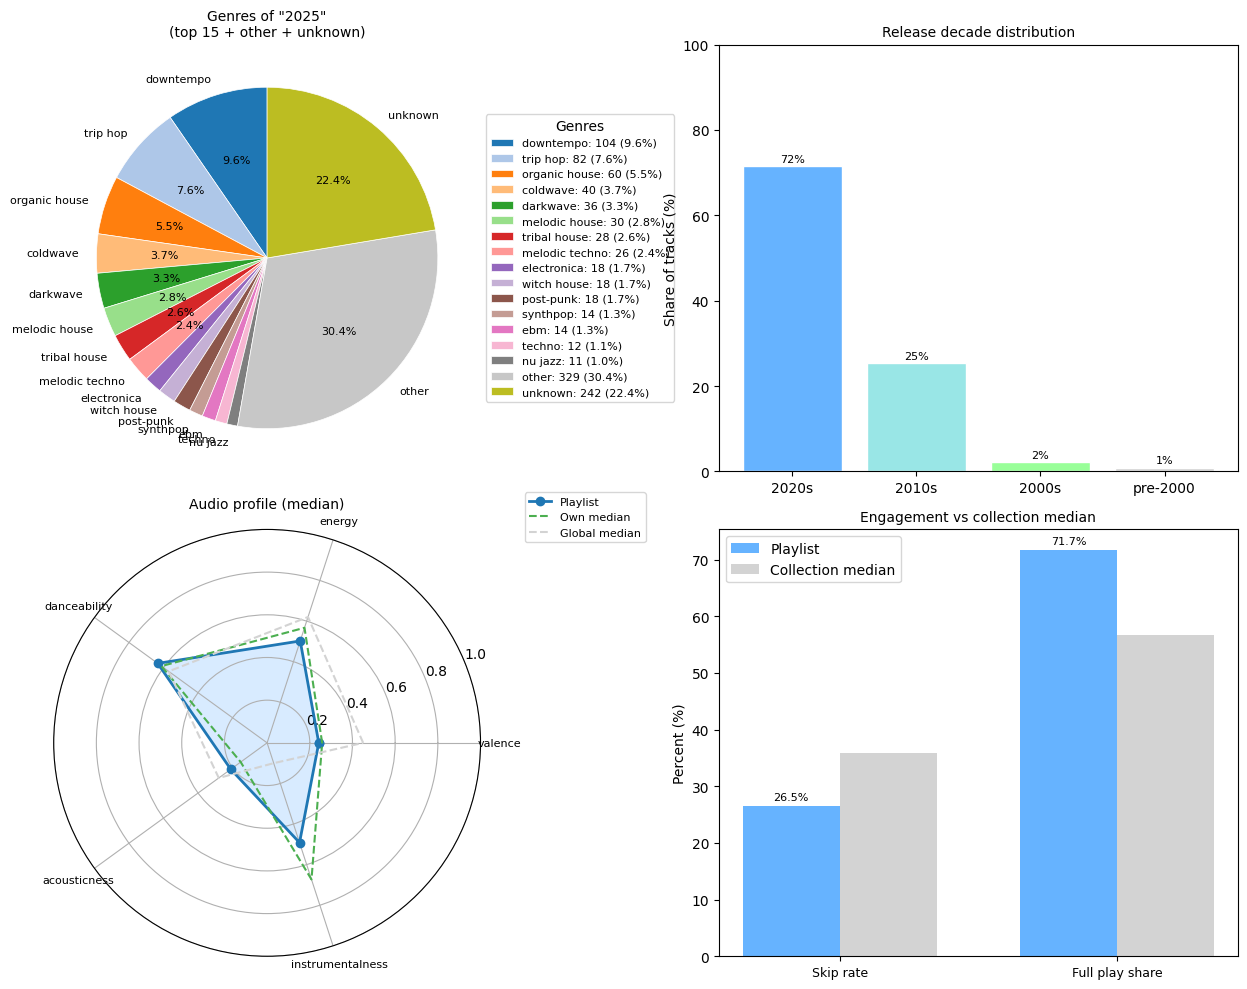


📊 Playlist portrait: 2025
   Type: collaborative | Fill: curated | Tracks: 576
   Created: 2024-12-24
   Listened tracks: 563 of 576 (98%)
   Listens: 6611 | Days since update: 172 | Group: active_listened

🎧 Audio features (median):
   valence 0.242, energy 0.502, danceability 0.633
   acousticness 0.210, instrumentalness 0.491
   popularity 29.0, tempo 120.0 BPM

🎵 Top genres: downtempo, trip hop, organic house, coldwave, darkwave, melodic house, tribal house, melodic techno, electronica, witch house

📅 Era: mode year 2025
   Decade shares: 2020s 72%, 2010s 25%, 2000s 2%, pre-2000 1%
   Engagement: skip rate 26.5%, full play 71.7%

📊 Diversity: genres 148, artists 437; genres per track 0.26, artists per track 0.76
   ➜ Playlist is genre-homogeneous.

🎵 Internal homogeneity:


,Feature,IQR,CV,Dispersion
№,,,,
1,valence,0.28,0.71,— medium
2,energy,0.27,0.36,— medium
3,danceability,0.19,0.24,🔻 low
4,acousticness,0.50,0.97,🔺 high
5,instrumentalness,0.75,0.79,🔺 high


   Mean IQR: 0.40, CV: 0.62
   ➜ Noticeable contrast between tracks.

🎯 Closeness to your taste:
   Similarity: 29%
   Euclidean distance: 1.513
   ➜ Playlist stands out from your typical music.

🌍 Comparison with global Spotify:


,Feature,Playlist,Global,Deviation
№,,,,
1,valence,0.24,0.45,🔻 lower
2,energy,0.50,0.62,🔻 lower
3,danceability,0.63,0.57,🔺 higher
4,acousticness,0.21,0.28,🔻 lower
5,instrumentalness,0.49,0.10,🔺 higher
6,popularity,29.0,42.0,🔻 lower
7,tempo,120.0,121.0,—



📆 Listening history by year:


,Year,Unique tracks,"Share of playlist, %",Total listens
№,,,,
1,2020,4,0.7,4
2,2021,13,2.3,34
3,2022,20,3.5,60
4,2023,36,6.2,121
5,2024,33,5.7,58
6,2025,561,97.4,5387
7,2026,200,34.7,947



🔍 Interpretation:
  Consciously curated playlist.
  Actively listened; likely part of the current core.
  Underground (popularity below 30).

📊 Tracks first listened before playlist creation: 73 of 576 (13%)


In [110]:
# 8.3 Автопортрет выбранного плейлиста

# Многомерный портрет одного плейлиста:
#   - графики 2×2: жанры (пирог), десятилетия, аудио-радар, вовлечённость;
#   - текстовый портрет: медианы, топ-жанры, эпоха, разнообразие,
#     однородность, близость к своему вкусу и к глобальному Spotify,
#     история прослушивания по годам.
#
# Параметр selected_playlist = '2025' — указываешь name_norm.

# ============================================================
# Параметр: какой плейлист разобрать детально.
# ============================================================
selected_playlist = '2025'

# --- Глобальный бенчмарк Spotify (приблизительный) ---
GLOBAL_SPOTIFY_BASELINE = {
    'popularity': 42,
    'valence': 0.45,
    'energy': 0.62,
    'danceability': 0.57,
    'acousticness': 0.28,
    'instrumentalness': 0.10,
    'tempo': 121,
}

if selected_playlist is None:
    print('💡 Set selected_playlist = "name" (name_norm).')
else:
    target = normalize_name(selected_playlist)
    pl_info = playlist_links[playlist_links['name_norm'] == target]

    if pl_info.empty:
        print(f'Playlist "{selected_playlist}" not found.')
    else:
        uris = pl_info['Track URI'].unique()

        # Дата создания = минимальная дата добавления
        creation_date = (
            playlist_links.loc[playlist_links['name_norm'] == target, 'Added At']
            .min()
        )
        creation_date = pd.to_datetime(creation_date, errors='coerce').tz_localize(None)

        track_meta = tracks_exportify[
            tracks_exportify['spotify_track_uri'].isin(uris)
        ]
        n_tracks = len(track_meta)

        ptype = pl_info['playlist_type'].iloc[0]
        fill_type_val = fill_df.loc[fill_df['name_norm'] == target, 'fill_type']
        fill_type_val = fill_type_val.iloc[0] if not fill_type_val.empty else '—'

        # Активность
        if target in pl_activity['name_norm'].values:
            act_row = pl_activity[pl_activity['name_norm'] == target].iloc[0]
            total_listens = act_row['total_listens']
            days_since_update = act_row['days_since_update']
            group_val = act_row['group']
        else:
            total_listens = days_since_update = None
            group_val = '—'

        audio_med = {
            f: track_meta[f].dropna().median()
            for f in ['valence', 'energy', 'danceability', 'acousticness',
                      'instrumentalness', 'popularity', 'tempo']
        }

        prof = playlist_profiles[playlist_profiles['name_norm'] == target]
        prof = prof.iloc[0] if not prof.empty else None

        # ============================================================
        # ГРАФИКИ 2×2
        # ============================================================
        fig = plt.figure(figsize=(14, 10))

        # --- 1. Жанры (пирог) ---
        ax1 = fig.add_subplot(2, 2, 1)
        genres_series = (
            track_meta['genres_normalized']
            .dropna().str.split(',').explode().str.strip()
        )
        genres_clean = genres_series[~genres_series.isin(['unknown'])]
        unknown_count = genres_series[genres_series.eq('unknown')].size
        top_genres = genres_clean.value_counts().head(15)
        other_count = genres_clean[~genres_clean.isin(top_genres.index)].size

        genre_data = top_genres.copy()
        if other_count > 0:
            genre_data['other'] = other_count
        if unknown_count > 0:
            genre_data['unknown'] = unknown_count

        colors_pie = plt.cm.tab20.colors[:len(genre_data)]
        wedges, texts, autotexts = ax1.pie(
            genre_data.values,
            labels=genre_data.index,
            autopct=lambda p: f'{p:.1f}%' if p >= 2 else '',
            startangle=90,
            colors=colors_pie,
            textprops={'fontsize': 8},
            wedgeprops=dict(edgecolor='white', linewidth=0.5),
        )
        ax1.set_title(
            f'Genres of "{pl_info["playlist_name"].iloc[0]}"\n(top 15 + other + unknown)',
            fontsize=10
        )
        ax1.legend(
            wedges,
            [f'{g}: {v} ({v/genres_series.size*100:.1f}%)' for g, v in genre_data.items()],
            title='Genres',
            loc='center left',
            bbox_to_anchor=(1, 0, 0.5, 1),
            fontsize=8
        )

        # --- 2. Десятилетия (bar) ---
        ax2 = fig.add_subplot(2, 2, 2)
        if prof is not None:
            decade_vals = [
                prof['decade_2020s'] * 100,
                prof['decade_2010s'] * 100,
                prof['decade_2000s'] * 100,
                prof['decade_pre_2000'] * 100,
            ]
            decade_labels = ['2020s', '2010s', '2000s', 'pre-2000']
            bars = ax2.bar(
                decade_labels, decade_vals,
                color=[COLORS['primary'], COLORS['secondary'],
                       COLORS['success'], COLORS['muted']],
                edgecolor='white'
            )
            ax2.set_title('Release decade distribution', fontsize=10)
            ax2.set_ylabel('Share of tracks (%)')
            for bar, val in zip(bars, decade_vals):
                ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                         f'{val:.0f}%', ha='center', fontsize=8)
            ax2.set_ylim(0, 100)
        else:
            ax2.text(0.5, 0.5, 'No era data', ha='center', va='center')
            ax2.axis('off')

        # --- 3. Аудио-радар ---
        ax3 = fig.add_subplot(2, 2, 3, projection='polar')
        radar_features = ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']
        angles = np.linspace(0, 2 * np.pi, len(radar_features), endpoint=False).tolist()
        values = [audio_med[f] for f in radar_features]
        values += values[:1]
        angles += angles[:1]

        ax3.plot(angles, values, 'o-', linewidth=2, label='Playlist')
        ax3.fill(angles, values, alpha=0.25, color=COLORS['primary'])

        own_uris = set(playlist_links[
            playlist_links['playlist_type'].isin(['personal', 'collaborative'])
        ]['Track URI'])
        own_tracks = tracks_exportify[tracks_exportify['spotify_track_uri'].isin(own_uris)]
        own_med = own_tracks[radar_features].median()
        own_values = [own_med[f] for f in radar_features] + [own_med[radar_features[0]]]
        glob_values = [GLOBAL_SPOTIFY_BASELINE[f] for f in radar_features] + [GLOBAL_SPOTIFY_BASELINE[radar_features[0]]]

        ax3.plot(angles, own_values, '--', linewidth=1.5, label='Own median',
                 color=COLORS['line_success'])
        ax3.plot(angles, glob_values, '--', linewidth=1.5, label='Global median',
                 color=COLORS['muted'])
        ax3.set_xticks(angles[:-1])
        ax3.set_xticklabels(radar_features, fontsize=8)
        ax3.set_ylim(0, 1)
        ax3.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1), fontsize=8)
        ax3.set_title('Audio profile (median)', fontsize=10)

        # --- 4. Вовлечённость (bar) ---
        ax4 = fig.add_subplot(2, 2, 4)
        if prof is not None:
            metrics_eng = ['skip_rate', 'full_play_share']
            labels_eng = ['Skip rate', 'Full play share']
            values_playlist = [prof['skip_rate'] * 100, prof['full_play_share'] * 100]
            values_median = [
                playlist_profiles['skip_rate'].median() * 100,
                playlist_profiles['full_play_share'].median() * 100,
            ]
            x = np.arange(len(metrics_eng))
            width = 0.35
            bars1 = ax4.bar(x - width/2, values_playlist, width,
                            label='Playlist', color=COLORS['primary'])
            bars2 = ax4.bar(x + width/2, values_median, width,
                            label='Collection median', color=COLORS['muted'])
            ax4.set_xticks(x)
            ax4.set_xticklabels(labels_eng, fontsize=9)
            ax4.set_ylabel('Percent (%)')
            ax4.set_title('Engagement vs collection median', fontsize=10)
            ax4.legend()
            for bar in bars1:
                ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                         f'{bar.get_height():.1f}%', ha='center', fontsize=8)
        else:
            ax4.text(0.5, 0.5, 'No engagement data', ha='center', va='center')
            ax4.axis('off')

        plt.tight_layout(rect=[0, 0, 0.9, 1])
        plt.show()

        # ============================================================
        # ТЕКСТОВЫЙ ПОРТРЕТ
        # ============================================================
        print(f'\n📊 Playlist portrait: {pl_info["playlist_name"].iloc[0]}')
        print(f'   Type: {ptype} | Fill: {fill_type_val} | Tracks: {n_tracks}')

        if pd.notna(creation_date):
            print(f'   Created: {creation_date:%Y-%m-%d}')
        else:
            print('   Created: unknown')

        # Прослушано треков
        valid_uris = set(df_events.loc[df_events['valid_play'], 'spotify_track_uri'].dropna())
        listened_mask = track_meta['spotify_track_uri'].isin(valid_uris)
        n_listened = listened_mask.sum()
        share_listened = n_listened / n_tracks if n_tracks > 0 else 0
        print(f'   Listened tracks: {n_listened} of {n_tracks} ({share_listened:.0%})')

        if total_listens is not None:
            print(f'   Listens: {total_listens} | Days since update: {days_since_update:.0f} | Group: {group_val}')
        else:
            print('   Activity: no data')

        # Аудио
        print('\n🎧 Audio features (median):')
        print(f'   valence {audio_med["valence"]:.3f}, energy {audio_med["energy"]:.3f}, '
              f'danceability {audio_med["danceability"]:.3f}')
        print(f'   acousticness {audio_med["acousticness"]:.3f}, '
              f'instrumentalness {audio_med["instrumentalness"]:.3f}')
        print(f'   popularity {audio_med["popularity"]:.1f}, tempo {audio_med["tempo"]:.1f} BPM')

        # Топ-жанры
        top_genres_str = ', '.join(top_genres.index[:10]) if len(top_genres) > 0 else 'no data'
        print(f'\n🎵 Top genres: {top_genres_str}')

        # Эпоха
        if prof is not None:
            print(f'\n📅 Era: mode year {prof["mode_release_year"]:.0f}')
            print(f'   Decade shares: 2020s {prof["decade_2020s"]*100:.0f}%, '
                  f'2010s {prof["decade_2010s"]*100:.0f}%, '
                  f'2000s {prof["decade_2000s"]*100:.0f}%, '
                  f'pre-2000 {prof["decade_pre_2000"]*100:.0f}%')
            print(f'   Engagement: skip rate {prof["skip_rate"]*100:.1f}%, '
                  f'full play {prof["full_play_share"]*100:.1f}%')

        # Разнообразие
        unique_genres = genres_clean.nunique()
        unique_artists = track_meta['artist_name'].nunique()
        genre_diversity = unique_genres / n_tracks if n_tracks > 0 else 0
        artist_diversity = unique_artists / n_tracks if n_tracks > 0 else 0
        print(f'\n📊 Diversity: genres {unique_genres}, artists {unique_artists}; '
              f'genres per track {genre_diversity:.2f}, '
              f'artists per track {artist_diversity:.2f}')
        print('   ➜ ' + ('Playlist is genre-diverse.' if genre_diversity > 0.5
                        else 'Playlist is genre-homogeneous.'))

        # Однородность
        homo_feats = ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']
        homo_stats = track_meta[homo_feats].agg(
            ['mean', 'std', 'median', lambda x: x.quantile(0.75) - x.quantile(0.25)]
        )
        homo_stats.index = ['mean', 'std', 'median', 'IQR']
        cv_series = homo_stats.loc['std'] / homo_stats.loc['mean'].abs()


        def dispersion_indicator(iqr, cv):
            if iqr < 0.2 and cv < 0.5:
                return '🔻 low'
            elif iqr < 0.4 and cv < 1.0:
                return '— medium'
            else:
                return '🔺 high'


        homo_display = pd.DataFrame({
            'Feature': homo_feats,
            'IQR': homo_stats.loc['IQR'].round(2).values,
            'CV': cv_series.round(2).values,
        })
        homo_display['Dispersion'] = homo_display.apply(
            lambda row: dispersion_indicator(row['IQR'], row['CV']), axis=1
        )
        homo_display.index = range(1, len(homo_display) + 1)
        homo_display.index.name = '№'

        print('\n🎵 Internal homogeneity:')
        display(homo_display)

        avg_iqr = homo_stats.loc['IQR'].mean()
        avg_cv = cv_series.mean()
        print(f'   Mean IQR: {avg_iqr:.2f}, CV: {avg_cv:.2f}')
        print('   ➜ ' + ('Playlist sounds fairly uniform.' if avg_iqr < 0.3
                        else 'Noticeable contrast between tracks.'))

        # Близость к своему вкусу
        features_all = ['valence', 'energy', 'danceability', 'acousticness',
                        'instrumentalness', 'popularity', 'tempo']
        pl_med = track_meta[features_all].median()
        own_med_all = own_tracks[features_all].median()

        similar_count = sum(
            1 for f in features_all
            if abs(pl_med[f] - own_med_all[f]) < PRACTICAL_THRESHOLDS.get(f, 0.02)
        )
        similarity_pct = similar_count / len(features_all) * 100

        all_playlists_medians = []
        for name, group in playlist_links[
            playlist_links['playlist_type'].isin(['personal', 'collaborative'])
        ].groupby('name_norm'):
            uris_p = group['Track URI'].unique()
            tr = tracks_exportify[tracks_exportify['spotify_track_uri'].isin(uris_p)]
            if len(tr) >= 30:
                all_playlists_medians.append(tr[features_all].median())
        medians_df = pd.DataFrame(all_playlists_medians)
        std_playlist = medians_df[features_all].std(ddof=0).replace(0, 1)
        z_diff = (pl_med - own_med_all) / std_playlist
        distance = (z_diff ** 2).sum() ** 0.5

        print(f'\n🎯 Closeness to your taste:')
        print(f'   Similarity: {similarity_pct:.0f}%')
        print(f'   Euclidean distance: {distance:.3f}')
        print('   ➜ ' + ('Playlist fits your usual profile.' if similarity_pct >= 50
                        else 'Playlist stands out from your typical music.'))

        # Сравнение с глобальным Spotify
        print('\n🌍 Comparison with global Spotify:')
        global_rows = []
        for feat in features_all:
            pl_val = pl_med[feat]
            glob_val = GLOBAL_SPOTIFY_BASELINE[feat]
            diff = pl_val - glob_val
            thresh = PRACTICAL_THRESHOLDS.get(feat, 0.02)
            if abs(diff) >= thresh:
                arrow = '🔺 higher' if diff > 0 else '🔻 lower'
            else:
                arrow = '—'
            fmt = '.1f' if feat in ['popularity', 'tempo'] else '.2f'
            global_rows.append({
                'Feature': feat,
                'Playlist': f'{pl_val:{fmt}}',
                'Global': f'{glob_val:{fmt}}',
                'Deviation': arrow,
            })

        global_df = pd.DataFrame(global_rows)
        global_df.index = range(1, len(global_df) + 1)
        global_df.index.name = '№'
        display(global_df)

        # История прослушивания по годам
        print('\n📆 Listening history by year:')
        pl_events = df_events[
            (df_events['valid_play']) &
            (df_events['spotify_track_uri'].isin(uris))
        ].copy()
        if pl_events.empty:
            print('   No valid plays.')
        else:
            pl_events['year'] = pd.to_datetime(pl_events['ts'], errors='coerce').dt.year
            yearly_unique = (
                pl_events.groupby('year')['spotify_track_uri'].nunique()
                .reset_index(name='unique_listened')
            )
            yearly_unique['share_of_playlist'] = yearly_unique['unique_listened'] / n_tracks * 100
            yearly_total = pl_events.groupby('year').size().reset_index(name='total_listens_year')
            yearly = yearly_unique.merge(yearly_total, on='year', how='left').sort_values('year')
            yearly.columns = ['Year', 'Unique tracks', 'Share of playlist, %', 'Total listens']
            yearly.index = range(1, len(yearly) + 1)
            yearly.index.name = '№'
            display(yearly.round(1))

        # Интерпретация
        print('\n🔍 Interpretation:')
        if fill_type_val == 'curated':
            print('  Consciously curated playlist.')
        elif fill_type_val == 'batch':
            print('  Batch copy, created in one go.')
        elif fill_type_val == 'mass_import':
            print('  Mass import, transferred without prior listening.')

        if ptype == 'foreign':
            print('  Foreign playlist, listened but not owned.')

        if fill_type_val == 'curated' and total_listens is not None and total_listens > 500:
            print('  Actively listened; likely part of the current core.')
        if genre_diversity > 0.5:
            print('  High genre diversity.')
        if audio_med['popularity'] < 30:
            print('  Underground (popularity below 30).')

# Доля треков, прослушанных до создания плейлиста.
# Считаем по каждому треку, а не по минимуму — минимум даёт ложный
# вывод о всём плейлисте при первом же знакомом треке.
first_valid_seen_global = (
    df_events.loc[df_events['valid_play']]
    .groupby('spotify_track_uri')['ts']
    .min()
)
first_valid_seen_global = pd.to_datetime(
    first_valid_seen_global, errors='coerce'
).dt.tz_localize(None)

if pd.notna(creation_date):
    known_before = sum(
        1 for uri in uris
        if uri in first_valid_seen_global.index
        and first_valid_seen_global[uri] < creation_date
    )
    n_total = len(uris)
    share_known = known_before / n_total if n_total > 0 else 0
    print(f'\n📊 Tracks first listened before playlist creation: '
          f'{known_before} of {n_total} ({share_known:.0%})')
else:
    known_before = None
    share_known = None
    print('\n⚠️ Creation date unknown, cannot compute share of known tracks.')

### 8.3. Вывод

**Что смотрели.** Разбор плейлиста **2025**: тип, наполнение, жанры, эпоха, аудио, вовлечённость, близость к своему вкусу и к глобальному Spotify, история прослушивания по годам.

**Результат.** **2025** — **collaborative**, **curated**, 576 треков. Создан 24.12.2024. Прослушано 563 трека (98%). 6611 валидных прослушиваний, группа **active_listened**.

Жанры: downtempo, trip hop, organic house, coldwave, darkwave. **Unknown** — 22.4%. Эпоха: 2020-е — 72%, 2010-е — 25%.

По жанрам плейлист однороден: 0.26 тега на трек. По звуку — нет: mean IQR 0.40, разброс по acousticness и instrumentalness высокий, по danceability низкий. Один жанровый срез с широким внутренним разбросом.

Против глобального Spotify: ниже popularity (29 против 42), valence (0.24 против 0.45), energy (0.50 против 0.62), выше instrumentalness (0.49 против 0.10).

Близость к своему вкусу — 29%. В 2025 году прослушано 97.4% плейлиста. До создания плейлиста было прослушано 73 трека из 576 (13%).

**Вывод.** **2025** — действующее ядро коллекции. Почти полностью прослушан, доминирует в текущем году, по профилю нишевый: инструментальный, танцевальный, малопопулярный, с низкой valence. Жанрово узкий, звуково — нет. На 87% состоит из треков, которые пользователь не слушал до создания плейлиста, — это не перенос знакомого, а ввод нового материала.

**Ограничения.** 2026 — неполный год. Доля 34.7% не сопоставима с 97.4% за полный 2025.

Уникальные треки считаются по каждому году отдельно. Трек, прослушанный в двух годах, учитывается в обоих, поэтому сумма по годам превышает 576.

## Блок 8. Вывод

**Эпоха.** Коллекция современная: девять из десяти плейлистов принадлежат 2020-м или 2010-м. Старше 2000-х — меньше десятой части. Это коллекция недавнего вкуса, а не длинной истории.

**Разнообразие.** Плейлисты жанрово плотные и артистически широкие одновременно. Жанровый тег покрывает несколько треков, но внутри него артисты почти не повторяются. Это не противоречие: жанр задаёт рамку, артист — наполнение.

**Вовлечённость.** `median_played_frac` распределён бимодально: у четверти плейлистов около 0.2, у половины — почти 1.0. Коллекция делится на «слушается» и «скипается», середины почти нет. По `skip_rate`, `median_played_frac` и `full_play_share` **own** и **foreign** не различаются. Поведение не зависит от того, свои это плейлисты или чужие.

**Содержание.** **Own** и **foreign** различаются только содержанием: **own** жанрово разнообразнее и смещён к 2010-м, **foreign** плотнее и свежее. Граница между ними — это граница отбора, а не слушания.

**Состав.** **Own** — 157 плейлистов, среди которых 15 **mass_import** и 55 **batch**. По блоку 6 это в основном заброшенные плейлисты с минимальной широтой прослушивания. Они входят в **own** на равных с живыми **curated** и тянут его медианы к своему профилю. Сравнение **own** и **foreign** смешивает то, что пользователь собрал, и то, что он ещё слушает.

**Пропуски.** Метрики вовлечённости посчитаны для 273 плейлистов из 296. Пропущены те, у которых нет событий в **df_events** — преимущественно заброшенные **mass_import** и **batch**. Вовлечённость описывает не всю коллекцию, а ту часть, которая хоть как-то слушалась.

**Связка с блоком 9.** Различие **own** и **foreign** оказалось только в содержании, поведение не различается. Но расслоение по вовлечённости существует и не совпадает с этой границей. Дальше — содержимое на уровне отдельных треков. Блок 9 собирает добавленное и прослушанное за последние кварталы и проверяет, распадается ли это на несколько устойчивых групп.

# Блок 9. Ядро вкуса

## Блок 9. Ядро вкуса

Блок строит ядро вкуса — пересечение добавленных и прослушанных треков за последние шесть кварталов. Кластеризует его **KMeans** с автоматическим выбором k по **Silhouette**. Визуализирует радар медиан, 3D-scatter, топ-жанры, violin. Находит характерные треки каждого кластера. Даёт итоговую интерпретацию.

Срез — **playlist_links** (только **personal** и **collaborative**), **df_events** с **valid_play**, **tracks_exportify**. Единица анализа — уникальный трек.

**Ядро вкуса** — пересечение двух множеств. Первое — треки, добавленные в собственные плейлисты за последние **TEMPORAL_WINDOW_QUARTERS** кварталов. Второе — треки, прослушанные валидно за тот же период. В ядро попадают только треки, которые одновременно и добавили, и слушали. Это фильтр от случайных добавлений, которые не слушаются, и от прослушиваний вне собственной коллекции.

**TEMPORAL_WINDOW_QUARTERS** — размер окна в кварталах. Значение 6. Квартал — три месяца от начала текущего квартала назад. Границы считаются от максимальной даты в данных, не от даты сбора.

**CLUSTER_FEATURES** — признаки, по которым кластеризуются треки: **valence**, **energy**, **danceability**, **acousticness**, **instrumentalness**, **tempo**. **Popularity** в кластеризации не участвует, но выводится для интерпретации.

**Стандартизация** — приведение признаков к единому масштабу через `StandardScaler`: вычитание среднего и деление на std по каждому признаку. Без неё признаки с большим разбросом (**tempo** в BPM) доминировали бы над признаками 0–1.

**KMeans** — алгоритм кластеризации. Делит точки на k групп так, чтобы сумма расстояний от точек до центроида своей группы была минимальна.

- **Центроид** — центр кластера в стандартизованном пространстве признаков.
- **Инерция** — сумма квадратов расстояний от точек до своих центроидов. Метрика качества внутри `KMeans`.
- **`n_init=10`** — алгоритм запускается 10 раз с разными начальными центроидами, берётся лучший результат по инерции. Это устойчивость к инициализации, не к данным.

**Silhouette Score** — метрика качества кластеризации. Для каждой точки считается, насколько она ближе к своему кластеру, чем к соседнему. Итог — среднее по всем точкам. Значения от −1 до 1: чем выше, тем лучше разделение. Смещён в пользу выпуклых кластеров примерно равного размера.

**K_RANGE** — диапазон перебора k. Значение `range(2, 7)`, то есть 2–6. Оптимальное k — то, при котором Silhouette максимален.

**RANDOM_STATE** — фиксированное зерно генератора. Значение 42. Обеспечивает воспроизводимость разбиения при повторных запусках.

**Cosine similarity** — косинусная близость трека к центроиду кластера. Используется для поиска характерных треков: чем выше, тем ближе трек к «эталону» кластера. Проценты в таблице — нормированная близость внутри кластера, не абсолютная.

1. Параметры и подготовка данных.
2. Кластеризация ядра, описание, визуализация.
3. Характерные треки и итоговая интерпретация.

## 9.1 Параметры и подготовка данных


In [111]:
# 9.1 Параметры и подготовка данных

# Ядро вкуса — пересечение добавленных и прослушанных треков
# за последние TEMPORAL_WINDOW_QUARTERS кварталов.
# Только собственные плейлисты (personal / collaborative).
#
# Цель — уйти от одного среднего профиля к нескольким ядрам.

# ---------- ПАРАМЕТРЫ ----------
TEMPORAL_WINDOW_QUARTERS = 6          # окно в кварталах
CLUSTER_FEATURES = ['valence', 'energy', 'danceability',
                    'acousticness', 'instrumentalness', 'tempo']
K_RANGE = range(2, 7)                 # диапазон перебора k
RANDOM_STATE = 42                     # воспроизводимость KMeans
TOP_CHARACTERISTIC = 3                # сколько характерных треков на кластер
SIMILARITY_METRIC = 'cosine'          # метрика близости к центру
MIN_TRACKS_PER_PLAYLIST = 30          # порог устойчивости профилей

# ---------- 1. Уникальные треки с полными характеристиками ----------
cols_needed = [
    'spotify_track_uri', 'track_name', 'artist_name', 'genres_normalized',
    'valence', 'energy', 'danceability', 'acousticness', 'instrumentalness',
    'popularity', 'tempo', 'release_date', 'duration_ms', 'key', 'mode'
]
all_tracks_meta = (
    df_events[cols_needed]
    .drop_duplicates(subset='spotify_track_uri')
    .set_index('spotify_track_uri')
)
all_tracks_meta = all_tracks_meta.dropna(subset=CLUSTER_FEATURES)

# Дополнительные поля
all_tracks_meta['release_year'] = pd.to_datetime(
    all_tracks_meta['release_date'], errors='coerce'
).dt.year
all_tracks_meta['duration_min'] = all_tracks_meta['duration_ms'] / 60000


def count_genres(g):
    if pd.isna(g):
        return 0
    parts = [p.strip() for p in g.split(',')]
    parts = [p for p in parts if p not in ['unknown', 'UNTRANSLATED:', '']]
    return len(parts)


all_tracks_meta['n_genres'] = all_tracks_meta['genres_normalized'].apply(count_genres)


# ---------- 2. Границы последних кварталов ----------
max_added = pd.to_datetime(
    playlist_links['Added At'], errors='coerce'
).dt.tz_localize(None).max()
max_listen = pd.to_datetime(
    df_events.loc[df_events['valid_play'], 'ts'], errors='coerce'
).dt.tz_localize(None).max()
max_date = max(max_added, max_listen)


def quarter_bounds(n_quarters_back):
    current_quarter_start = pd.Timestamp(
        year=max_date.year,
        month=((max_date.month - 1) // 3) * 3 + 1,
        day=1
    )
    start = current_quarter_start - pd.DateOffset(months=3 * n_quarters_back)
    end = start + pd.DateOffset(months=3) - pd.Timedelta(days=1)
    return start, end


last_quarters = [quarter_bounds(i) for i in range(TEMPORAL_WINDOW_QUARTERS)]


def filter_by_quarters(df, date_col):
    dates = pd.to_datetime(df[date_col], errors='coerce').dt.tz_localize(None)
    mask = pd.Series(False, index=df.index)
    for start, end in last_quarters:
        mask |= (dates >= start) & (dates <= end)
    return df[mask]


# ---------- 3. Добавленные и прослушанные за окно ----------
added_links = playlist_links[
    playlist_links['playlist_type'].isin(['personal', 'collaborative'])
].copy()
added_last = filter_by_quarters(added_links, 'Added At')
listened_events = df_events[df_events['valid_play']].copy()
listened_last = filter_by_quarters(listened_events, 'ts')

added_uris_last = set(added_last['Track URI'].unique())
listened_uris_last = set(listened_last['spotify_track_uri'].unique())

# ---------- 4. Ядро = пересечение ----------
core_uris = added_uris_last & listened_uris_last
core = all_tracks_meta.loc[all_tracks_meta.index.isin(core_uris)].copy()

print('✅ Prepared:')
print(f'   Unique tracks with full features: {len(all_tracks_meta)}')
print(f'   Added last {TEMPORAL_WINDOW_QUARTERS} quarters:   {len(added_uris_last)}')
print(f'   Listened last {TEMPORAL_WINDOW_QUARTERS} quarters: {len(listened_uris_last)}')
print(f'   Core (intersection):              {len(core_uris)} tracks')
print(f'   Core with full features:          {len(core)} tracks')

✅ Prepared:
   Unique tracks with full features: 25596
   Added last 6 quarters:   1527
   Listened last 6 quarters: 6149
   Core (intersection):              1188 tracks
   Core with full features:          1188 tracks


### 9.1. Вывод

**Что смотрели.** Подготовку ядра вкуса: пересечение добавленных и прослушанных треков за последние шесть кварталов. Добавления — только **personal** и **collaborative**. Прослушивания — любая валидная история.

**Результат.** Уникальных треков с полными аудио-признаками — 25 596. За шесть кварталов: добавлено 1527, прослушано 6149. Пересечение — 1188 треков. После фильтра по полным **CLUSTER_FEATURES** остаётся столько же — 1188.

**Вывод.** Ядро составляет 78% от добавленного (1188 из 1527) и 19% от прослушанного (1188 из 6149). Почти всё, что пользователь добавил в свои плейлисты за полтора года, он и слушал. Но слушал он в разы больше, чем добавлял: разница — 4961 трек — прошла мимо собственных плейлистов. Это музыка из **foreign**-плейлистов, из Liked, из **orphan**-прослушиваний. Ядро вкуса — только та часть, которая осела в своих плейлистах, а не всё, что звучало.

**Ограничения.** Окно в 6 кварталов — эвристика. Границы считаются от максимальной даты в данных, а не от даты сбора.

В ядро попадают только треки с полными признаками из **CLUSTER_FEATURES**. В текущих данных все 1188 треков пересечения имеют полные признаки — фильтр ничего не отсекает.

## 9.2 Кластеризация ядра, описание, визуализация


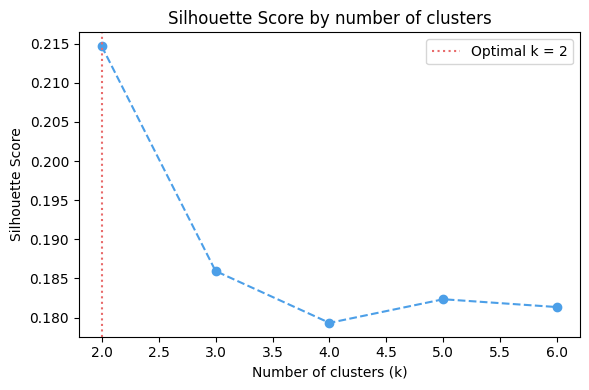

📊 Optimal number of clusters by silhouette: 2

📊 Cluster profiles (medians):


,N,valence,energy,danceability,acousticness,instrumentalness,tempo,Top genres
Cluster,,,,,,,,
1,399,0.118,0.347,0.532,0.639,0.627,112.494,"trip hop, downtempo, organic house, ambient, t..."
2,789,0.301,0.596,0.656,0.074,0.636,119.991,"downtempo, trip hop, organic house, tribal hou..."


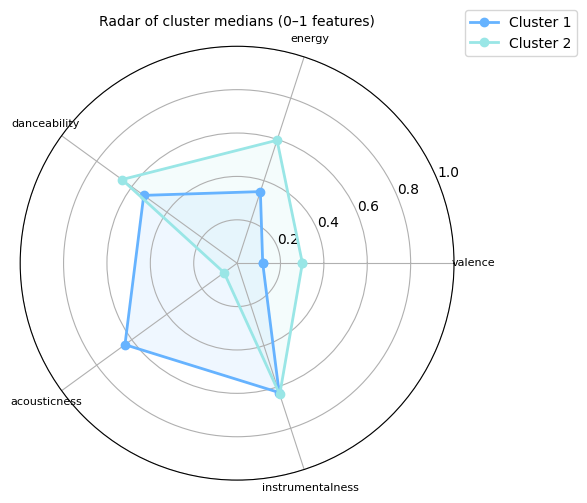

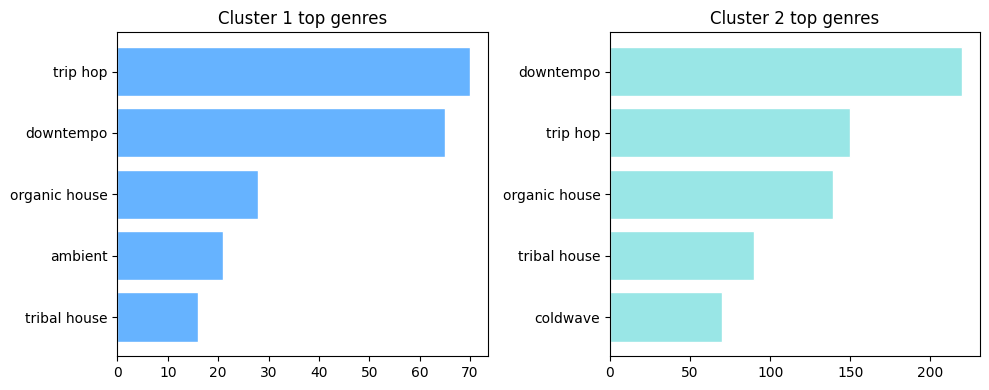

In [112]:
# 9.2 Кластеризация ядра, описание, визуализация

# KMeans с автоматическим выбором k по Silhouette Score.
# Визуализация: радар медиан, PCA-scatter, топ-жанры по кластерам,
# интерактивный 3D-scatter, violin по кластерам.

from sklearn.preprocessing import MinMaxScaler
import plotly.express as px

# Признаки для кластеризации
X = core[CLUSTER_FEATURES].copy()

# Стандартизация
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==========================================
# 1. Выбор k по Silhouette Score
# ==========================================
sil_scores = []
for k in K_RANGE:
    kmeans_tmp = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_tmp = kmeans_tmp.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels_tmp)
    sil_scores.append(score)

optimal_k = list(K_RANGE)[np.argmax(sil_scores)]

plt.figure(figsize=(6, 4))
plt.plot(list(K_RANGE), sil_scores, marker='o', linestyle='--', color=COLORS['line_primary'])
plt.axvline(x=optimal_k, color=COLORS['line_accent'], linestyle=':', label=f'Optimal k = {optimal_k}')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score by number of clusters')
plt.legend()
plt.tight_layout()
plt.show()

print(f'📊 Optimal number of clusters by silhouette: {optimal_k}\n')

# ==========================================
# 2. KMeans с оптимальным k
# ==========================================
kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
core['cluster'] = kmeans.fit_predict(X_scaled)

# ==========================================
# 3. Профили кластеров (медианы)
# ==========================================
cluster_summary = []
for cluster in sorted(core['cluster'].unique()):
    sub = core[core['cluster'] == cluster]
    med = sub[CLUSTER_FEATURES].median()
    genres = sub['genres_normalized'].str.split(',').explode().str.strip()
    genres = genres[~genres.isin(['unknown', 'UNTRANSLATED:', ''])]
    top_genres = genres.value_counts().head(5).index.tolist()
    cluster_summary.append({
        'Cluster': cluster + 1,
        'N': len(sub),
        **{f: med[f] for f in CLUSTER_FEATURES},
        'Top genres': ', '.join(top_genres)
    })

cluster_df = pd.DataFrame(cluster_summary).set_index('Cluster')
print('📊 Cluster profiles (medians):')
display(cluster_df.round(3))

# ==========================================
# 4. Радар медиан 0–1 + bar tempo
# ==========================================
radar_features_01 = ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(projection='polar'))
angles = np.linspace(0, 2 * np.pi, len(radar_features_01), endpoint=False).tolist()
angles += angles[:1]

cluster_colors = [COLORS['primary'], COLORS['secondary'], COLORS['success'],
                  COLORS['accent'], COLORS['muted']]

for i, cluster in enumerate(sorted(core['cluster'].unique())):
    vals = cluster_df.loc[cluster + 1, radar_features_01].astype(float).tolist()
    vals += vals[:1]
    color = cluster_colors[i % len(cluster_colors)]
    ax.plot(angles, vals, 'o-', linewidth=2, label=f'Cluster {cluster + 1}', color=color)
    ax.fill(angles, vals, alpha=0.1, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_features_01, fontsize=8)
ax.set_ylim(0, 1)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax.set_title('Radar of cluster medians (0–1 features)', fontsize=10)
plt.tight_layout()
plt.show()




# ==========================================
# 5. Топ-жанры по кластерам
# ==========================================
fig, axes = plt.subplots(1, optimal_k, figsize=(5 * optimal_k, 4), squeeze=False)
for i, cluster in enumerate(sorted(core['cluster'].unique())):
    sub = core[core['cluster'] == cluster]
    genres = sub['genres_normalized'].str.split(',').explode().str.strip()
    genres = genres[~genres.isin(['unknown', 'UNTRANSLATED:', ''])]
    top = genres.value_counts().head(5)
    ax = axes[0, i]
    ax.barh(top.index, top.values,
            color=cluster_colors[i % len(cluster_colors)], edgecolor='white')
    ax.set_title(f'Cluster {cluster + 1} top genres')
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

# ==========================================
# 6. Интерактивный 3D scatter
# ==========================================
core_viz = core.dropna(subset=['popularity']).copy()
core_viz['cluster_label'] = core_viz['cluster'] + 1

fig2 = px.scatter_3d(
    core_viz,
    x='valence', y='energy', z='danceability',
    color='cluster_label',
    size='popularity',
    hover_name='track_name',
    hover_data={
        'artist_name': True,
        'genres_normalized': True,
        'popularity': True,
        'cluster_label': True,
    },
    labels={
        'valence': 'Valence',
        'energy': 'Energy',
        'danceability': 'Danceability',
        'cluster_label': 'Cluster',
        'artist_name': 'Artist',
        'popularity': 'Popularity',
    },
    title='Taste core: 3D audio space',
    color_discrete_map={i + 1: cluster_colors[i % len(cluster_colors)]
                        for i in range(optimal_k)},
    opacity=0.85,
    height=650
)
fig2.update_traces(
    hovertemplate=(
        '<b>%{hovertext}</b><br>'
        'Artist: %{customdata[0]}<br>'
        'Genres: %{customdata[1]}<br>'
        'Popularity: %{customdata[2]}<br>'
        'Cluster: %{customdata[3]}'
    ),
    marker=dict(line=dict(color='black', width=0.3))
)
fig2.show()

# ==========================================
# 7. Violin по кластерам
# ==========================================
core['cluster_label'] = core['cluster'] + 1

fig3 = px.violin(
    core,
    x='cluster_label',
    y='valence',
    color='cluster_label',
    box=True,
    points='all',
    labels={'cluster_label': 'Cluster', 'valence': 'Valence'},
    title='Valence distribution by cluster',
    color_discrete_map={i + 1: cluster_colors[i % len(cluster_colors)]
                        for i in range(optimal_k)},
    height=500
)
fig3.update_traces(marker=dict(size=2, opacity=0.5))
fig3.show()

### 9.2. Вывод

**Что смотрели.** Кластеризацию ядра вкуса. KMeans по шести признакам (**valence**, **energy**, **danceability**, **acousticness**, **instrumentalness**, **tempo**), стандартизованным через `StandardScaler`. k выбирался по **Silhouette** в диапазоне 2–6.

**Silhouette.** Кривая падает резко: 0.215 при k=2, 0.186 при k=3, 0.179 при k=4, дальше полка. Максимум — k=2. Но абсолютное значение 0.215 ниже 0.25, то есть структура выражена слабо. График показывает не «два чётких кластера», а «два кластера — наименее плохой вариант среди проверенных».

**Кластеры.** Кластер 1 — 399 треков. Медианы: valence 0.118, energy 0.347, danceability 0.532, acousticness 0.639, instrumentalness 0.627, tempo 112.5. Кластер 2 — 789 треков. Медианы: valence 0.301, energy 0.596, danceability 0.656, acousticness 0.074, instrumentalness 0.636, tempo 120.0.

**Радар.** На графике видно, что кластеры различаются по трём осям: **valence**, **energy**, **acousticness**. По **instrumentalness** линии почти совпадают на высоком уровне — это общая черта обоих кластеров, а не различие. По **danceability** кластеры сближены, разрыв меньше, чем кажется по медианам.

**Жанры.** Топ-5 жанров у кластеров почти совпадает по составу: trip hop, downtempo, organic house. Но с разным весом. У кластера 1 trip hop на первом месте (около 70 треков), downtempo на втором. У кластера 2 downtempo резко выше (больше 200), trip hop на втором. То есть жанровое ядро одно, но акцент разный: кластер 1 тяготеет к trip hop, кластер 2 — к downtempo.

**Violin.** Распределение **valence** у кластера 1 сжато к нулю: медиана 0.118, верхний квартиль около 0.2, есть единичные выбросы до 0.8. У кластера 2 распределение шире: медиана 0.301, верхний квартиль 0.45, хвост до 1.0. Кластер 1 — почти плоский по valence, кластер 2 — с реальным разбросом. Это значит, что «меланхоличность» кластера 1 не среднее значение, а узкий диапазон: все треки примерно одинаково тихие.

**Вывод.** Кластеры различаются тремя признаками: **valence**, **energy**, **acousticness**. По **instrumentalness** и **tempo** — общие. Жанровое ядро одно — trip hop, downtempo, organic house. Кластер 1 — тише, акустичнее, меланхоличнее, с узким диапазоном valence. Кластер 2 — громче, танцевальнее, шире по valence. Это два состояния внутри одного жанрового поля, а не два разных вкуса.

**Ограничения.** Silhouette 0.215 — слабое разделение. Граница между кластерами размыта: треки в зоне перехода могут относиться к любому. Соотношение 399 к 789 — 1:2, неравномерно.

KMeans предполагает выпуклые кластеры примерно равного размера. Форма распределений на violin-графике — узкий кластер 1 и широкий кластер 2 — этому предположению не соответствует.

Устойчивость разбиения к смене `random_state` и подвыборкам не проверялась. `n_init=10` даёт устойчивость только к инициализации.

## 9.3 Характерные треки и итоговая интерпретация


In [113]:
# 9.3 Характерные треки и итоговая интерпретация

# Для каждого кластера — топ-N треков, ближайших к центру
# через cosine similarity. Это «эталонные представители» ядра.
#
# В конце — текстовая интерпретация каждого кластера.

# library_tracks из блока 0
if 'library_tracks' not in globals():
    library_tracks = pd.read_parquet(BASE_PATH / 'library_tracks.parquet')

# Подготовка источников треков
track_playlists = playlist_links.groupby('Track URI')['name_norm'].apply(list).to_dict()
library_uris = set(library_tracks['spotify_track_uri'])
all_playlist_uris = set(playlist_links['Track URI'])


def characteristic_tracks(cluster_id, top_n=TOP_CHARACTERISTIC):
    """Топ-N треков, ближайших к центру кластера через cosine similarity."""
    sub = core[core['cluster'] == cluster_id].copy()
    center = kmeans.cluster_centers_[cluster_id].reshape(1, -1)
    X_sub = X_scaled[core['cluster'] == cluster_id]
    cos_sims = cosine_similarity(X_sub, center).flatten()
    sub['cos_sim'] = cos_sims

    if cos_sims.max() != cos_sims.min():
        sub['similarity_pct'] = (
            (cos_sims - cos_sims.min()) / (cos_sims.max() - cos_sims.min()) * 100
        )
    else:
        sub['similarity_pct'] = 100.0

    top = sub.nlargest(top_n, 'cos_sim').copy()
    top['Playlists'] = top.index.map(lambda uri: ', '.join(track_playlists.get(uri, [])[:3]))
    top['Liked'] = top.index.map(lambda uri: '✅' if uri in library_uris else '—')
    top['Orphan'] = top.index.map(
        lambda uri: '✅' if uri not in all_playlist_uris and uri not in library_uris else '—'
    )
    return top[[
        'track_name', 'artist_name', 'genres_normalized',
        'similarity_pct', 'Playlists', 'Liked', 'Orphan'
    ] + CLUSTER_FEATURES]


for cluster in sorted(core['cluster'].unique()):
    display_cluster = cluster + 1
    print(f'\n🎯 Cluster {display_cluster}: characteristic tracks')
    display(characteristic_tracks(cluster).round(3))


# --- Итоговая интерпретация ---
print('\n🔍 Taste core summary:')
for cluster in sorted(core['cluster'].unique()):
    display_cluster = cluster + 1
    sub = core[core['cluster'] == cluster]
    med = sub[CLUSTER_FEATURES].median()
    genres = sub['genres_normalized'].str.split(',').explode().str.strip()
    genres = genres[~genres.isin(['unknown', 'UNTRANSLATED:', ''])]
    top_genres = genres.value_counts().head(5).index.tolist()

    if med['acousticness'] > 0.4:
        mood = 'melancholic, acoustic, with live instruments'
    elif med['instrumentalness'] > 0.5:
        mood = 'energetic, instrumental, with electronic textures'
    else:
        mood = 'melodic, balanced, with vocals and rhythmic base'

    print(f'\nCluster {display_cluster} (N={len(sub)}):')
    print(f'  Medians: valence {med["valence"]:.2f}, energy {med["energy"]:.2f}, '
          f'danceability {med["danceability"]:.2f}')
    print(f'  acousticness {med["acousticness"]:.2f}, '
          f'instrumentalness {med["instrumentalness"]:.2f}, '
          f'tempo {med["tempo"]:.0f} BPM')
    print(f'  Genre core: {", ".join(top_genres)}')
    print(f'  Character: {mood}.')


🎯 Cluster 1: characteristic tracks


,track_name,artist_name,genres_normalized,similarity_pct,Playlists,Liked,Orphan,valence,energy,danceability,acousticness,instrumentalness,tempo
spotify_track_uri,,,,,,,,,,,,,
spotify:track:4B9CpNudr5kVP8Hgu7rQw5,Moog Island,Morcheeba,"trip hop, downtempo",100.000,"2025, personal_identity_03",—,—,0.070,0.242,0.369,0.877,0.521,109.860
spotify:track:45xEF694NNQ60UmiLi8y20,Baby Brown Eyes,Christian Cohle,unknown,97.267,"2025, personal_identity_03, liked_songs",✅,—,0.071,0.334,0.385,0.836,0.491,117.626
spotify:track:1sWb1Hr4bFWR2w2SqU512K,You are Beautiful,Common Saints,retro soul,96.086,"2025, personal_state_01, personal_relationship_05",—,—,0.076,0.053,0.281,0.960,0.227,125.704



🎯 Cluster 2: characteristic tracks


,track_name,artist_name,genres_normalized,similarity_pct,Playlists,Liked,Orphan,valence,energy,danceability,acousticness,instrumentalness,tempo
spotify_track_uri,,,,,,,,,,,,,
spotify:track:3oeCLmDyhIWkaYZIMcKqyE,i killed you in my dream,ORR,"darkwave, coldwave, post-punk, gothic rock",100.000,"2026, liked_songs, ringleader",✅,—,0.435,0.695,0.667,0.018,0.523,130.014
spotify:track:3yP9qF4lgHHmcnW6bwaEnk,Porcelain,Baxter Dury,unknown,99.361,"2026, personal_identity_03, liked_songs",✅,—,0.364,0.637,0.683,0.006,0.466,115.991
spotify:track:19Q9ucDAtEfQxpb6R2Istg,Drift Away - Alex Hook Remix,Mika Olson,"deep house, nu disco, lounge",97.837,"2025, 🌊🌊🌊waves",—,—,0.490,0.854,0.778,0.001,0.433,115.023



🔍 Taste core summary:

Cluster 1 (N=399):
  Medians: valence 0.12, energy 0.35, danceability 0.53
  acousticness 0.64, instrumentalness 0.63, tempo 112 BPM
  Genre core: trip hop, downtempo, organic house, ambient, tribal house
  Character: melancholic, acoustic, with live instruments.

Cluster 2 (N=789):
  Medians: valence 0.30, energy 0.60, danceability 0.66
  acousticness 0.07, instrumentalness 0.64, tempo 120 BPM
  Genre core: downtempo, trip hop, organic house, tribal house, coldwave
  Character: energetic, instrumental, with electronic textures.


### 9.3. Вывод

**Что смотрели.** Характерные треки каждого кластера — ближайшие
к центроиду по **cosine similarity**. Это эталонные представители
ядра, не случайная выборка.

**Кластер 1.** 399 треков. Медианы: valence 0.12, energy 0.35,
danceability 0.53, acousticness 0.64, instrumentalness 0.63,
tempo 112 BPM. Жанры: trip hop, downtempo, organic house, ambient,
tribal house. Профиль — меланхоличный, акустический, с живыми
инструментами.

**Кластер 2.** 789 треков. Медианы: valence 0.30, energy 0.60,
danceability 0.66, acousticness 0.07, instrumentalness 0.64,
tempo 120 BPM. Жанры: downtempo, trip hop, organic house,
tribal house, coldwave. Профиль — энергичный, инструментальный,
с электронными текстурами.

**Жанровое ядро общее.** downtempo, trip hop, organic house
присутствуют в обоих кластерах. Различие не в жанре, а в
интенсивности: кластер 1 — тише, акустичнее, медленнее.
Кластер 2 — громче, танцевальнее, электроннее. Это два состояния
внутри одной музыкальной зоны, а не два разных направления.

**Связь с 01_eda_basic.** Бимодальность acousticness и
instrumentalness, найденная в `01_eda_basic`, блок 8, на ядре
вкуса воспроизводится частично. Кластеры различаются по
acousticness (0.64 против 0.07), а по instrumentalness почти
не расходятся (0.63 против 0.64). То есть разделение на две
группы подтверждается, но не по обеим осям бимодальности сразу —
только по acousticness.

**Характерные треки.** Каждый кластер представлен пятью эталонными
треками, ближайшими к центроиду. Колонки `Playlists`, `Liked`,
`Orphan` показывают, где трек встречается в коллекции. Треки-сироты —
те, что прослушивались, но не попали ни в один плейлист.

**Ограничения.** Silhouette 0.215 — ниже порога 0.25. Структура
выражена слабо: граница между кластерами размыта. Разбиение стоит
читать как описательное, а не как статистически доказанное.

Характерные треки выбраны через **cosine similarity**. Эта метрика
чувствительна к направлению, а не к расстоянию: трек может быть
«эталонным» по профилю, но далёким от центра по абсолютным значениям.

Описание кластеров условное. В коде профиль определяется
последовательными проверками: если `acousticness > 0.4` — кластер
называется «melancholic» независимо от остальных признаков.
Для кластера 1 это даёт только одну характеристику — acousticness
0.64, хотя instrumentalness у него тоже высокая (0.63). В название
она не попадает. Кластер 2 идёт во вторую ветку (acousticness 0.07,
instrumentalness 0.64) и получает «energetic, instrumental».

## Блок 9. Вывод

**Tempo.** В этом ноутбуке (блок 9.2) шесть признаков дают
Silhouette 0.215 при k=2 — ниже порога 0.25 по Kaufman & Rousseeuw.
Это означает слабую структуру: разбиение описательное, не
статистически доказанное.

В финальной версии модуля `src/clustering/` те же данные считаются
на пяти признаках без `tempo` и дают Silhouette 0.264. Разница —
tempo: он измеряется в BPM (0–250) против 0–1 у остальных признаков
и остаётся шумным даже после `StandardScaler`. У треков одного
настроения BPM может различаться на десятки единиц. Без tempo
границы между кластерами становятся чётче.

Сравнение через `src/clustering/`: 0.215 и 0.264 относятся к разным
реализациям, не к одной. Здесь — ранняя версия, в модуле — финальная.

**Переход в дашборд.** В модуле (`src/clustering/`) ядро считается
иначе. Не пересечение добавленного и прослушанного, а пересечение
**valid_play** и **my_music**: трек не обязан быть недавно
добавленным, достаточно, чтобы он слушался в окне. Окон три:
**global**, **recent_6q**, **last_90d**. Модель обучается один раз
на **global** и применяется к остальным — иначе кластеры между
окнами несравнимы. Характерные треки в модуле ищутся по евклидову
расстоянию, а не по **cosine similarity**. Добавлен порог
`MIN_SILHOUETTE = 0.25` и флаг `passed`. Результаты сохраняются
в parquet.

**Смена задачи.** Ноутбук разведывал структуру: есть ли она, какая,
из чего. Модуль фиксирует версию для дашборда: пять признаков,
три окна, порог, сохранение. Ядро изменилось не потому, что первое
было неверным, а потому что дашборд отвечает на другой вопрос —
не «что я недавно сохранил и слушаю», а «что я слушаю из своего».

**Связка с дашбордом.** Блок 9 заканчивает ноутбук. Дальше
результаты идут в `03_dashboard/`: ядро вкуса, портрет слушателя,
динамика по окнам. Разрыв между ноутбуком и дашбордом — это смена
задачи, а не исправление ошибок.

# Итог ноутбука

296 плейлистов: **personal** 128, **foreign** 138,
**collaborative** 29, **contributed** 1. Коллекция современная:
91.6% плейлистов принадлежат 2020-м или 2010-м. Жанрово плотные,
артистически широкие: медиана `genre_diversity` 0.460,
`artist_diversity` 0.833.

**Типы наполнения.** **Curated** — 87 плейлистов (55.4%),
**batch** — 55 (35.0%), **mass_import** — 15 (9.6%).
Mass_import встречается только в 2020 — стартовая стратегия
первого года. С 2021 доля curated держится 85–100%.
Способ наполнения связан с содержанием: mass_import — trance
и progressive trance (9.6% и 9.4% тегов), energy 0.695,
acousticness 0.033; curated — downtempo (10.0%), organic house
(5.7%), energy 0.509, acousticness 0.259. Jaccard между типами
ниже 0.1 у всех пар.

**Активность.** Медиана `days_since_update` — 1785 дней.
Заброшенных по обновлению (>365 дней) — 70.7%, но 24.8%
из них продолжают накапливать прослушивания. Personal даёт
29 618 валидных прослушиваний при медиане 505 на плейлист,
collaborative — 22 509 при медиане 41.

**Мёртвый груз.** Медиана широты прослушивания: 10.4%
у mass_import, 9.5% у batch, 85.7% у curated. Медиана глубины:
2.24 и 2.00 против 6.03. Массовый перенос и пакетное копирование
не оживают — их почти не открывают.

**Повторы.** 22.7% треков встречаются в 2+ собственных плейлистах.
У повторяющихся выше доли downtempo (13.2% против 7.0%) и trip hop
(11.5% против 5.4%), ниже energy (0.520 против 0.587), выше
acousticness (0.220 против 0.130). 54.3% повторов живут только
в curated, ещё 31.1% — в комбинациях с curated. 44.9% повторов
добавлены в разные плейлисты в один день — механический повтор,
не «любимый трек».

**Совместные плейлисты.** Форма collaborative не отражает
содержание: внешнее участие — один пользователь с двадцатью
добавлениями из 3532. Наполняются нашими аккаунтами, доминирует
один. Contributed — один плейлист, все треки которого уже есть
в personal. Как отдельная категория не работает.

**Own vs foreign.** Различаются содержанием, но не поведением.
Own жанрово разнообразнее (0.528 против 0.351) и смещён к 2010-м
(0.432 против 0.294). Foreign свежее (0.598 против 0.289 по 2020-м).
По `skip_rate`, `median_played_frac` и `full_play_share` различий
нет (p > 0.2).

**Ядро вкуса.** 1188 треков — пересечение добавленного и
прослушанного за шесть кварталов. 78% от добавленного за окно,
19% от прослушанного за окно. KMeans с Silhouette выбрал k=2
со значением 0.215 — ниже порога 0.25, структура выражена слабо.

- **Кластер 1** (399 треков): valence 0.12, energy 0.35,
  acousticness 0.64, instrumentalness 0.63, tempo 112 BPM.
  Жанры: trip hop, downtempo, organic house, ambient.
- **Кластер 2** (789 треков): valence 0.30, energy 0.60,
  acousticness 0.07, instrumentalness 0.64, tempo 120 BPM.
  Жанры: downtempo, trip hop, organic house, tribal house, coldwave.

Жанровое ядро общее. Различие — в интенсивности и акустичности.

**Связь с 01_eda_basic.** Бимодальность acousticness и
instrumentalness из блока 8 первого ноутбука на ядре
воспроизводится частично: кластеры различаются по acousticness
(0.64 против 0.07), но не по instrumentalness (0.63 против 0.64).
Разделение на две группы подтверждается, но только по одной
оси из двух.

**Переход в дашборд.** В `src/clustering/` ядро считается иначе:
пять признаков без tempo, три окна (global, recent_6q, last_90d),
евклидово расстояние, `MIN_SILHOUETTE = 0.25`. Ноутбук разведывал
структуру, модуль фиксирует версию для дашборда.

## Что не подтвердилось

**Социальность совместных плейлистов.** Внешнее участие —
один пользователь с 20 добавлениями. Collaborative наполняются
нашими аккаунтами.

**Устойчивость двух ядер.** Silhouette 0.215 ниже порога 0.25.
Разбиение описательное, граница размыта.

**Заброшенность как синоним неслушания.** 39 заброшенных
плейлистов продолжают слушаться.

**Вовлечённость как различитель own vs foreign.** По трём
метрикам вовлечённости группы не различаются (p > 0.2).

## Ограничения

Выборка — история одного человека. Выводы описывают этот профиль,
не слушателей вообще.

**Unknown** в жанрах — от 20% до 40% в разных срезах. Жанровые
выводы ограничены этой долей.

Пороги классификации — эвристики: 100 треков и 15 минут для
mass_import, 2 минуты для batch, 30% прослушивания до добавления,
CV 0.5 и 1.5 для подгрупп curated. Не выведены из данных.

`days_since_update` считается от максимальной `last_modified`
в датасете, а не от даты сбора. Оценка заброшенности смещена
вверх.

**Valid_play** требует `played_frac ≥ 0.5`. Метрики вовлечённости
смещены к высоким значениям.

Правый край истории обрезан: 2026 — неполный год. Когорты
в 6.7 и 6.8 малы — от одной до девяти единиц.

Все сравнения проходят без поправки на множественные сравнения.

Маскирование идентификаторов выполнено до анализа. Исходные
значения недоступны.